In [1]:
import nibabel as nib
import matplotlib.pyplot as plt
import numpy as np
import os
from scipy.ndimage import rotate
import pydicom
import shutil
import pandas as pd
import pymedphys

In [4]:
pip install interpolation

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


### Test gamma pass rate

In [2]:
dose_ref_path = r"\\klient.uib.no\felles\LAB-IT\IFT\Medisinskfysikk\Anna\adaptive-weekly\Adaptive_weekly_5\dose_simulations\planning\FLUKA_cagr_HN_weekly_5_01_IMPT_Anna\01_310\Results_spot_24\BNNLIS\FLUKA_DICOM\dose\FLK_Phys-dose1.0_cagr_HN_weekly_5_01_IMPT_Anna_01_310_u.dcm"
dose_eval_path = r"\\klient.uib.no\felles\LAB-IT\IFT\Medisinskfysikk\Anna\adaptive-weekly\Adaptive_weekly_5\dose_simulations\w2\FLUKA_cagr_HN_weekly_5_01_IMPT_Anna\01_310\Results_spot_24\BNNLIS\FLUKA_DICOM\dose\FLK_Phys-dose1.0_cagr_HN_weekly_5_01_IMPT_Anna_01_310_u.dcm"

dose_ref = pydicom.dcmread(dose_ref_path).pixel_array
dose_eval = pydicom.dcmread(dose_eval_path).pixel_array

In [ ]:
dose_ref_ = np.transpose(dose_ref, axes = (2, 1, 0))
dose_eval_ = np.transpose(dose_eval, axes = (2, 1, 0))

dx = 1
dy = 1 
dz = 3

nx, ny, nz = dose_ref_.shape

print(nx,ny,nz)

x = np.arange(nx) * dx
y = np.arange(ny) * dy
z = np.arange(nz) * dz

gamma = pymedphys.gamma(
    axes_reference=(x, y, z),
    dose_reference=dose_ref_,

    axes_evaluation=(x, y, z),
    dose_evaluation=dose_eval_,

    dose_percent_threshold=3,      # 3%
    distance_mm_threshold=3,       # 3 mm

    lower_percent_dose_cutoff=10,  # ignore voxels <10% max dose
    local_gamma=False              # global gamma
)



573 315 117


FileNotFoundError: [Errno 2] No such file or directory: 'C:\\Users\\amibe\\AppData\\Local\\Programs\\Python\\Python313\\Lib\\lib\\pymedphys\\dependency-extra.txt'

In [33]:

mask_path_plan = r"d:\Adaptiv-weekly\CT_and_masks\planning\testing_resampling_to_dose.nii.gz"
binary_mask_plan = nib.load(mask_path_plan).get_fdata()
binary_mask_plan = np.transpose(binary_mask_plan, axes = (2, 1, 0))

mask_path_c2 = r"d:\Adaptiv-weekly\CT_and_masks\w2\binary_mask_resampled_to_match_pCT.nii.gz"
#r"d:\Adaptiv-weekly\CT_and_masks\w2\binary_mask_resampled_to_dose\testing_resampling_to_dose.nii.gz"
binary_mask_c2 = nib.load(mask_path_c2).get_fdata()
binary_mask_c2 = np.transpose(binary_mask_c2, axes = (2, 1, 0))

mask_path_c3 = r"d:\Adaptiv-weekly\CT_and_masks\w3\binary_mask_resampled_to_match_pCT.nii.gz"
binary_mask_c3 = nib.load(mask_path_c3).get_fdata()
binary_mask_c3 = np.transpose(binary_mask_c3, axes = (2, 1, 0))

mask_path_c4 = r"d:\Adaptiv-weekly\CT_and_masks\w4\binary_mask_resampled_to_match_pCT.nii.gz"
binary_mask_c4 = nib.load(mask_path_c4).get_fdata()
binary_mask_c4 = np.transpose(binary_mask_c4, axes = (2, 1, 0))

mask_path_c5 = r"d:\Adaptiv-weekly\CT_and_masks\w5\binary_mask_resampled_to_match_pCT.nii.gz"
binary_mask_c5 = nib.load(mask_path_c5).get_fdata()
binary_mask_c5 = np.transpose(binary_mask_c5, axes = (2, 1, 0))

mask_path_c6 = r"d:\Adaptiv-weekly\CT_and_masks\w6\binary_mask_resampled_to_match_pCT.nii.gz"
binary_mask_c6 = nib.load(mask_path_c6).get_fdata()
binary_mask_c6 = np.transpose(binary_mask_c6, axes = (2, 1, 0))


In [3]:
def rotate_array(dose_array, binary_mask, angle):
    dose_array_rotated = rotate(
                 dose_array*binary_mask,
                 angle=angle,
                 axes=(1, 2),   # rotate in the y-x plane
                 #reshape = True
                 reshape=False, 
                 order = 1
             )

    return dose_array_rotated


def find_angle(dat_file):
    with open(dat_file, "r") as f:
        lines = f.readlines()
        elements = lines[3].split()

    return np.degrees(np.arccos(float(elements[8])))
        

In [10]:
def find_d80_diff(arr1, arr2):
    d80_ref = 0.8*np.max(arr1)
    d80_ref_indeces = np.where(arr1 > d80_ref)[0]

    d80_comp = 0.8*np.max(arr2)
    d80_comp_indeces = np.where(arr2 > d80_comp)[0]

    return d80_comp_indeces[-1] - d80_ref_indeces[-1] 

def find_d20_diff(arr1, arr2):
    d20_ref = 0.2*np.max(arr1)
    d20_ref_indeces = np.where(arr1 > d20_ref)[0]

    d20_comp = 0.2*np.max(arr2)
    d20_comp_indeces = np.where(arr2 > d20_comp)[0]
    
    return d20_comp_indeces[-1] - d20_ref_indeces[-1]

def find_dmax_diff(arr1, arr2):
    max_idx_ref =  np.unravel_index(np.argmax(arr1), arr1.shape)[0]
    max_idx_comp =  np.unravel_index(np.argmax(arr2), arr2.shape)[0]

    return max_idx_comp - max_idx_ref

def find_setup_diff(arr1, arr2):
    indeces_set_up_ref = np.where(arr1 > 0.20*max(arr1))[0]
    indeces_set_up_comp = np.where(arr2 > 0.20*max(arr1))[0]

    return indeces_set_up_comp[0] - indeces_set_up_ref[0]

def find_all_dose_metrics(arr1, arr2): 
    d80_arr2_arr1 = find_d80_diff(arr1, arr2)
    d20_arr2_arr1 = find_d20_diff(arr1, arr2)
    dmax_arr2_arr1 = find_dmax_diff(arr1, arr2)
    setup_arr2_arr1 = find_setup_diff(arr1, arr2)

    return d80_arr2_arr1, d20_arr2_arr1, dmax_arr2_arr1, setup_arr2_arr1 


### Save to file

0
Results_spot_27


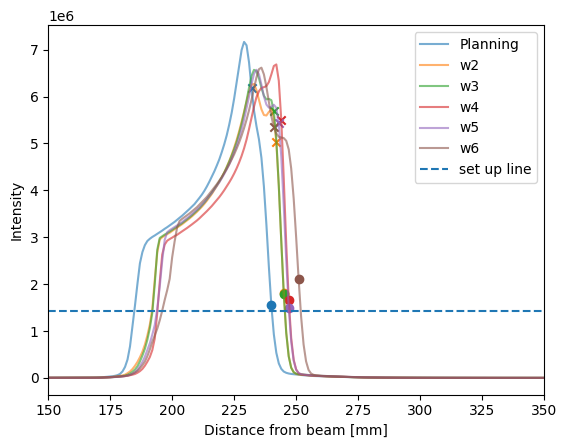

1
Results_spot_28


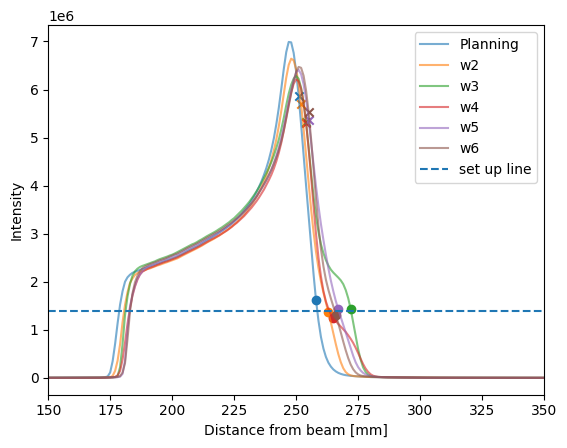

2
Results_spot_29


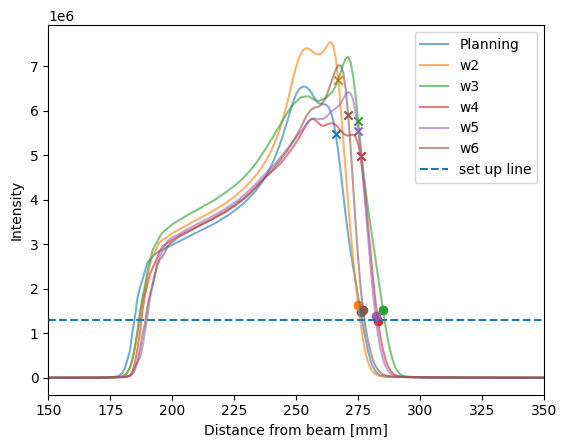

3
Results_spot_3


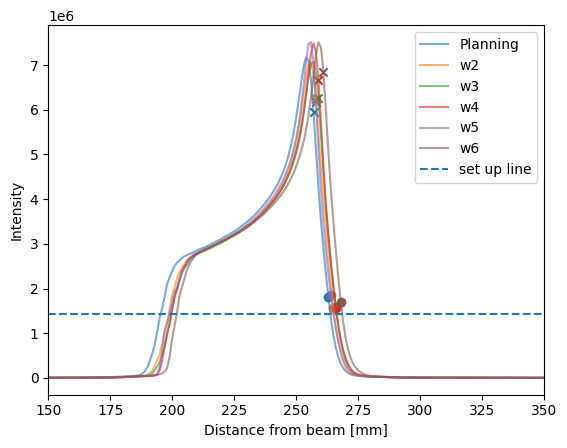

4
Results_spot_30


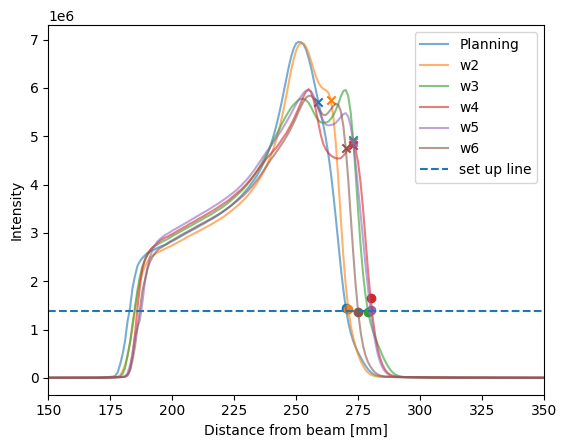

5
Results_spot_31


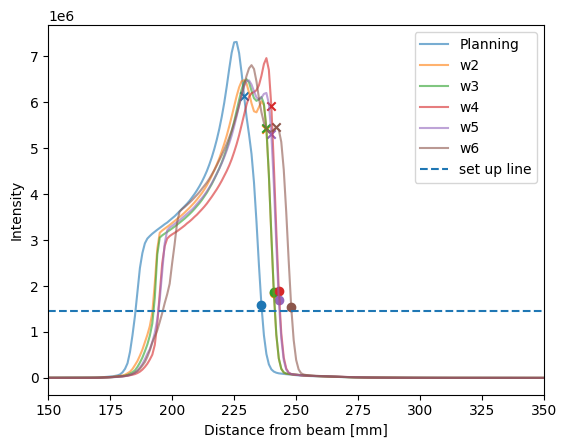

6
Results_spot_32


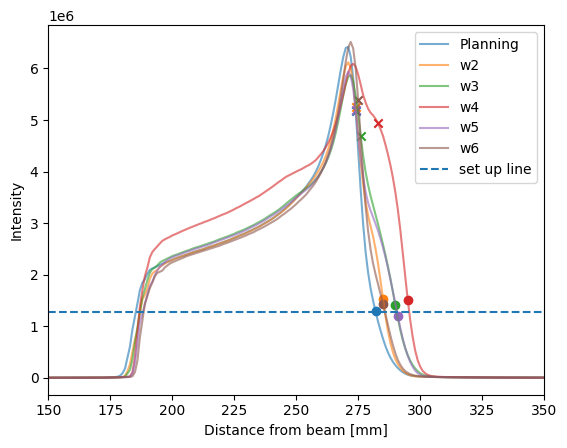

7
Results_spot_33


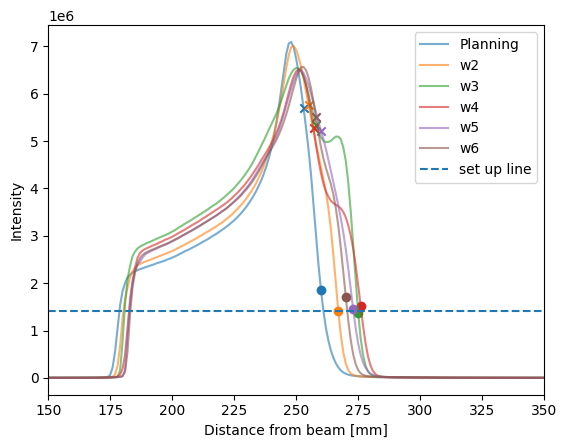

8
Results_spot_34


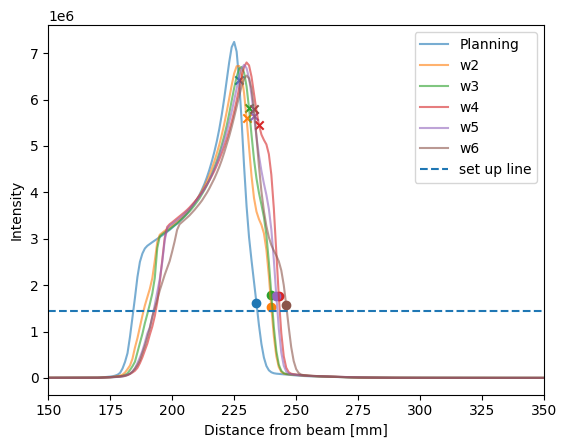

9
Results_spot_35


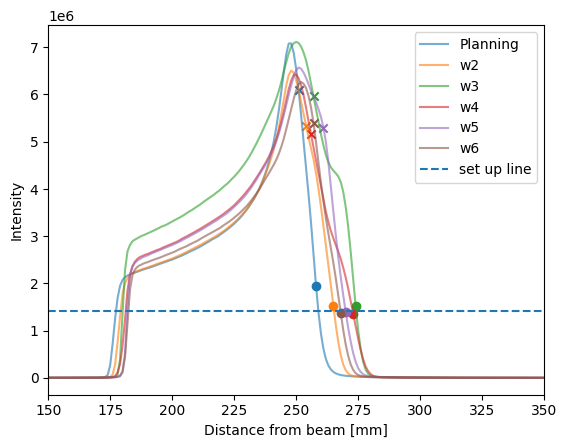

10
Results_spot_36


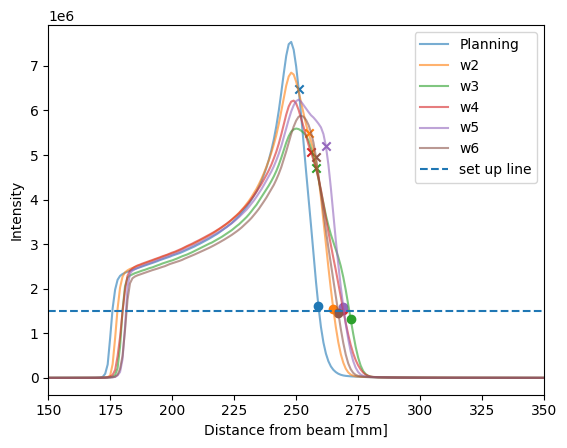

11
Results_spot_37


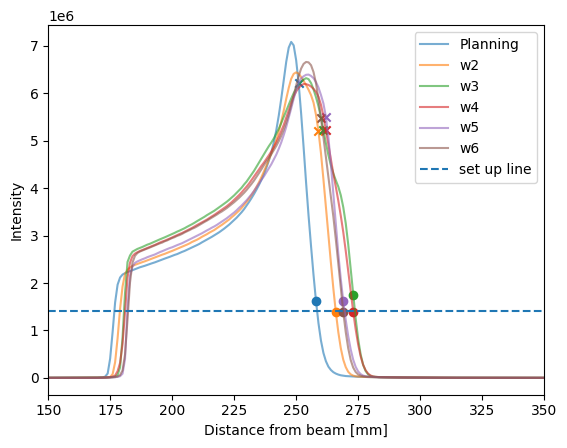

12
Results_spot_38


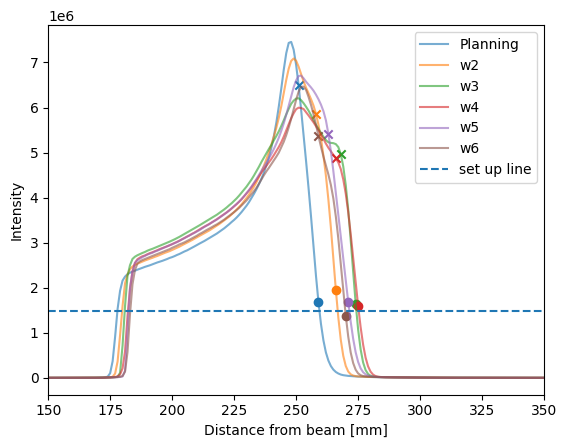

13
Results_spot_39


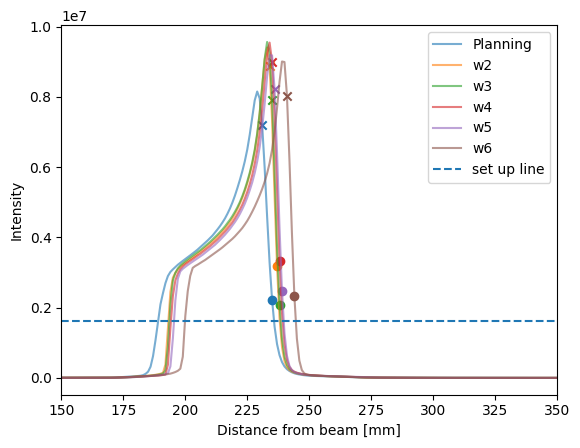

14
Results_spot_4


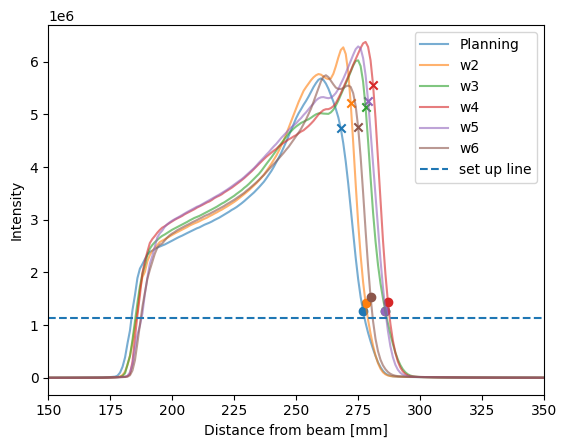

15
Results_spot_40


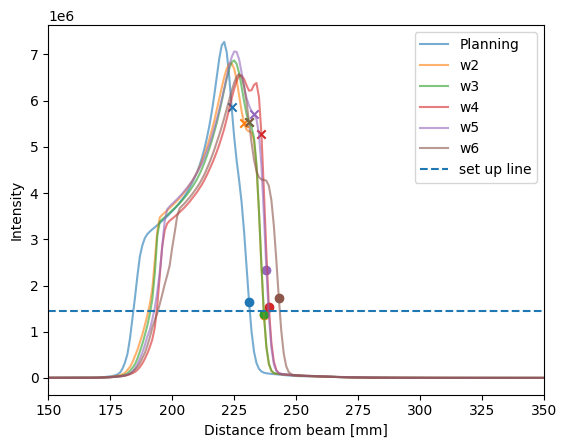

16
Results_spot_41


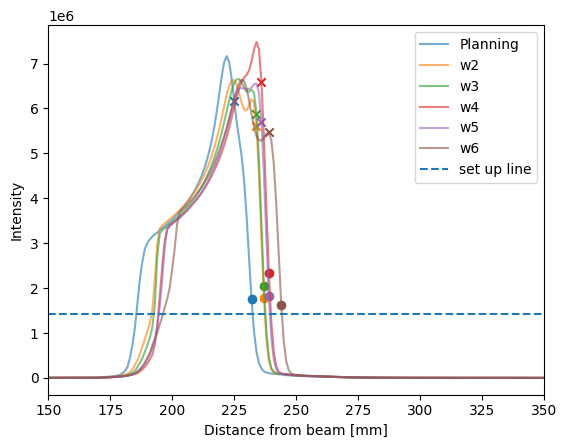

17
Results_spot_42


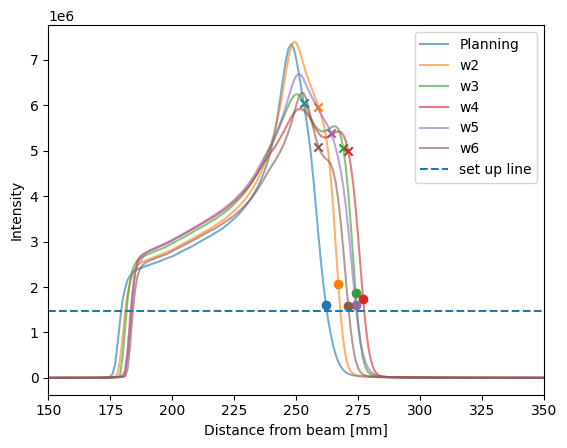

18
Results_spot_43


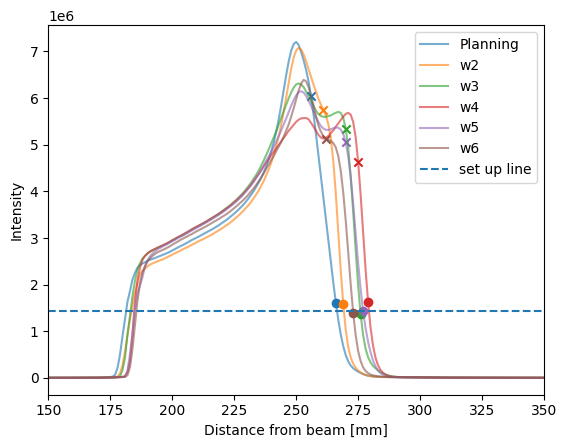

19
Results_spot_44


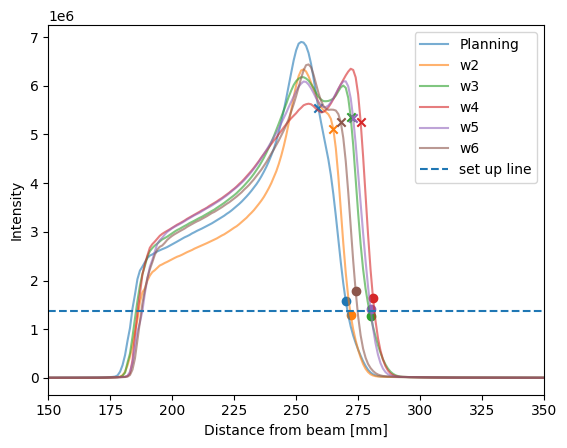

20
Results_spot_45


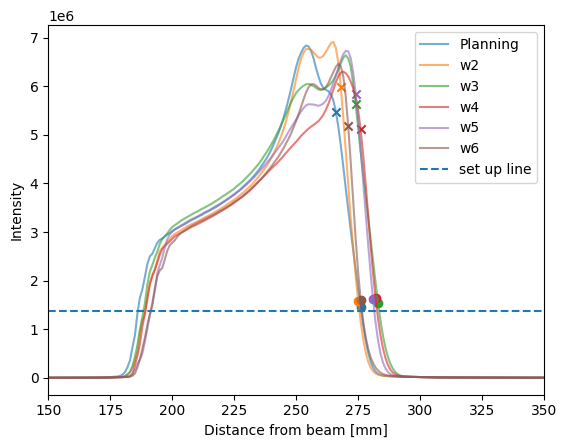

21
Results_spot_46


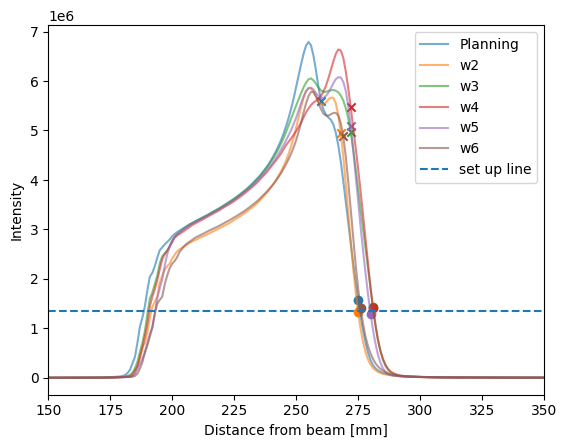

22
Results_spot_47


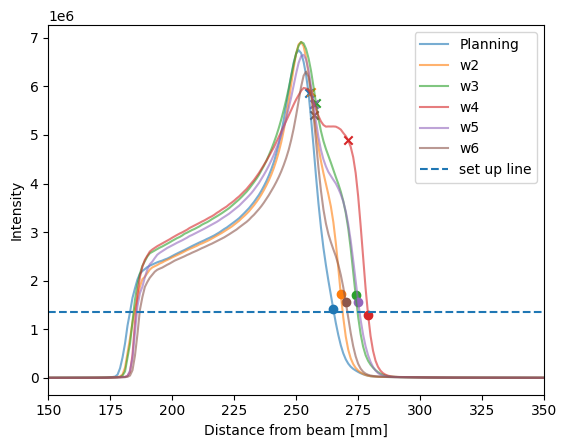

23
Results_spot_48


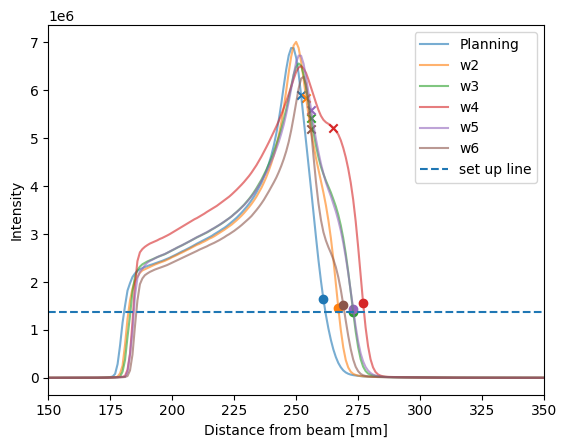

24
Results_spot_49


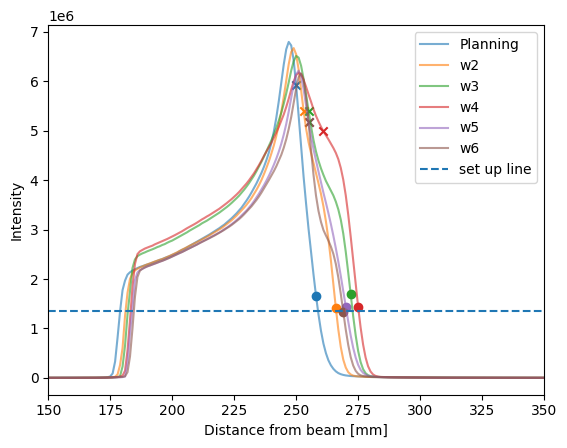

25
Results_spot_5


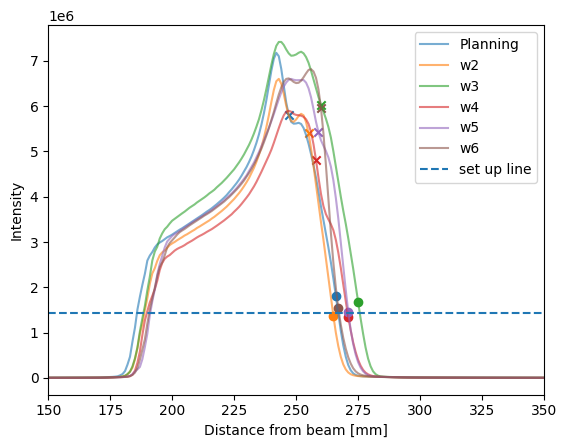

26
Results_spot_50


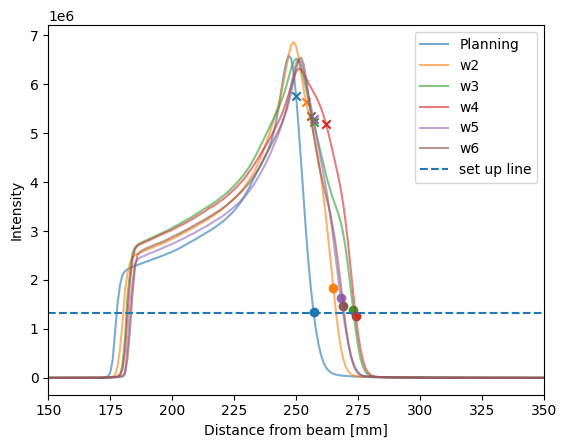

27
Results_spot_51


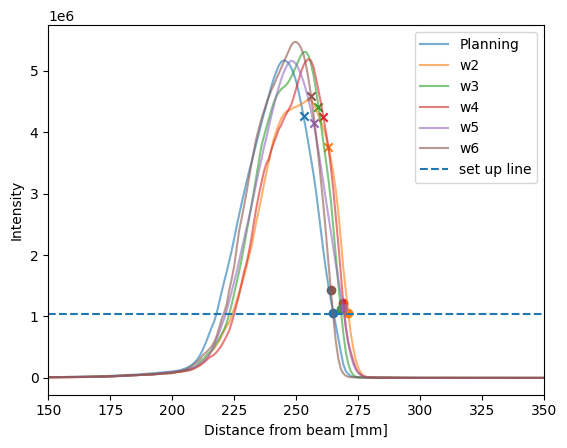

28
Results_spot_52


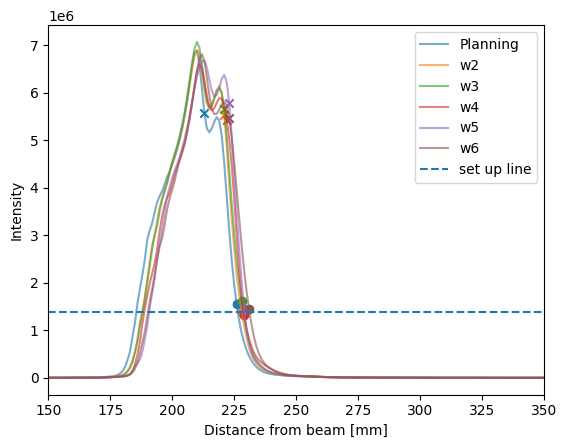

29
Results_spot_53


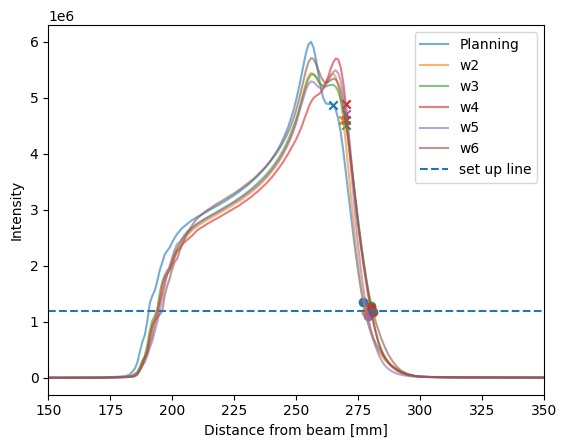

30
Results_spot_54


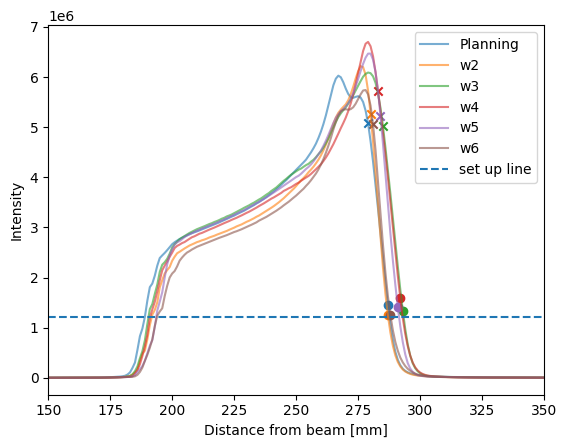

31
Results_spot_55


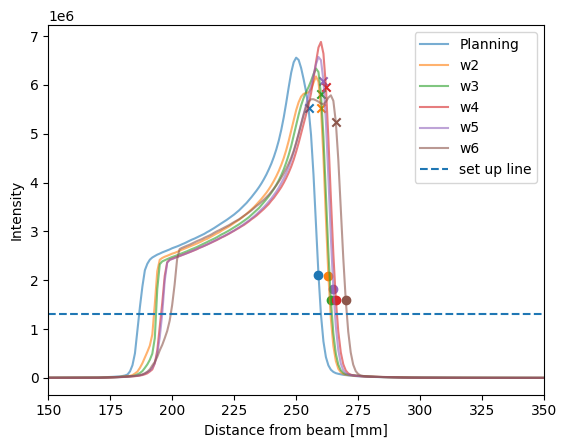

32
Results_spot_56


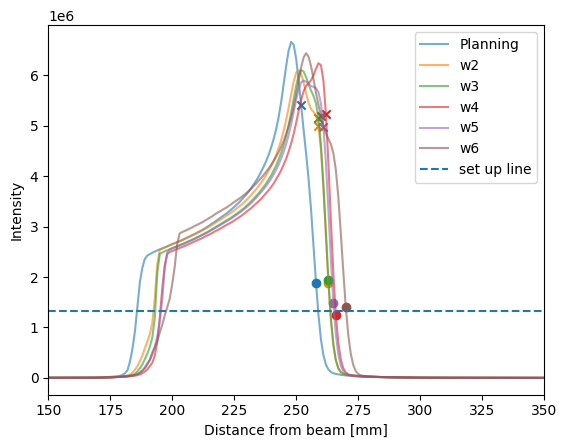

33
Results_spot_57


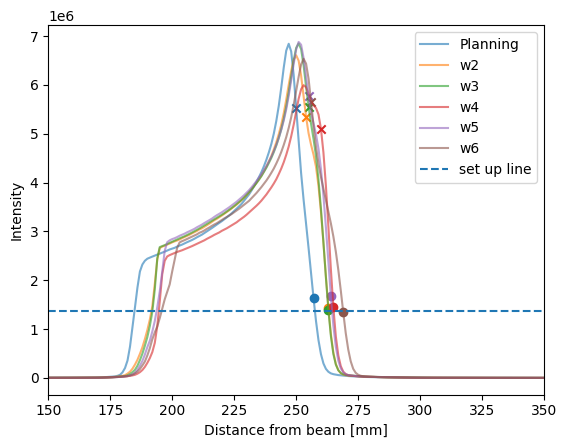

34
Results_spot_58


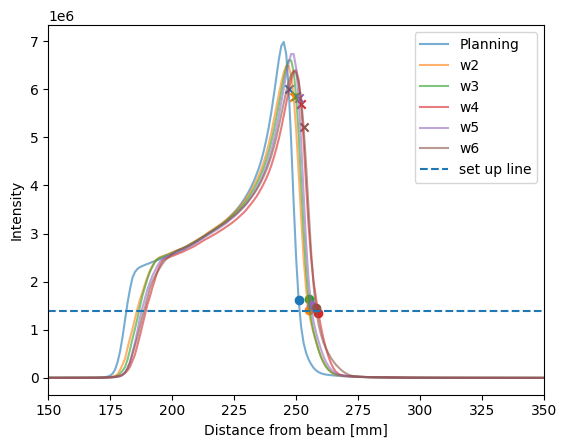

35
Results_spot_59


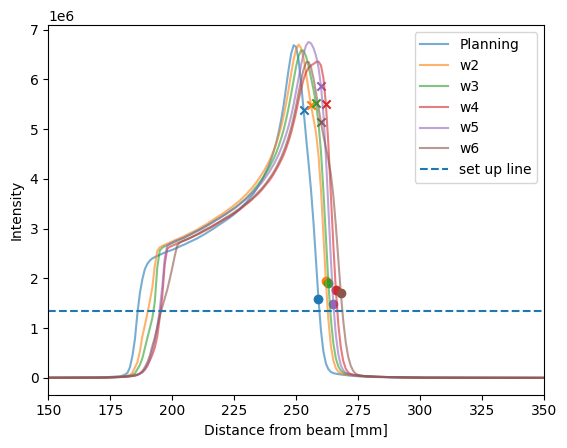

36
Results_spot_6


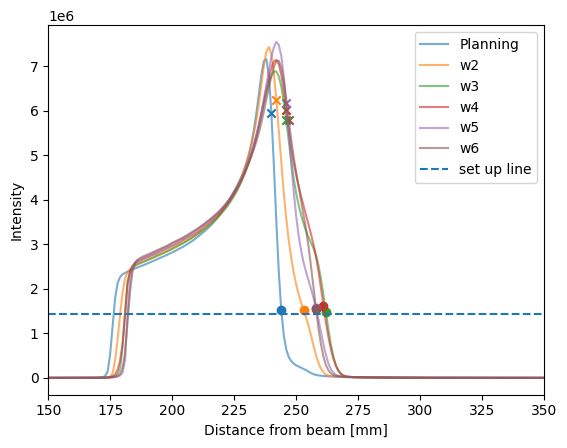

37
Results_spot_60


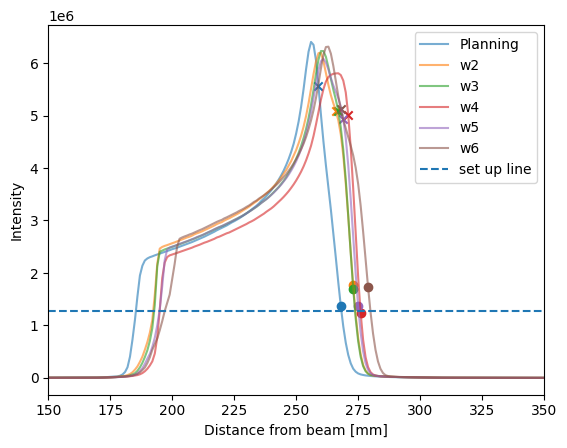

38
Results_spot_61


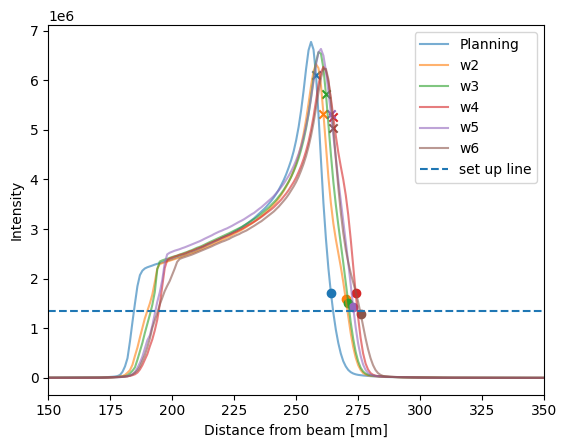

39
Results_spot_62


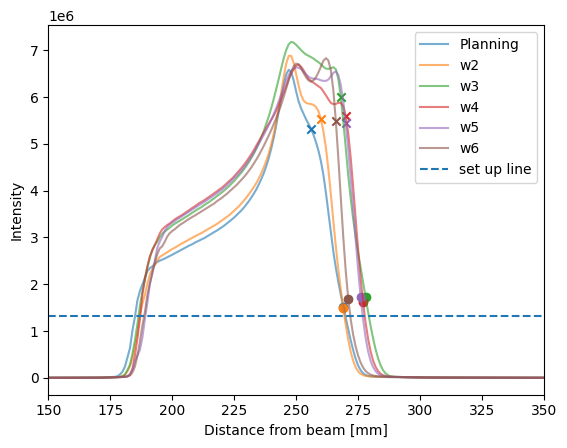

40
Results_spot_63


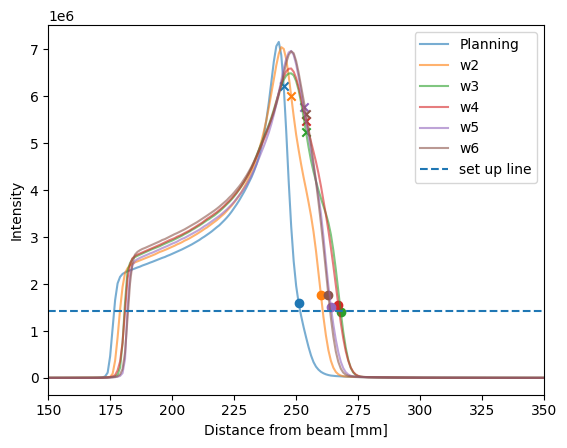

41
Results_spot_7


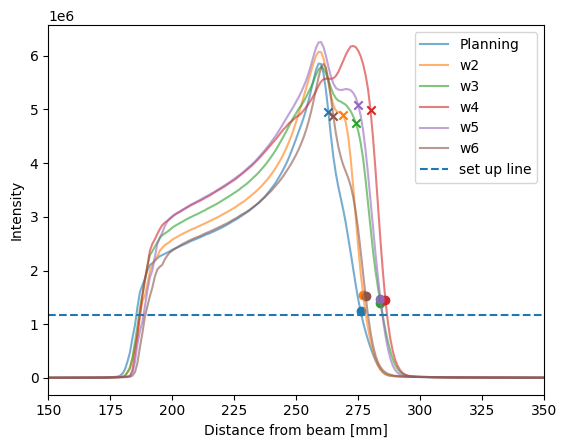

42
Results_spot_8


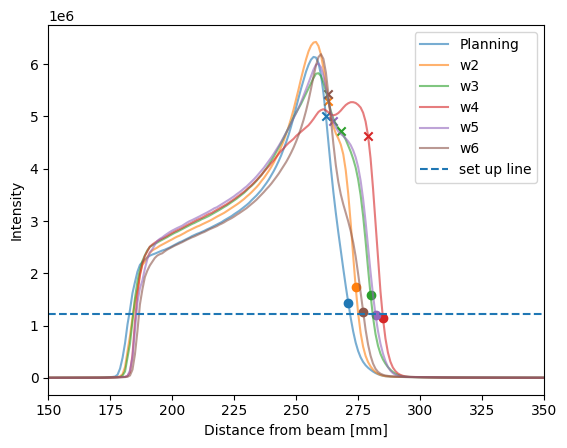

43
Results_spot_9


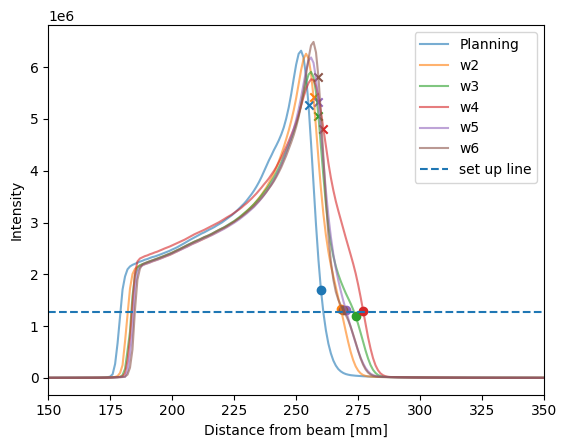

44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
87
88
89
90
91
92
93
94
95
96
97
98
99
100
101
102
103
104
105
106
107
108
109
110
111
112
113
114
115
116


In [11]:
overall_planning_file = r"\\klient.uib.no\felles\LAB-IT\IFT\Medisinskfysikk\Anna\adaptive-weekly\Adaptive_weekly_5\dose_simulations\planning\FLUKA_cagr_HN_weekly_5_01_IMPT_Anna\01_310"
overall_w2_file = r"\\klient.uib.no\felles\LAB-IT\IFT\Medisinskfysikk\Anna\adaptive-weekly\Adaptive_weekly_5\dose_simulations\w2\FLUKA_cagr_HN_weekly_5_01_IMPT_Anna\01_310"
overall_w3_file = r"\\klient.uib.no\felles\LAB-IT\IFT\Medisinskfysikk\Anna\adaptive-weekly\Adaptive_weekly_5\dose_simulations\w3\FLUKA_cagr_HN_weekly_5_01_IMPT_Anna\01_310"
overall_w4_file = r"\\klient.uib.no\felles\LAB-IT\IFT\Medisinskfysikk\Anna\adaptive-weekly\Adaptive_weekly_5\dose_simulations\w4\FLUKA_cagr_HN_weekly_5_01_IMPT_Anna\01_310"
overall_w5_file = r"\\klient.uib.no\felles\LAB-IT\IFT\Medisinskfysikk\Anna\adaptive-weekly\Adaptive_weekly_5\dose_simulations\w5\FLUKA_cagr_HN_weekly_5_01_IMPT_Anna\01_310"
overall_w6_file = r"\\klient.uib.no\felles\LAB-IT\IFT\Medisinskfysikk\Anna\adaptive-weekly\Adaptive_weekly_5\dose_simulations\w6\FLUKA_cagr_HN_weekly_5_01_IMPT_Anna\01_310"


planning_files = os.listdir(overall_planning_file)

i = 0

for planning_file in planning_files[98:]:
    print(i)
    i+=1
    if "Results" in planning_file:
        print(planning_file)
        rows = []
        dose_path_planning = overall_planning_file + "/" + planning_file + r"\BNNLIS\FLUKA_DICOM\dose\FLK_Phys-dose1.0_cagr_HN_weekly_5_01_IMPT_Anna_01_310_u.dcm"
        dose_path_w2  = overall_w2_file + "/"  + planning_file + r"\BNNLIS\FLUKA_DICOM\dose\FLK_Phys-dose1.0_cagr_HN_weekly_5_01_IMPT_Anna_01_310_u.dcm"
        dose_path_w3  = overall_w3_file + "/"  + planning_file + r"\BNNLIS\FLUKA_DICOM\dose\FLK_Phys-dose1.0_cagr_HN_weekly_5_01_IMPT_Anna_01_310_u.dcm"
        dose_path_w4  = overall_w4_file + "/"  + planning_file + r"\BNNLIS\FLUKA_DICOM\dose\FLK_Phys-dose1.0_cagr_HN_weekly_5_01_IMPT_Anna_01_310_u.dcm"
        dose_path_w5  = overall_w5_file + "/"  + planning_file + r"\BNNLIS\FLUKA_DICOM\dose\FLK_Phys-dose1.0_cagr_HN_weekly_5_01_IMPT_Anna_01_310_u.dcm"
        dose_path_w6  = overall_w6_file + "/"  + planning_file + r"\BNNLIS\FLUKA_DICOM\dose\FLK_Phys-dose1.0_cagr_HN_weekly_5_01_IMPT_Anna_01_310_u.dcm"

        dat_file = overall_planning_file + "/" + planning_file + "/correct_dat_file/" + os.listdir(overall_planning_file + "/" + planning_file + "/correct_dat_file")[0]
        

        angle_from_dat = find_angle(dat_file)

        plan_dose_img = pydicom.dcmread(dose_path_planning).pixel_array
        plan_dose_img_w2 = pydicom.dcmread(dose_path_w2).pixel_array
        plan_dose_img_w3 = pydicom.dcmread(dose_path_w3).pixel_array
        plan_dose_img_w4 = pydicom.dcmread(dose_path_w4).pixel_array
        plan_dose_img_w5 = pydicom.dcmread(dose_path_w5).pixel_array
        plan_dose_img_w6 = pydicom.dcmread(dose_path_w6).pixel_array

        
        plan_dose_img_rotated = rotate_array(plan_dose_img, binary_mask_plan, angle = angle_from_dat)
        dose_img_w2_rotated = rotate_array(plan_dose_img_w2, binary_mask_c2, angle = angle_from_dat)
        dose_img_w3_rotated = rotate_array(plan_dose_img_w3, binary_mask_c3, angle = angle_from_dat)
        dose_img_w4_rotated = rotate_array(plan_dose_img_w4, binary_mask_c4, angle = angle_from_dat)
        dose_img_w5_rotated = rotate_array(plan_dose_img_w5, binary_mask_c5, angle = angle_from_dat)
        dose_img_w6_rotated = rotate_array(plan_dose_img_w6, binary_mask_c6, angle = angle_from_dat)


        profile = plan_dose_img_rotated.sum(axis=(0,1))
        profile_w2 = dose_img_w2_rotated.sum(axis=(0,1))
        profile_w3 = dose_img_w3_rotated.sum(axis=(0,1))
        profile_w4 = dose_img_w4_rotated.sum(axis=(0,1))
        profile_w5 = dose_img_w5_rotated.sum(axis=(0,1))
        profile_w6 = dose_img_w6_rotated.sum(axis=(0,1))

        d80_plan = 0.8*np.max(profile)
        d80_plan_indeces = np.where(profile > d80_plan)[0]
        d80_w2 = 0.8*np.max(profile_w2)
        d80_w2_indeces = np.where(profile_w2 > d80_w2)[0]
        d80_w3 = 0.8*np.max(profile_w3)
        d80_w3_indeces = np.where(profile_w3 > d80_w3)[0]
        d80_w4 = 0.8*np.max(profile_w4)
        d80_w4_indeces = np.where(profile_w4 > d80_w4)[0]
        d80_w5 = 0.8*np.max(profile_w5)
        d80_w5_indeces = np.where(profile_w5 > d80_w5)[0]
        d80_w6 = 0.8*np.max(profile_w6)
        d80_w6_indeces = np.where(profile_w6 > d80_w6)[0]

        d20_plan = 0.2*np.max(profile)
        d20_plan_indeces = np.where(profile > d20_plan)[0]
        d20_w2 = 0.2*np.max(profile_w2)
        d20_w2_indeces = np.where(profile_w2 > d20_w2)[0]
        d20_w3 = 0.2*np.max(profile_w3)
        d20_w3_indeces = np.where(profile_w3 > d20_w3)[0]
        d20_w4 = 0.2*np.max(profile_w4)
        d20_w4_indeces = np.where(profile_w4 > d20_w4)[0]
        d20_w5 = 0.2*np.max(profile_w5)
        d20_w5_indeces = np.where(profile_w5 > d20_w5)[0]
        d20_w6 = 0.2*np.max(profile_w6)
        d20_w6_indeces = np.where(profile_w6 > d20_w6)[0]

        dose_arr_w2_plan = find_all_dose_metrics(profile, profile_w2)
        dose_arr_w3_plan = find_all_dose_metrics(profile, profile_w3)
        dose_arr_w4_plan = find_all_dose_metrics(profile, profile_w4)
        dose_arr_w5_plan = find_all_dose_metrics(profile, profile_w5)
        dose_arr_w6_plan = find_all_dose_metrics(profile, profile_w6)

        rows.append({"reference":"plan", "comparison":"w2", "d80": dose_arr_w2_plan[0], "d20":dose_arr_w2_plan[1], "dmax":dose_arr_w2_plan[2], "setup":dose_arr_w2_plan[3]})
        rows.append({"reference":"plan", "comparison":"w3", "d80": dose_arr_w3_plan[0], "d20":dose_arr_w3_plan[1], "dmax":dose_arr_w3_plan[2], "setup":dose_arr_w3_plan[3]})
        rows.append({"reference":"plan", "comparison":"w4", "d80": dose_arr_w4_plan[0], "d20":dose_arr_w4_plan[1], "dmax":dose_arr_w4_plan[2], "setup":dose_arr_w4_plan[3]})
        rows.append({"reference":"plan", "comparison":"w5", "d80": dose_arr_w5_plan[0], "d20":dose_arr_w5_plan[1], "dmax":dose_arr_w5_plan[2], "setup":dose_arr_w5_plan[3]})
        rows.append({"reference":"plan", "comparison":"w6", "d80": dose_arr_w6_plan[0], "d20":dose_arr_w6_plan[1], "dmax":dose_arr_w6_plan[2], "setup":dose_arr_w6_plan[3]})

        plt.plot(profile, label = "Planning", alpha = 0.6)
        plt.plot(profile_w2, label = "w2", alpha = 0.6)
        plt.plot(profile_w3, label = "w3", alpha = 0.6)
        plt.plot(profile_w4, label = "w4", alpha = 0.6)
        plt.plot(profile_w5, label = "w5", alpha = 0.6)
        plt.plot(profile_w6, label = "w6", alpha = 0.6)

        plt.scatter(x = d80_plan_indeces[-1], y = profile[d80_plan_indeces[-1]], marker = "x")
        plt.scatter(x = d80_w2_indeces[-1], y = profile_w2[d80_w2_indeces[-1]], marker = "x")
        plt.scatter(x = d80_w3_indeces[-1], y = profile_w3[d80_w3_indeces[-1]], marker = "x")
        plt.scatter(x = d80_w4_indeces[-1], y = profile_w4[d80_w4_indeces[-1]], marker = "x")
        plt.scatter(x = d80_w5_indeces[-1], y = profile_w5[d80_w5_indeces[-1]], marker = "x")
        plt.scatter(x = d80_w6_indeces[-1], y = profile_w6[d80_w6_indeces[-1]], marker = "x")

        plt.scatter(x = d20_plan_indeces[-1], y = profile[d20_plan_indeces[-1]], marker = "o", color = "#1f77b4")
        plt.scatter(x = d20_w2_indeces[-1], y = profile_w2[d20_w2_indeces[-1]], marker = "o", color = "#ff7f0e")
        plt.scatter(x = d20_w3_indeces[-1], y = profile_w3[d20_w3_indeces[-1]], marker = "o", color = "#2ca02c")
        plt.scatter(x = d20_w4_indeces[-1], y = profile_w4[d20_w4_indeces[-1]], marker = "o", color = "#d62728")
        plt.scatter(x = d20_w5_indeces[-1], y = profile_w5[d20_w5_indeces[-1]], marker = "o", color = "#9467bd")
        plt.scatter(x = d20_w6_indeces[-1], y = profile_w6[d20_w6_indeces[-1]], marker = "o", color = "#8c564b")

        plt.axhline(0.20*max(profile), linestyle = "--", label = "set up line")

        plt.legend()
        plt.xlim(150,350)
        plt.ylabel("Intensity")
        plt.xlabel("Distance from beam [mm]")
        plt.savefig(r"C:\Users\amibe\OneDrive\Documentos\NOVO\Study3_HNC\analyze_data\png" + "/" + planning_file + ".png", dpi=300, bbox_inches="tight")
        plt.show()

        df = pd.DataFrame(rows)
        df.to_excel(r"C:\Users\amibe\OneDrive\Documentos\NOVO\Study3_HNC\analyze_data\excel" + "/" + planning_file + ".xlsx", index=False)
        


186


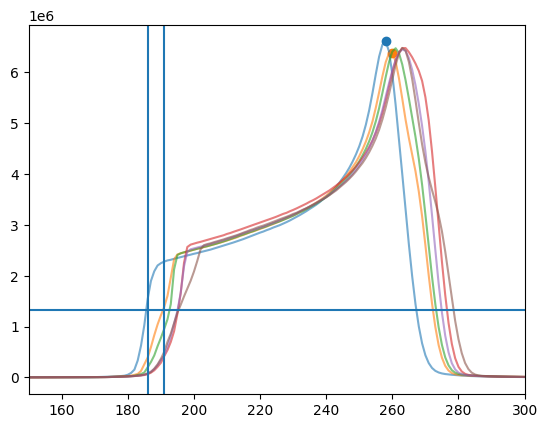

In [26]:
set_up_idx_plan =  np.unravel_index(np.argmax(np.diff(profile)), np.diff(profile).shape)[0]
set_up_idx_w2 =  np.unravel_index(np.argmax(np.diff(profile_w2)), np.diff(profile_w2).shape)[0]
set_up_idx_w3 =  np.unravel_index(np.argmax(np.diff(profile_w3)), np.diff(profile_w3).shape)[0]
set_up_idx_w4 =  np.unravel_index(np.argmax(np.diff(profile_w4)), np.diff(profile_w4).shape)[0]
set_up_idx_w5 =  np.unravel_index(np.argmax(np.diff(profile_w5)), np.diff(profile_w5).shape)[0]
set_up_idx_w6 =  np.unravel_index(np.argmax(np.diff(profile_w6)), np.diff(profile_w6).shape)[0]


max_idx_plan =  np.unravel_index(np.argmax(profile), profile.shape)[0]
max_idx_w2 =  np.unravel_index(np.argmax(profile_w2), profile_w2.shape)[0]

indeces_set_up = np.where(profile > 0.20*max(profile))
indeces_set_up_w2 = np.where(profile_w2 > 0.20*max(profile))
print(indeces_set_up[0][0])




plt.plot(profile, label = "Planning", alpha = 0.6)
plt.plot(profile_w2, label = "w2", alpha = 0.6)
plt.plot(profile_w3, label = "w3", alpha = 0.6)
plt.plot(profile_w4, label = "w4", alpha = 0.6)
plt.plot(profile_w5, label = "w5", alpha = 0.6)
plt.plot(profile_w6, label = "w6", alpha = 0.6)
plt.scatter(max_idx_plan, profile[max_idx_plan])
plt.scatter(max_idx_w2, profile_w2[max_idx_w2])
plt.axhline(0.20*max(profile))
plt.axvline(indeces_set_up[0][0])
plt.axvline(indeces_set_up_w2[0][0])

plt.xlim(150,300)
#plt.savefig(r"C:\Users\amibe\OneDrive\Documentos\NOVO\Study3_HNC\analyze_data\png" + "/" + planning_file + ".png", dpi=300, bbox_inches="tight")
        #plt.savefig(r"C:\Users\amibe\OneDrive\Documentos\NOVO\Study3_HNC\analyze_data\png\planning_file" + ".png", dpi=300, bbox_inches="tight")
plt.show()

### Datfile logic

In [62]:
overall_dat_path = r"\\klient.uib.no\felles\LAB-IT\IFT\Medisinskfysikk\Anna\adaptive-weekly\Adaptive_weekly_5\dose_simulations\planning\FLUKA_cagr_HN_weekly_5_01_IMPT_Anna\01_310"

source_files = []
files = os.listdir(overall_dat_path)

for file in files: 
    if "source_" in file: 
        with open(overall_dat_path + "/"+ file, "r") as f: 
            lines = f.readlines()
            corresponding_dat_file = lines[78][29:-3]
            spot_number = file[7:-2]

            results_path = "Results_spot_" + str(spot_number)

            os.mkdir(overall_dat_path + "/" + results_path + "/correct_dat_file")
            src_path = overall_dat_path + "/" + corresponding_dat_file 
            dst_path = overall_dat_path + "/" +  results_path + "/correct_dat_file/" + corresponding_dat_file
            shutil.copy(src_path, dst_path)
            print(file)
            print(results_path)
            print(corresponding_dat_file)
            print("---------------")


    



source_1.f
Results_spot_1
01_310_10.dat
---------------
source_10.f
Results_spot_10
01_310_186.dat
---------------
source_11.f
Results_spot_11
01_310_205.dat
---------------
source_12.f
Results_spot_12
01_310_24.dat
---------------
source_13.f
Results_spot_13
01_310_25.dat
---------------
source_14.f
Results_spot_14
01_310_26.dat
---------------
source_15.f
Results_spot_15
01_310_264.dat
---------------
source_16.f
Results_spot_16
01_310_266.dat
---------------
source_17.f
Results_spot_17
01_310_273.dat
---------------
source_18.f
Results_spot_18
01_310_274.dat
---------------
source_19.f
Results_spot_19
01_310_277.dat
---------------
source_2.f
Results_spot_2
01_310_123.dat
---------------
source_20.f
Results_spot_20
01_310_28.dat
---------------
source_21.f
Results_spot_21
01_310_293.dat
---------------
source_22.f
Results_spot_22
01_310_3.dat
---------------
source_23.f
Results_spot_23
01_310_32.dat
---------------
source_24.f
Results_spot_24
01_310_326.dat
---------------
source_25

### Include Dose

In [2]:
dose_path_planning = r"\\klient.uib.no\felles\LAB-IT\IFT\Medisinskfysikk\Anna\adaptive-weekly\Adaptive_weekly_5\dose_simulations\planning\FLUKA_cagr_HN_weekly_5_01_IMPT_Anna\01_310\Results_spot_29\BNNLIS\FLUKA_DICOM\dose\FLK_Phys-dose1.0_cagr_HN_weekly_5_01_IMPT_Anna_01_310_u.dcm"
dose_path_w2 = r"\\klient.uib.no\felles\LAB-IT\IFT\Medisinskfysikk\Anna\adaptive-weekly\Adaptive_weekly_5\dose_simulations\w2\FLUKA_cagr_HN_weekly_5_01_IMPT_Anna\01_310\Results_spot_29\BNNLIS\FLUKA_DICOM\dose\FLK_Phys-dose1.0_cagr_HN_weekly_5_01_IMPT_Anna_01_310_u.dcm"
dose_path_w3 = r"\\klient.uib.no\felles\LAB-IT\IFT\Medisinskfysikk\Anna\adaptive-weekly\Adaptive_weekly_5\dose_simulations\w3\FLUKA_cagr_HN_weekly_5_01_IMPT_Anna\01_310\Results_spot_29\BNNLIS\FLUKA_DICOM\dose\FLK_Phys-dose1.0_cagr_HN_weekly_5_01_IMPT_Anna_01_310_u.dcm"
dose_path_w4 = r"\\klient.uib.no\felles\LAB-IT\IFT\Medisinskfysikk\Anna\adaptive-weekly\Adaptive_weekly_5\dose_simulations\w4\FLUKA_cagr_HN_weekly_5_01_IMPT_Anna\01_310\Results_spot_29\BNNLIS\FLUKA_DICOM\dose\FLK_Phys-dose1.0_cagr_HN_weekly_5_01_IMPT_Anna_01_310_u.dcm"
dose_path_w5 = r"\\klient.uib.no\felles\LAB-IT\IFT\Medisinskfysikk\Anna\adaptive-weekly\Adaptive_weekly_5\dose_simulations\w5\FLUKA_cagr_HN_weekly_5_01_IMPT_Anna\01_310\Results_spot_29\BNNLIS\FLUKA_DICOM\dose\FLK_Phys-dose1.0_cagr_HN_weekly_5_01_IMPT_Anna_01_310_u.dcm"
dose_path_w6 = r"\\klient.uib.no\felles\LAB-IT\IFT\Medisinskfysikk\Anna\adaptive-weekly\Adaptive_weekly_5\dose_simulations\w6\FLUKA_cagr_HN_weekly_5_01_IMPT_Anna\01_310\Results_spot_29\BNNLIS\FLUKA_DICOM\dose\FLK_Phys-dose1.0_cagr_HN_weekly_5_01_IMPT_Anna_01_310_u.dcm"


plan_dose_img = pydicom.dcmread(dose_path_planning).pixel_array
plan_dose_img_w2 = pydicom.dcmread(dose_path_w2).pixel_array
plan_dose_img_w3 = pydicom.dcmread(dose_path_w3).pixel_array
plan_dose_img_w4 = pydicom.dcmread(dose_path_w4).pixel_array
plan_dose_img_w5 = pydicom.dcmread(dose_path_w5).pixel_array
plan_dose_img_w6 = pydicom.dcmread(dose_path_w6).pixel_array

In [4]:

mask_path_plan = r"d:\Adaptiv-weekly\CT_and_masks\planning\testing_resampling_to_dose.nii.gz"
binary_mask_plan = nib.load(mask_path_plan).get_fdata()
binary_mask_plan = np.transpose(binary_mask_plan, axes = (2, 1, 0))

mask_path_c2 = r"d:\Adaptiv-weekly\CT_and_masks\w2\binary_mask_resampled_to_match_pCT.nii.gz"
#r"d:\Adaptiv-weekly\CT_and_masks\w2\binary_mask_resampled_to_dose\testing_resampling_to_dose.nii.gz"
binary_mask_c2 = nib.load(mask_path_c2).get_fdata()
binary_mask_c2 = np.transpose(binary_mask_c2, axes = (2, 1, 0))

mask_path_c3 = r"d:\Adaptiv-weekly\CT_and_masks\w3\binary_mask_resampled_to_match_pCT.nii.gz"
binary_mask_c3 = nib.load(mask_path_c3).get_fdata()
binary_mask_c3 = np.transpose(binary_mask_c3, axes = (2, 1, 0))

mask_path_c4 = r"d:\Adaptiv-weekly\CT_and_masks\w4\binary_mask_resampled_to_match_pCT.nii.gz"
binary_mask_c4 = nib.load(mask_path_c4).get_fdata()
binary_mask_c4 = np.transpose(binary_mask_c4, axes = (2, 1, 0))

mask_path_c5 = r"d:\Adaptiv-weekly\CT_and_masks\w5\binary_mask_resampled_to_match_pCT.nii.gz"
binary_mask_c5 = nib.load(mask_path_c5).get_fdata()
binary_mask_c5 = np.transpose(binary_mask_c5, axes = (2, 1, 0))

mask_path_c6 = r"d:\Adaptiv-weekly\CT_and_masks\w6\binary_mask_resampled_to_match_pCT.nii.gz"
binary_mask_c6 = nib.load(mask_path_c6).get_fdata()
binary_mask_c6 = np.transpose(binary_mask_c6, axes = (2, 1, 0))


In [92]:
import numpy as np
import SimpleITK as sitk

# ---- Source mask ----

#mask = nib.load(r"d:\Adaptiv-weekly\CT_and_masks\planning\binary_mask_from_Slicer\1 RTSTRUCT RS Unapproved-BODY-label.nii.gz").get_fdata()
mask = nib.load(r"d:\Adaptiv-weekly\CT_and_masks\w6\binary_mask_resampled_to_match_pCT.nii.gz").get_fdata()

mask_np = np.array(mask) 
mask_sitk = sitk.GetImageFromArray(mask_np.transpose(2, 1, 0))



mask_sitk.SetOrigin((-297.5, -221, -206.3))
mask_sitk.SetSpacing((1.162, 1.162, 2.0))
mask_sitk.SetDirection(np.eye(3).flatten())  # if no direction info

# ---- Target geometry ----
target_size = (573, 315, 117)      # (x,y,z)
target_spacing = (1.0, 1.0, 3.0)
target_origin = (-275.7, -99.49, -212.3)

reference = sitk.Image(
    target_size,
    sitk.sitkUInt8
)


reference.SetOrigin(target_origin)
reference.SetSpacing(target_spacing)
reference.SetDirection(np.eye(3).flatten())


# ---- Resample ----
resampled = sitk.Resample(
    mask_sitk,
    reference,
    sitk.Transform(),
    sitk.sitkNearestNeighbor,   # important for binary masks
    0,
    sitk.sitkUInt8
)



# Back to numpy
mask_resampled = sitk.GetArrayFromImage(resampled)
###
mask_uint8 = sitk.Cast(mask_sitk, sitk.sitkUInt8)

dist = sitk.SignedMaurerDistanceMap(
    mask_uint8,
    insideIsPositive=True,
    squaredDistance=False,
    useImageSpacing=True
)

dist_resampled = sitk.Resample(
    dist,
    reference,
    sitk.Transform(),
    sitk.sitkLinear,
    -1000.0,
    sitk.sitkFloat32
)

mask_resampled = dist_resampled > 0


###


sitk.WriteImage(mask_resampled, r"d:\Adaptiv-weekly\CT_and_masks\w6\binary_mask_resampled_to_match_pCT.nii.gz")
#sitk.WriteImage(mask_resampled, r"d:\Adaptiv-weekly\CT_and_masks\w2\new2_testing_resampling_to_dose_ny.nii.gz")

# Convert back to (x,y,z) if desired
#mask_resampled = mask_resampled.transpose(2, 1, 0)

#print(mask_resampled.shape)

In [5]:
max_idx = np.unravel_index(np.argmax(plan_dose_img), plan_dose_img.shape)
max_slice = plan_dose_img[max_idx[0],:,:]

angle = np.degrees(np.arccos(0.771700))#(0.775968))#0.754750))
print(angle)


# NBNB! what should reshape and order be? 
rotated_dose = rotate(
        max_slice,
        angle=angle,              # degrees
        reshape=False,         # keep original image dimensions
        order=1)    

plan_dose_img_new = rotate(
             plan_dose_img*binary_mask_plan,
             angle=angle,
             axes=(1, 2),   # rotate in the y-x plane
             #reshape = True
             reshape=False, 
             order = 1
         )

plan_dose_img_new_w2 = rotate(
             plan_dose_img_w2*binary_mask_c2,
             angle=angle,
             axes=(1, 2),   # rotate in the y-x plane
             #reshape = True
             reshape=False, 
             order = 1
         )

plan_dose_img_new_w3 = rotate(
             plan_dose_img_w3*binary_mask_c3,
             angle=angle,
             axes=(1, 2),   # rotate in the y-x plane
             #reshape = True
             reshape=False, 
             order = 1
         )

plan_dose_img_new_w4 = rotate(
             plan_dose_img_w4*binary_mask_c4,
             angle=angle,
             axes=(1, 2),   # rotate in the y-x plane
             #reshape = True
             reshape=False, 
             order = 1
         )

plan_dose_img_new_w5 = rotate(
             plan_dose_img_w5*binary_mask_c5,
             angle=angle,
             axes=(1, 2),   # rotate in the y-x plane
             #reshape = True
             reshape=False, 
             order = 1
         )

plan_dose_img_new_w6 = rotate(
             plan_dose_img_w6*binary_mask_c6,
             angle=angle,
             axes=(1, 2),   # rotate in the y-x plane
             #reshape = True
             reshape=False, 
             order = 1
         )

39.493206237446465


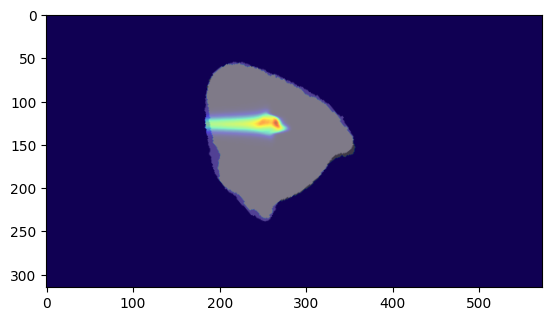

In [6]:
binary_mask_rotated_c6 = rotate(
             binary_mask_c6,
             angle=angle,
             axes=(1, 2),   # rotate in the y-x plane
             #reshape = True
             reshape=False, 
             order = 1
         )

binary_mask_rotated_plan = rotate(
             binary_mask_plan,
             angle=angle,
             axes=(1, 2),   # rotate in the y-x plane
             #reshape = True
             reshape=False, 
             order = 1
         )

max_slice_w6 = np.unravel_index(np.argmax(np.diff(plan_dose_img_new_w6)), np.diff(plan_dose_img_new_w6).shape)[0]
profile_max_slice_w6 = plan_dose_img_new_w6[max_slice_w6].sum(axis = 0)

plt.figure()
plt.imshow(binary_mask_rotated_plan[max_slice_w6], cmap = "gray")
plt.imshow(binary_mask_rotated_c6[max_slice_w6], alpha = 0.5)
plt.imshow(plan_dose_img_new[max_slice_w6], alpha = 0.5, cmap = "jet")
plt.show()

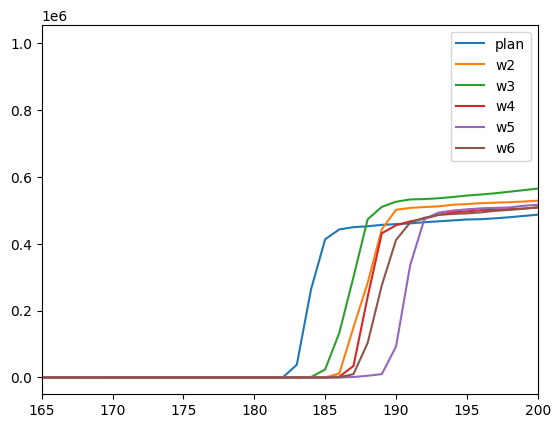

In [13]:
max_slice_plan = np.unravel_index(np.argmax(np.diff(plan_dose_img_new)), np.diff(plan_dose_img_new).shape)[0]
profile_max_slice = plan_dose_img_new[max_slice_plan].sum(axis = 0)

max_slice_w2 = np.unravel_index(np.argmax(np.diff(plan_dose_img_new_w2)), np.diff(plan_dose_img_new_w2).shape)[0]
profile_max_slice_w2 = plan_dose_img_new_w2[max_slice_w2].sum(axis = 0)

max_slice_w3 = np.unravel_index(np.argmax(np.diff(plan_dose_img_new_w3)), np.diff(plan_dose_img_new_w3).shape)[0]
profile_max_slice_w3 = plan_dose_img_new_w3[max_slice_w3].sum(axis = 0)

max_slice_w4 = np.unravel_index(np.argmax(np.diff(plan_dose_img_new_w4)), np.diff(plan_dose_img_new_w4).shape)[0]
profile_max_slice_w4 = plan_dose_img_new_w4[max_slice_w4].sum(axis = 0)

max_slice_w5 = np.unravel_index(np.argmax(np.diff(plan_dose_img_new_w5)), np.diff(plan_dose_img_new_w5).shape)[0]
profile_max_slice_w5 = plan_dose_img_new_w5[max_slice_w5].sum(axis = 0)

max_slice_w6 = np.unravel_index(np.argmax(np.diff(plan_dose_img_new_w6)), np.diff(plan_dose_img_new_w6).shape)[0]
profile_max_slice_w6 = plan_dose_img_new_w6[max_slice_w6].sum(axis = 0)

plt.figure()
plt.plot(profile_max_slice, label = "plan")
plt.plot(profile_max_slice_w2 ,label = "w2")
plt.plot(profile_max_slice_w3 ,label = "w3")
plt.plot(profile_max_slice_w4 ,label = "w4")
plt.plot(profile_max_slice_w5 ,label = "w5")
plt.plot(profile_max_slice_w6, label = "w6")
#plt.axvline(x = 196)
#plt.axvline(x = 207)
plt.xlim(165, 200)
plt.legend()
plt.show()

Range shifts (total) (d80)
W2 - planning:  1 mm
W3 - planning:  9 mm
W4 - planning:  10 mm
W5 - planning:  9 mm
W6 - planning:  5 mm
Difference in d20
W2 - planning:  -1 mm
W3 - planning:  9 mm
W4 - planning:  7 mm
W5 - planning:  6 mm
W6 - planning:  1 mm
set up error
W2 - planning 3 mm
W3 - planning 3 mm
W4 - planning 4 mm
W5 - planning 7 mm
W6 - planning 6 mm


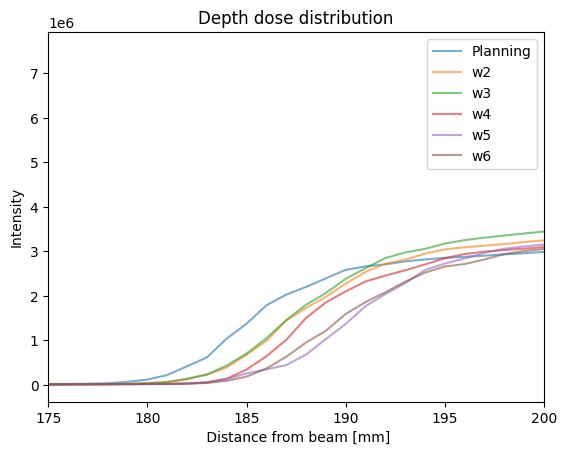

In [14]:
profile = plan_dose_img_new.sum(axis=(0,1))
profile_w2 = plan_dose_img_new_w2.sum(axis=(0,1))
profile_w3 = plan_dose_img_new_w3.sum(axis=(0,1))
profile_w4 = plan_dose_img_new_w4.sum(axis=(0,1))
profile_w5 = plan_dose_img_new_w5.sum(axis=(0,1))
profile_w6 = plan_dose_img_new_w6.sum(axis=(0,1))

d80_plan = 0.8*np.max(profile)
d80_plan_indeces = np.where(profile > d80_plan)[0]
d80_w2 = 0.8*np.max(profile_w2)
d80_w2_indeces = np.where(profile_w2 > d80_w2)[0]
d80_w3 = 0.8*np.max(profile_w3)
d80_w3_indeces = np.where(profile_w3 > d80_w3)[0]
d80_w4 = 0.8*np.max(profile_w4)
d80_w4_indeces = np.where(profile_w4 > d80_w4)[0]
d80_w5 = 0.8*np.max(profile_w5)
d80_w5_indeces = np.where(profile_w5 > d80_w5)[0]
d80_w6 = 0.8*np.max(profile_w6)
d80_w6_indeces = np.where(profile_w6 > d80_w6)[0]

d20_plan = 0.2*np.max(profile)
d20_plan_indeces = np.where(profile > d20_plan)[0]
d20_w2 = 0.2*np.max(profile_w2)
d20_w2_indeces = np.where(profile_w2 > d20_w2)[0]
d20_w3 = 0.2*np.max(profile_w3)
d20_w3_indeces = np.where(profile_w3 > d20_w3)[0]
d20_w4 = 0.2*np.max(profile_w4)
d20_w4_indeces = np.where(profile_w4 > d20_w4)[0]
d20_w5 = 0.2*np.max(profile_w5)
d20_w5_indeces = np.where(profile_w5 > d20_w5)[0]
d20_w6 = 0.2*np.max(profile_w6)
d20_w6_indeces = np.where(profile_w6 > d20_w6)[0]


print("Range shifts (total) (d80)")
RS_w2_plan = d80_w2_indeces[-1] - d80_plan_indeces[-1]
RS_w3_plan = d80_w3_indeces[-1] - d80_plan_indeces[-1]
RS_w4_plan = d80_w4_indeces[-1] - d80_plan_indeces[-1]
RS_w5_plan = d80_w5_indeces[-1] - d80_plan_indeces[-1]
RS_w6_plan = d80_w6_indeces[-1] - d80_plan_indeces[-1]

print("W2 - planning: ", RS_w2_plan, "mm")
print("W3 - planning: ", RS_w3_plan, "mm")
print("W4 - planning: ", RS_w4_plan, "mm")
print("W5 - planning: ", RS_w5_plan, "mm")
print("W6 - planning: ", RS_w6_plan, "mm")

print("Difference in d20")
RS_w2_plan_d20 = d20_w2_indeces[-1] - d20_plan_indeces[-1]
RS_w3_plan_d20 = d20_w3_indeces[-1] - d20_plan_indeces[-1]
RS_w4_plan_d20 = d20_w4_indeces[-1] - d20_plan_indeces[-1]
RS_w5_plan_d20 = d20_w5_indeces[-1] - d20_plan_indeces[-1]
RS_w6_plan_d20 = d20_w6_indeces[-1] - d20_plan_indeces[-1]

print("W2 - planning: ", RS_w2_plan_d20, "mm")
print("W3 - planning: ", RS_w3_plan_d20, "mm")
print("W4 - planning: ", RS_w4_plan_d20, "mm")
print("W5 - planning: ", RS_w5_plan_d20, "mm")
print("W6 - planning: ", RS_w6_plan_d20, "mm")

print("set up error")
set_up_idx_plan =  np.unravel_index(np.argmax(np.diff(profile)), np.diff(profile).shape)[0]
set_up_idx_w2 =  np.unravel_index(np.argmax(np.diff(profile_w2)), np.diff(profile_w2).shape)[0]
set_up_idx_w3 =  np.unravel_index(np.argmax(np.diff(profile_w3)), np.diff(profile_w3).shape)[0]
set_up_idx_w4 =  np.unravel_index(np.argmax(np.diff(profile_w4)), np.diff(profile_w4).shape)[0]
set_up_idx_w5 =  np.unravel_index(np.argmax(np.diff(profile_w5)), np.diff(profile_w5).shape)[0]
set_up_idx_w6 =  np.unravel_index(np.argmax(np.diff(profile_w6)), np.diff(profile_w6).shape)[0]
print("W2 - planning",  set_up_idx_w2-set_up_idx_plan, "mm")
print("W3 - planning",  set_up_idx_w3-set_up_idx_plan, "mm")
print("W4 - planning",  set_up_idx_w4-set_up_idx_plan, "mm")
print("W5 - planning",  set_up_idx_w5-set_up_idx_plan, "mm")
print("W6 - planning",  set_up_idx_w6-set_up_idx_plan, "mm")

from scipy.signal import find_peaks

peaks, _ = find_peaks(np.diff(profile), prominence=5000)
first_max_grad = peaks[0]

peaks_w2, _ = find_peaks(np.diff(profile_w2), prominence=5000)
first_max_grad_w2 = peaks_w2[0]

plt.plot(profile, label = "Planning", alpha = 0.6)
plt.plot(profile_w2, label = "w2", alpha = 0.6)
plt.plot(profile_w3, label = "w3", alpha = 0.6)
plt.plot(profile_w4, label = "w4", alpha = 0.6)
plt.plot(profile_w5, label = "w5", alpha = 0.6)
plt.plot(profile_w6, label = "w6", alpha = 0.6)

plt.scatter(x = d80_plan_indeces[-1], y = profile[d80_plan_indeces[-1]], marker = "x")
plt.scatter(x = d80_w2_indeces[-1], y = profile_w2[d80_w2_indeces[-1]], marker = "x")
plt.scatter(x = d80_w3_indeces[-1], y = profile_w3[d80_w3_indeces[-1]], marker = "x")
plt.scatter(x = d80_w4_indeces[-1], y = profile_w4[d80_w4_indeces[-1]], marker = "x")
plt.scatter(x = d80_w5_indeces[-1], y = profile_w5[d80_w5_indeces[-1]], marker = "x")
plt.scatter(x = d80_w6_indeces[-1], y = profile_w6[d80_w6_indeces[-1]], marker = "x")



plt.scatter(x = d20_plan_indeces[-1], y = profile[d20_plan_indeces[-1]], marker = "o", color = "#1f77b4")
plt.scatter(x = d20_w2_indeces[-1], y = profile_w2[d20_w2_indeces[-1]], marker = "o", color = "#ff7f0e")
plt.scatter(x = d20_w3_indeces[-1], y = profile_w3[d20_w3_indeces[-1]], marker = "o", color = "#2ca02c")
plt.scatter(x = d20_w4_indeces[-1], y = profile_w4[d20_w4_indeces[-1]], marker = "o", color = "#d62728")
plt.scatter(x = d20_w5_indeces[-1], y = profile_w5[d20_w5_indeces[-1]], marker = "o", color = "#9467bd")
plt.scatter(x = d20_w6_indeces[-1], y = profile_w6[d20_w6_indeces[-1]], marker = "o", color = "#8c564b")

#plt.scatter(x = first_max_grad, y = profile[first_max_grad])

#plt.scatter(x = np.unravel_index(np.argmax(np.diff(profile)), np.diff(profile).shape)[0], y = profile[np.unravel_index(np.argmax(np.diff(profile)), np.diff(profile).shape)[0]], color = "#1f77b4" , marker ="s" )
#plt.scatter(x = np.unravel_index(np.argmax(np.diff(profile_w2)), np.diff(profile_w2).shape)[0], y = profile_w2[np.unravel_index(np.argmax(np.diff(profile_w2)), np.diff(profile_w2).shape)[0]], color =  "#ff7f0e", marker ="s" )
#plt.scatter(x = np.unravel_index(np.argmax(np.diff(profile_w3)), np.diff(profile_w3).shape)[0], y = profile_w3[np.unravel_index(np.argmax(np.diff(profile_w3)), np.diff(profile_w3).shape)[0]], color = "#2ca02c", marker ="s" )
#plt.scatter(x = np.unravel_index(np.argmax(np.diff(profile_w4)), np.diff(profile_w4).shape)[0], y = profile_w4[np.unravel_index(np.argmax(np.diff(profile_w4)), np.diff(profile_w4).shape)[0]], color = "#d62728", marker ="s" )
#plt.scatter(x = np.unravel_index(np.argmax(np.diff(profile_w5)), np.diff(profile_w5).shape)[0], y = profile_w5[np.unravel_index(np.argmax(np.diff(profile_w5)), np.diff(profile_w5).shape)[0]], color = "#9467bd", marker ="s" )
#plt.scatter(x = np.unravel_index(np.argmax(np.diff(profile_w6)), np.diff(profile_w6).shape)[0], y = profile_w6[np.unravel_index(np.argmax(np.diff(profile_w6)), np.diff(profile_w6).shape)[0]], color =  "#8c564b", marker ="s" )

#plt.axvline(x = 185)
#plt.axvline(x = 199)
#plt.axhline(y = 0.2*max(profile))
#plt.axhline(y = 0.2*max(profile_w6))
#plt.scatter(x = first_max_grad_w2, y = profile_w2[first_max_grad_w2])

#plt.axvline(x = d80_plan_indeces[-1], linestyle = "--", color = "blue", label = d80_plan_indeces[-1])
#plt.axvline(x = d80_w2_indeces[-1], linestyle = "--", color = "orange", label = d80_w2_indeces[-1])
#plt.axvline(x = d80_w3_indeces[-1], linestyle = "--", color = "green", label = d80_w3_indeces[-1])
#plt.axvline(x = d80_w4_indeces[-1], linestyle = "--", color = "brown", label = d80_w4_indeces[-1])
plt.xlim(175, 200)
plt.xlabel(" Distance from beam [mm]")
plt.title("Depth dose distribution")
plt.ylabel("Intensity")
plt.legend()
plt.show()

#### Diverse

185
(np.int64(195),)


(100.0, 300.0)

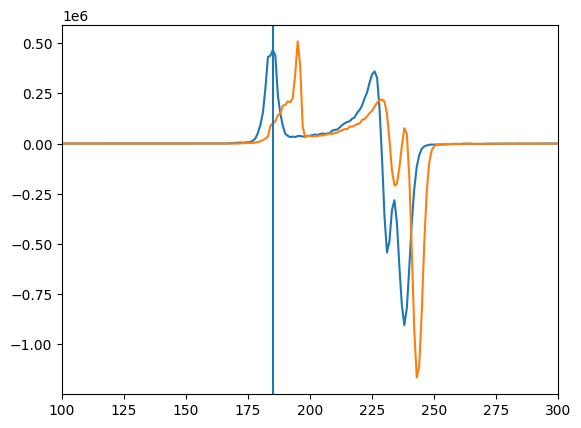

In [81]:
from scipy.ndimage import gaussian_filter1d
dy = np.diff(profile)
dy_w2 = np.diff(profile_w2)

print(np.unravel_index(np.argmax(dy), dy.shape)[0])
print(np.unravel_index(np.argmax(dy_w2), dy_w2.shape))

plt.plot(dy)
plt.plot(dy_w2)
plt.axvline(x = 185)
plt.xlim(100, 300)

### Spot 50

In [2]:
planning_overall_path = r"C:\Users\amibe\OneDrive\Documentos\NOVO\Study3_HNC\Data_test_tog\nifti\planning\Results_spot_24"
pg_path = planning_overall_path + "/" + "pg.nii.gz"
fn_path = planning_overall_path + "/" + "fn.nii.gz"

w2_overall_path = r"C:\Users\amibe\OneDrive\Documentos\NOVO\Study3_HNC\Data_test_tog\nifti\w2\Results_spot_24"
pg_path_w2 = w2_overall_path + "/" + "pg.nii.gz"
fn_path_w2 = w2_overall_path + "/" + "fn.nii.gz"

w3_overall_path = r"C:\Users\amibe\OneDrive\Documentos\NOVO\Study3_HNC\Data_test_tog\nifti\w3\Results_spot_24"
pg_path_w3 = w3_overall_path + "/" + "pg.nii.gz"
fn_path_w3 = w3_overall_path + "/" + "fn.nii.gz"

w4_overall_path = r"C:\Users\amibe\OneDrive\Documentos\NOVO\Study3_HNC\Data_test_tog\nifti\w4\Results_spot_24"
pg_path_w4 = w4_overall_path + "/" + "pg.nii.gz"
fn_path_w4 = w4_overall_path + "/" + "fn.nii.gz"

w5_overall_path = r"C:\Users\amibe\OneDrive\Documentos\NOVO\Study3_HNC\Data_test_tog\nifti\w5\Results_spot_24"
pg_path_w5 = w5_overall_path + "/" + "pg.nii.gz"
fn_path_w5 = w5_overall_path + "/" + "fn.nii.gz"

w6_overall_path = r"C:\Users\amibe\OneDrive\Documentos\NOVO\Study3_HNC\Data_test_tog\nifti\w6\Results_spot_24"
pg_path_w6 = w6_overall_path + "/" + "pg.nii.gz"
fn_path_w6 = w6_overall_path + "/" + "fn.nii.gz"

In [3]:
pg_volume = nib.load(pg_path).get_fdata()
fn_volume = nib.load(fn_path).get_fdata()

pg_volume_w2 = nib.load(pg_path_w2).get_fdata()
fn_volume_w2 = nib.load(fn_path_w2).get_fdata()

pg_volume_w3 = nib.load(pg_path_w3).get_fdata()
fn_volume_w3 = nib.load(fn_path_w3).get_fdata()

pg_volume_w4 = nib.load(pg_path_w4).get_fdata()
fn_volume_w4 = nib.load(fn_path_w4).get_fdata()

pg_volume_w5 = nib.load(pg_path_w5).get_fdata()
fn_volume_w5 = nib.load(fn_path_w5).get_fdata()

pg_volume_w6 = nib.load(pg_path_w6).get_fdata()
fn_volume_w6 = nib.load(fn_path_w6).get_fdata()


print(pg_volume.shape)
print(fn_volume.shape)


FileNotFoundError: No such file or no access: 'C:/Users/amibe/OneDrive/Documentos/NOVO/Study3_HNC/Data_test_tog/nifti/planning/Results_spot_24/pg.nii.gz'

(np.int64(252), np.int64(68), np.int64(79))


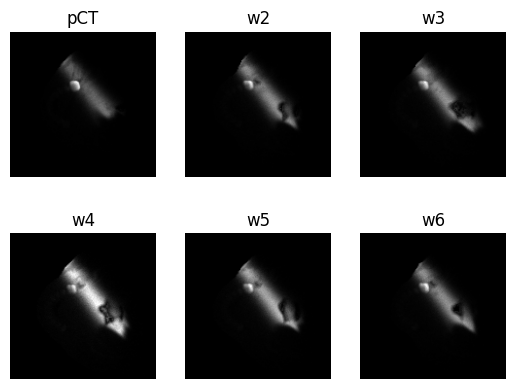

In [38]:
print(np.unravel_index(np.argmax(pg_volume), pg_volume.shape))

fig, axes = plt.subplots(2, 3)
axes[0, 0].imshow(pg_volume[200:350,:150,79], cmap = "gray")
axes[0, 0].set_title("pCT")
axes[0, 1].imshow(pg_volume_w2[200:350,:150,79], cmap = "gray")
axes[0, 1].set_title("w2")
axes[0, 2].imshow(pg_volume_w3[200:350,:150,79], cmap = "gray")
axes[0, 2].set_title("w3")

axes[1, 0].imshow(pg_volume_w4[200:350,:150,79], cmap = "gray")
axes[1, 0].set_title("w4")
axes[1, 1].imshow(pg_volume_w5[200:350,:150,79], cmap = "gray")
axes[1, 1].set_title("w5")
axes[1, 2].imshow(pg_volume_w6[200:350,:150,79], cmap = "gray")
axes[1, 2].set_title("w6")




axes[0,0].axis("off")
axes[0,1].axis("off")
axes[0,2].axis("off")
axes[1,0].axis("off")
axes[1,1].axis("off")
axes[1,2].axis("off")
plt.show()

(np.int64(252), np.int64(68), np.int64(79))


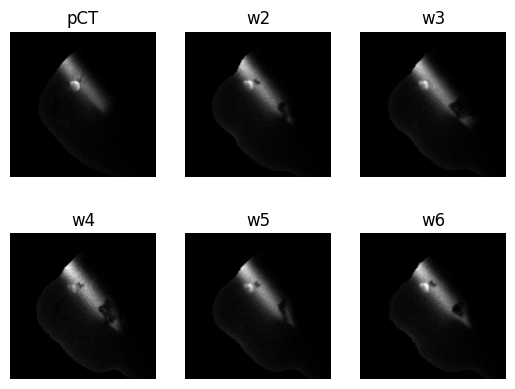

In [39]:
print(np.unravel_index(np.argmax(fn_volume), fn_volume.shape))

fig, axes = plt.subplots(2, 3)
axes[0, 0].imshow(fn_volume[200:350,:150,79], cmap = "gray")
axes[0, 0].set_title("pCT")
axes[0, 1].imshow(fn_volume_w2[200:350,:150,79], cmap = "gray")
axes[0, 1].set_title("w2")
axes[0, 2].imshow(fn_volume_w3[200:350,:150,79], cmap = "gray")
axes[0, 2].set_title("w3")

axes[1, 0].imshow(fn_volume_w4[200:350,:150,79], cmap = "gray")
axes[1, 0].set_title("w4")
axes[1, 1].imshow(fn_volume_w5[200:350,:150,79], cmap = "gray")
axes[1, 1].set_title("w5")
axes[1, 2].imshow(fn_volume_w6[200:350,:150,79], cmap = "gray")
axes[1, 2].set_title("w6")




axes[0,0].axis("off")
axes[0,1].axis("off")
axes[0,2].axis("off")
axes[1,0].axis("off")
axes[1,1].axis("off")
axes[1,2].axis("off")
plt.show()

### Spot 1

In [4]:
planning_overall_path = r"C:\Users\amibe\OneDrive\Documentos\NOVO\Study3_HNC\Data_test_tog\nifti\planning\Results_spot_24"
pg_path = planning_overall_path + "/" + "pg.nii.gz"
fn_path = planning_overall_path + "/" + "fn.nii.gz"

w2_overall_path = r"C:\Users\amibe\OneDrive\Documentos\NOVO\Study3_HNC\Data_test_tog\nifti\w2\Results_spot_24"
pg_path_w2 = w2_overall_path + "/" + "pg.nii.gz"
fn_path_w2 = w2_overall_path + "/" + "fn.nii.gz"

w3_overall_path = r"C:\Users\amibe\OneDrive\Documentos\NOVO\Study3_HNC\Data_test_tog\nifti\w3\Results_spot_24"
pg_path_w3 = w3_overall_path + "/" + "pg.nii.gz"
fn_path_w3 = w3_overall_path + "/" + "fn.nii.gz"

w4_overall_path = r"C:\Users\amibe\OneDrive\Documentos\NOVO\Study3_HNC\Data_test_tog\nifti\w4\Results_spot_24"
pg_path_w4 = w4_overall_path + "/" + "pg.nii.gz"
fn_path_w4 = w4_overall_path + "/" + "fn.nii.gz"

w5_overall_path = r"C:\Users\amibe\OneDrive\Documentos\NOVO\Study3_HNC\Data_test_tog\nifti\w5\Results_spot_24"
pg_path_w5 = w5_overall_path + "/" + "pg.nii.gz"
fn_path_w5 = w5_overall_path + "/" + "fn.nii.gz"

w6_overall_path = r"C:\Users\amibe\OneDrive\Documentos\NOVO\Study3_HNC\Data_test_tog\nifti\w6\Results_spot_24"
pg_path_w6 = w6_overall_path + "/" + "pg.nii.gz"
fn_path_w6 = w6_overall_path + "/" + "fn.nii.gz"

In [5]:
pg_volume = nib.load(pg_path).get_fdata()
fn_volume = nib.load(fn_path).get_fdata()

pg_volume_w2 = nib.load(pg_path_w2).get_fdata()
fn_volume_w2 = nib.load(fn_path_w2).get_fdata()

pg_volume_w3 = nib.load(pg_path_w3).get_fdata()
fn_volume_w3 = nib.load(fn_path_w3).get_fdata()

pg_volume_w4 = nib.load(pg_path_w4).get_fdata()
fn_volume_w4 = nib.load(fn_path_w4).get_fdata()

pg_volume_w5 = nib.load(pg_path_w5).get_fdata()
fn_volume_w5 = nib.load(fn_path_w5).get_fdata()

pg_volume_w6 = nib.load(pg_path_w6).get_fdata()
fn_volume_w6 = nib.load(fn_path_w6).get_fdata()


print(pg_volume.shape)
print(fn_volume.shape)


FileNotFoundError: No such file or no access: 'C:/Users/amibe/OneDrive/Documentos/NOVO/Study3_HNC/Data_test_tog/nifti/planning/Results_spot_24/pg.nii.gz'

(np.int64(233), np.int64(113), np.int64(74))


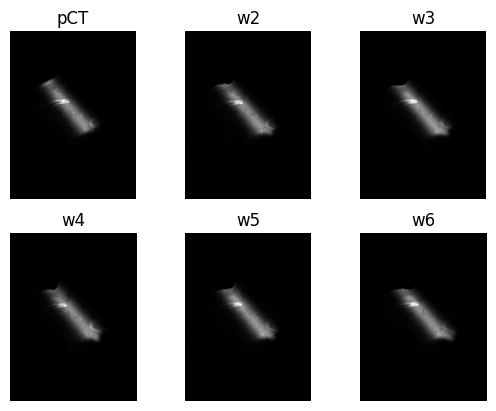

In [ ]:
print(np.unravel_index(np.argmax(pg_volume), pg_volume.shape))

fig, axes = plt.subplots(2, 3)
axes[0, 0].imshow(pg_volume[150:350,50:200,74], cmap = "gray")
axes[0, 0].set_title("pCT")
axes[0, 1].imshow(pg_volume_w2[150:350,50:200,74], cmap = "gray")
axes[0, 1].set_title("w2")
axes[0, 2].imshow(pg_volume_w3[150:350,50:200,74], cmap = "gray")
axes[0, 2].set_title("w3")

axes[1, 0].imshow(pg_volume_w4[150:350,50:200,74], cmap = "gray")
axes[1, 0].set_title("w4")
axes[1, 1].imshow(pg_volume_w5[150:350,50:200,74], cmap = "gray")
axes[1, 1].set_title("w5")
axes[1, 2].imshow(pg_volume_w6[150:350,50:200,74], cmap = "gray")
axes[1, 2].set_title("w6")

axes[0,0].axis("off")
axes[0,1].axis("off")
axes[0,2].axis("off")
axes[1,0].axis("off")
axes[1,1].axis("off")
axes[1,2].axis("off")
plt.show()

(np.int64(233), np.int64(113), np.int64(74))


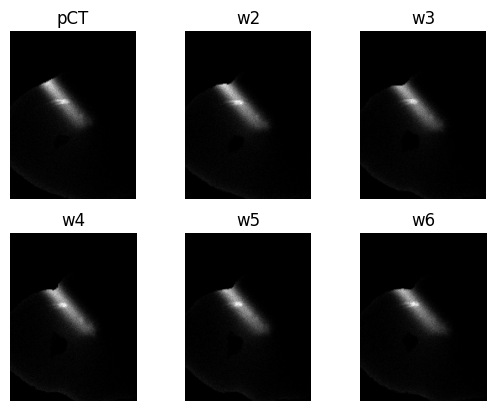

In [90]:
print(np.unravel_index(np.argmax(pg_volume), pg_volume.shape))

fig, axes = plt.subplots(2, 3)
axes[0, 0].imshow(fn_volume[150:350,50:200,74], cmap = "gray")
axes[0, 0].set_title("pCT")
axes[0, 1].imshow(fn_volume_w2[150:350,50:200,74], cmap = "gray")
axes[0, 1].set_title("w2")
axes[0, 2].imshow(fn_volume_w3[150:350,50:200,74], cmap = "gray")
axes[0, 2].set_title("w3")

axes[1, 0].imshow(fn_volume_w4[150:350,50:200,74], cmap = "gray")
axes[1, 0].set_title("w4")
axes[1, 1].imshow(fn_volume_w5[150:350,50:200,74], cmap = "gray")
axes[1, 1].set_title("w5")
axes[1, 2].imshow(fn_volume_w6[150:350,50:200,74], cmap = "gray")
axes[1, 2].set_title("w6")

axes[0,0].axis("off")
axes[0,1].axis("off")
axes[0,2].axis("off")
axes[1,0].axis("off")
axes[1,1].axis("off")
axes[1,2].axis("off")
plt.show()

### Spot 50 - rotate and analyse 1D distribution

In [4]:
planning_overall_path = r"\\klient.uib.no\felles\LAB-IT\IFT\Medisinskfysikk\Anna\adaptive-weekly\Adaptive_weekly_5\Results_export_to_cluster2\nifti_images_70_71\planning_new\Results_spot_29"
pg_path = planning_overall_path + "/" + "pg.nii.gz"
fn_path = planning_overall_path + "/" + "fn.nii.gz"

w2_overall_path = r"\\klient.uib.no\felles\LAB-IT\IFT\Medisinskfysikk\Anna\adaptive-weekly\Adaptive_weekly_5\Results_export_to_cluster2\nifti_images_70_71\w2\Results_spot_29"
pg_path_w2 = w2_overall_path + "/" + "pg.nii.gz"
fn_path_w2 = w2_overall_path + "/" + "fn.nii.gz"

w3_overall_path = r"\\klient.uib.no\felles\LAB-IT\IFT\Medisinskfysikk\Anna\adaptive-weekly\Adaptive_weekly_5\Results_export_to_cluster2\nifti_images_70_71\w3\Results_spot_29"
pg_path_w3 = w3_overall_path + "/" + "pg.nii.gz"
fn_path_w3 = w3_overall_path + "/" + "fn.nii.gz"

w4_overall_path = r"\\klient.uib.no\felles\LAB-IT\IFT\Medisinskfysikk\Anna\adaptive-weekly\Adaptive_weekly_5\Results_export_to_cluster2\nifti_images_70_71\w4\Results_spot_29"
pg_path_w4 = w4_overall_path + "/" + "pg.nii.gz"
fn_path_w4 = w4_overall_path + "/" + "fn.nii.gz"

w5_overall_path = r"\\klient.uib.no\felles\LAB-IT\IFT\Medisinskfysikk\Anna\adaptive-weekly\Adaptive_weekly_5\Results_export_to_cluster2\nifti_images_70_71\w5\Results_spot_29"
pg_path_w5 = w5_overall_path + "/" + "pg.nii.gz"
fn_path_w5 = w5_overall_path + "/" + "fn.nii.gz"

w6_overall_path = r"\\klient.uib.no\felles\LAB-IT\IFT\Medisinskfysikk\Anna\adaptive-weekly\Adaptive_weekly_5\Results_export_to_cluster2\nifti_images_70_71\w6\Results_spot_29"
pg_path_w6 = w6_overall_path + "/" + "pg.nii.gz"
fn_path_w6 = w6_overall_path + "/" + "fn.nii.gz"

pg_volume = nib.load(pg_path).get_fdata()
fn_volume = nib.load(fn_path).get_fdata()

pg_volume_w2 = nib.load(pg_path_w2).get_fdata()
fn_volume_w2 = nib.load(fn_path_w2).get_fdata()

pg_volume_w3 = nib.load(pg_path_w3).get_fdata()
fn_volume_w3 = nib.load(fn_path_w3).get_fdata()

pg_volume_w4 = nib.load(pg_path_w4).get_fdata()
fn_volume_w4 = nib.load(fn_path_w4).get_fdata()

pg_volume_w5 = nib.load(pg_path_w5).get_fdata()
fn_volume_w5 = nib.load(fn_path_w5).get_fdata()

pg_volume_w6 = nib.load(pg_path_w6).get_fdata()
fn_volume_w6 = nib.load(fn_path_w6).get_fdata()

In [26]:

binary_mask_c6_reshaped = np.transpose(binary_mask_c6, axes = (2, 1, 0))
binary_mask_plan_reshaped= np.transpose(binary_mask_plan, axes = (2, 1, 0))
print(binary_mask_plan_reshaped.shape)

(573, 315, 117)


In [5]:
def find_1d_dist(array, angle):
    array_1d = np.zeros(array.shape[1])

    for j in range(array.shape[2]):
        slice = array[:,:,j]
        
        rotated = rotate(
        slice,
        angle=angle,              # degrees
        reshape=False,         # keep original image dimensions
        order=1                # bilinear interpolation
        )

        array_1d += np.sum(rotated, axis=0)

    return array_1d

angle_ = np.degrees(np.arccos(0.635811))
print(angle_)

dist_1d_pg = find_1d_dist(pg_volume, angle = angle_ )
dist_1d_pg_w2 = find_1d_dist(pg_volume_w2, angle = angle_ )
dist_1d_pg_w3 = find_1d_dist(pg_volume_w3, angle = angle_ )
dist_1d_pg_w4 = find_1d_dist(pg_volume_w4, angle = angle_ )
dist_1d_pg_w5 = find_1d_dist(pg_volume_w5, angle = angle_ )
dist_1d_pg_w6 = find_1d_dist(pg_volume_w6, angle = angle_ )


dist_1d_fn = find_1d_dist(fn_volume, angle = angle_ )
dist_1d_fn_w2 = find_1d_dist(fn_volume_w2, angle = angle_ )
dist_1d_fn_w3 = find_1d_dist(fn_volume_w3, angle = angle_ )
dist_1d_fn_w4 = find_1d_dist(fn_volume_w4, angle = angle_ )
dist_1d_fn_w5 = find_1d_dist(fn_volume_w5, angle = angle_ )
dist_1d_fn_w6 = find_1d_dist(fn_volume_w6, angle = angle_ )


50.51983919380047


69


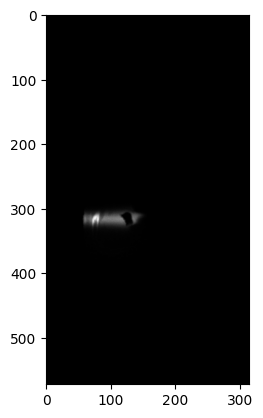

In [6]:
print(np.unravel_index(np.argmax(pg_volume), pg_volume.shape)[2])

max_slice_idx = np.unravel_index(np.argmax(pg_volume), pg_volume.shape)[2]
slice = pg_volume[:,:,max_slice_idx]
        
rotated = rotate(
    slice,
    angle=angle_ ,              # degrees
    reshape=False,         # keep original image dimensions
    order=1                # bilinear interpolation
    )

plt.figure()
plt.imshow(rotated, cmap = "gray")
plt.show()

In [7]:
print(np.unravel_index(np.argmax(pg_volume), pg_volume.shape)[2])

max_slice_idx = np.unravel_index(np.argmax(pg_volume), pg_volume.shape)[2]

depth = 1


dist_1d_pg = find_1d_dist(pg_volume[:,:,max_slice_idx-depth:max_slice_idx+depth], angle = angle_)
dist_1d_pg_w2 = find_1d_dist(pg_volume_w2[:,:,max_slice_idx-depth:max_slice_idx+depth], angle = angle_)
dist_1d_pg_w3 = find_1d_dist(pg_volume_w3[:,:,max_slice_idx-depth:max_slice_idx+depth], angle = angle_)
dist_1d_pg_w4 = find_1d_dist(pg_volume_w4[:,:,max_slice_idx-depth:max_slice_idx+depth], angle = angle_)
dist_1d_pg_w5 = find_1d_dist(pg_volume_w5[:,:,max_slice_idx-depth:max_slice_idx+depth], angle = angle_)
dist_1d_pg_w6 = find_1d_dist(pg_volume_w6[:,:,max_slice_idx-depth:max_slice_idx+depth], angle = angle_)


dist_1d_fn = find_1d_dist(fn_volume[:,:,max_slice_idx-depth:max_slice_idx+depth], angle = angle_)
dist_1d_fn_w2 = find_1d_dist(fn_volume_w2[:,:,max_slice_idx-depth:max_slice_idx+depth], angle = angle_)
dist_1d_fn_w3 = find_1d_dist(fn_volume_w3[:,:,max_slice_idx-depth:max_slice_idx+depth], angle = angle_)
dist_1d_fn_w4 = find_1d_dist(fn_volume_w4[:,:,max_slice_idx-depth:max_slice_idx+depth], angle = angle_)
dist_1d_fn_w5 = find_1d_dist(fn_volume_w5[:,:,max_slice_idx-depth:max_slice_idx+depth], angle = angle_)
dist_1d_fn_w6 = find_1d_dist(fn_volume_w6[:,:,max_slice_idx-depth:max_slice_idx+depth], angle = angle_)

76


In [5]:

from scipy.signal import find_peaks

peaks, properties = find_peaks(dist_1d_fn, prominence=200)
peaks_w2, properties_w2 = find_peaks(dist_1d_fn_w2, prominence=200)
peaks_w3, properties_w3 = find_peaks(dist_1d_fn_w3, prominence=200)
peaks_w4, properties_w4 = find_peaks(dist_1d_fn_w4, prominence=200)
peaks_w5, properties_w5 = find_peaks(dist_1d_fn_w5, prominence=200)
peaks_w6, properties_w6 = find_peaks(dist_1d_fn_w6, prominence=200)

print(peaks)
print(peaks_w2)
print(peaks_w3)
print(peaks_w4)
print(peaks_w5)
print(peaks_w6)

[62 72 79 84]
[ 68  81  86  88 130]
[ 67  85 117 131 172]
[ 69  86 132]
[ 70  84 132]
[84]


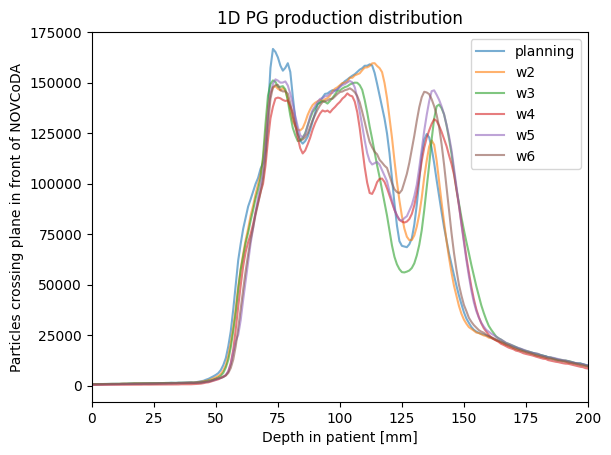

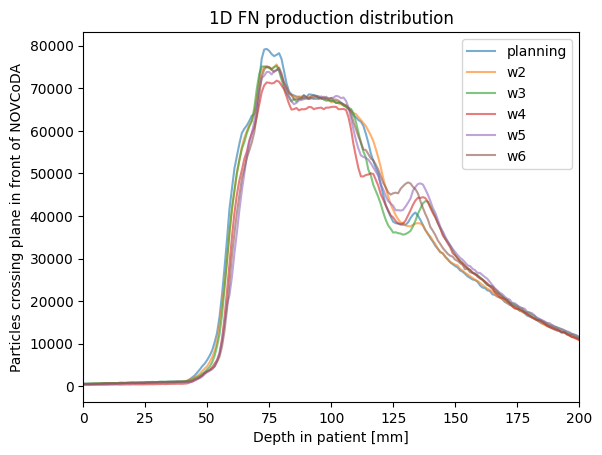

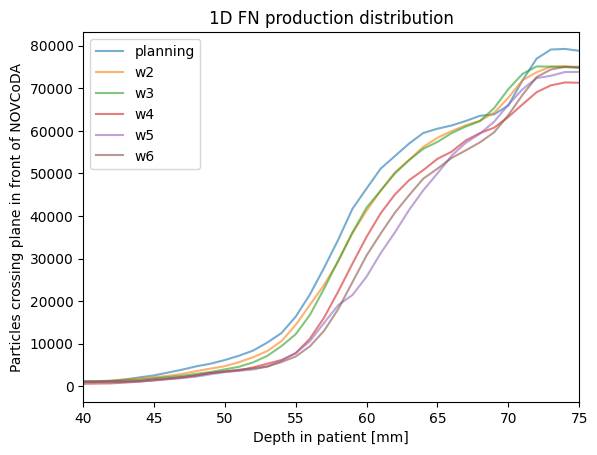

In [9]:
from scipy.ndimage import rotate

'''
angle = 360 - 310 # find exact



image = pg_volume[:,:,79]

rotated = rotate(
    image,
    angle=angle,              # degrees
    reshape=False,         # keep original image dimensions
    order=1                # bilinear interpolation
)

plt.title("Rotated")
plt.imshow(rotated, cmap = "gray")
plt.show()

dist_1d_pg = np.zeros(pg_volume.shape[1])

for j in range(pg_volume.shape[2]):
    slice = pg_volume[:,:,j]
    
    rotated = rotate(
    slice,
    angle=angle,              # degrees
    reshape=False,         # keep original image dimensions
    order=1                # bilinear interpolation
    )

    dist_1d_pg += np.sum(rotated, axis=0)


dist_1d_pg_w2 = np.zeros(pg_volume.shape[1])

for j in range(pg_volume_w2.shape[2]):
    slice = pg_volume_w2[:,:,j]
    
    rotated = rotate(
    slice,
    angle=angle,              # degrees
    reshape=False,         # keep original image dimensions
    order=1                # bilinear interpolation
    )

    dist_1d_pg_w2 += np.sum(rotated, axis=0)'''

#plt.title("1D PG distribution for the entire patient volume")
plt.title("1D PG production distribution")
plt.plot(dist_1d_pg, label = "planning", alpha = 0.6)
plt.plot(dist_1d_pg_w2, label = "w2", alpha = 0.6)
plt.plot(dist_1d_pg_w3, label = "w3", alpha = 0.6)
plt.plot(dist_1d_pg_w4, label = "w4", alpha = 0.6)
plt.plot(dist_1d_pg_w5, label = "w5", alpha = 0.6)
plt.plot(dist_1d_pg_w6, label = "w6", alpha = 0.6)
plt.legend()
plt.xlim(0, 200)
plt.xlabel("Depth in patient [mm]")
plt.ylabel("Particles crossing plane in front of NOVCoDA")
plt.show()

#plt.title("1D FN distribution for the entire patient volume")
plt.title("1D FN production distribution")
plt.plot(dist_1d_fn, label = "planning", alpha = 0.6)
plt.plot(dist_1d_fn_w2, label = "w2", alpha = 0.6)
plt.plot(dist_1d_fn_w3, label = "w3", alpha = 0.6)
plt.plot(dist_1d_fn_w4, label = "w4", alpha = 0.6)
plt.plot(dist_1d_fn_w5, label = "w5", alpha = 0.6)
plt.plot(dist_1d_fn_w6, label = "w6", alpha = 0.6)
#plt.axvline(x = peaks[0], linestyle = "--", color = "gray")
#plt.axvline(x = peaks_w2[0], linestyle = "--", color = "gray")
plt.legend()
plt.xlim(0, 200)
plt.xlabel("Depth in patient [mm]")
plt.ylabel("Particles crossing plane in front of NOVCoDA")
plt.show()

plt.title("1D FN production distribution")
plt.plot(dist_1d_fn, label = "planning", alpha = 0.6)
plt.plot(dist_1d_fn_w2, label = "w2", alpha = 0.6)
plt.plot(dist_1d_fn_w3, label = "w3", alpha = 0.6)
plt.plot(dist_1d_fn_w4, label = "w4", alpha = 0.6)
plt.plot(dist_1d_fn_w5, label = "w5", alpha = 0.6)
plt.plot(dist_1d_fn_w6, label = "w6", alpha = 0.6)
#plt.axvline(x = peaks[0], linestyle = "--", color = "gray")
#plt.axvline(x = peaks_w2[0], linestyle = "--", color = "gray")
plt.legend()
plt.xlim(40, 75)
plt.xlabel("Depth in patient [mm]")
plt.ylabel("Particles crossing plane in front of NOVCoDA")
plt.show()

### Check scintillator interactions for spot 50  (only one exported)

In [53]:
scintillator_folder = r"C:\Users\amibe\OneDrive\Documentos\NOVO\Study3_HNC\Data_test_tog\scintillator_interactions\planning\Results_spot_50\scintillator_interactions"

scint_files = os.listdir(scintillator_folder)
print(len(scint_files))
atrack = np.array([])
mreg = np.array([])
jtrack = np.array([])
llouse = np.array([])

XSCO_prod = np.array([])
YSCO_prod = np.array([])
ZSCO_prod = np.array([])


for file in scint_files: 
    data = np.load(scintillator_folder + "/" + file)
    #print(data["jtrack"][0], data["icode"][0], data["kpart"][0])
    atrack = np.concatenate((atrack, np.array(data["atrack"])), axis = 0)
    mreg = np.concatenate((mreg, np.array(data["mreg"])), axis = 0)
    jtrack = np.concatenate((jtrack, np.array(data["jtrack"])), axis = 0)
    llouse = np.concatenate((llouse, np.array(data["llouse_list"])), axis = 0)
    XSCO_prod = np.concatenate((XSCO_prod, np.array(data["XSCO_prod"])), axis = 0)
    YSCO_prod = np.concatenate((YSCO_prod, np.array(data["YSCO_prod"])), axis = 0)
    ZSCO_prod = np.concatenate((ZSCO_prod, np.array(data["ZSCO_prod"])), axis = 0)
    

110


{np.float64(1.0), np.float64(3.0), np.float64(4.0), np.float64(7.0), np.float64(8.0), np.float64(-3.0), np.float64(-2.0)}
6.324344
[-6. -5. -4. -3. -2. -1.  0.  1.  2.  3.  4.  5.  6.  7.  8.  9.]


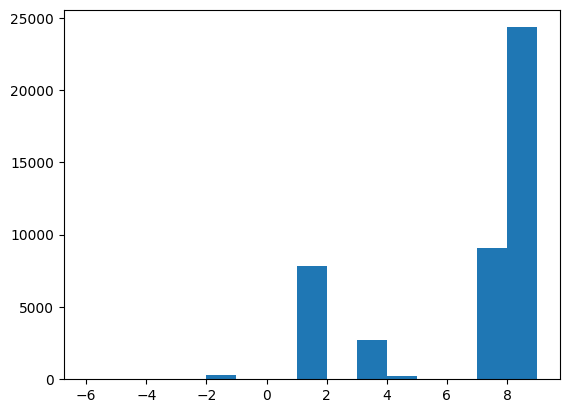

In [58]:
print(set(jtrack))
print(XSCO_prod[0])

bins = np.linspace(-6, 9, 16)
print(bins)

plt.hist(jtrack, bins = bins)
plt.show()

In [54]:
atrack_mreg_1_proton = []
atrack_mreg_1_gamma = []
atrack_mreg_1_neutron = []
print(jtrack[0])
for i in range(len(mreg)):
    if mreg[i] == 1.0 and jtrack[i] == 1.0:
        atrack_mreg_1_proton.append(atrack[i])
    if mreg[i] == 1.0 and jtrack[i] == 7.0:
        atrack_mreg_1_gamma.append(atrack[i])
    if mreg[i] == 1.0 and jtrack[i] == 8.0:
        atrack_mreg_1_neutron.append(atrack[i])

7.0


In [41]:
scintillator_folder_w2 = r"C:\Users\amibe\OneDrive\Documentos\NOVO\Study3_HNC\Data_test_tog\scintillator_interactions\w2\Results_spot_50\scintillator_interactions"

scint_files_w2 = os.listdir(scintillator_folder_w2)
print(len(scint_files_w2))
atrack_w2 = np.array([])
mreg_w2 = np.array([])
jtrack_w2 = np.array([])


for file_w2 in scint_files_w2[:81]: 
    data_w2 = np.load(scintillator_folder_w2 + "/" + file_w2)
    atrack_w2 = np.concatenate((atrack_w2, np.array(data_w2["atrack"])), axis = 0)
    mreg_w2 = np.concatenate((mreg_w2, np.array(data_w2["mreg"])), axis = 0)
    jtrack_w2 = np.concatenate((jtrack_w2, np.array(data_w2["jtrack"])), axis = 0)


110


In [59]:
atrack_mreg_1_w2 = []
for i in range(len(mreg_w2)):
    if mreg_w2[i] == 1.0 and jtrack[i] == 7.0:
        atrack_mreg_1_w2.append(atrack_w2[i])



NameError: name 'mreg_w2' is not defined

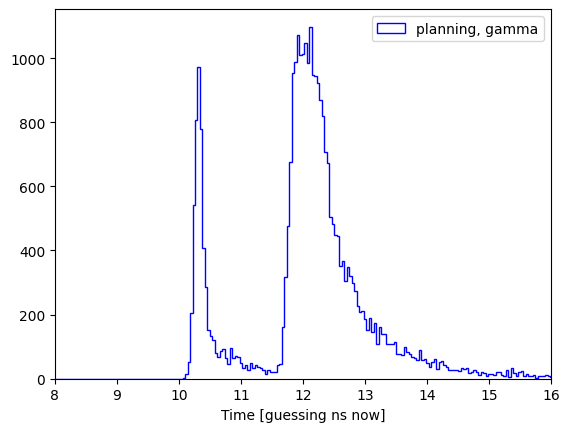

In [55]:
#print(atrack[0])
#(atrack_w2[0])

bins = np.linspace(0, 20, 500)

plt.hist(1000*np.array(atrack_mreg_1_gamma), bins = bins, histtype="step", color = "blue", label = "planning, gamma")
#plt.hist(1000*np.array(atrack_mreg_1_proton), bins = bins, histtype="step", color = "red", label = "planning, proton")
#plt.hist(1000*np.array(atrack_mreg_1_neutron), bins = bins, histtype="step", color = "green", label = "planning, neutron")
#plt.hist(1000*np.array(atrack_mreg_1_w2), bins = bins, histtype="step", color = "orange", label = "w2")
plt.xlabel("Time [guessing ns now]")
plt.xlim(8, 16)
plt.legend()
plt.show()


### Streamline timing

In [18]:
def read_hit_array(hit_array_path):
    print("Reading hit array:", hit_array_path)
    with open(hit_array_path, "r") as f:
        lines = f.readlines()
        hit_array = []
            
        for line in lines:
            elements = np.array(line.split()).astype(float)
            hit_array.append(elements)

    return np.array(hit_array)

def find_limits(time_array, lower_lim, upper_lim):
    time_array_limited_1 = []
    for i in range(len(time_array)):
        if time_array[i] > lower_lim and time_array[i] < upper_lim:
            time_array_limited_1.append(time_array[i])

    bins_time = np.linspace(0, 20, 500)

    counts,_ = np.histogram(time_array, bins = bins_time)
    max_time_idx = np.unravel_index(np.argmax(counts), counts.shape)[0]
    max_time_plan = bins_time[max_time_idx]

    lower_lim_ = max_time_plan - np.std(time_array_limited_1)
    upper_lim_ = max_time_plan + np.std(time_array_limited_1)

    return lower_lim_, upper_lim_

def find_new_mean(time_array, lower_lim, upper_lim):
    time_array_limited = []
    for i in range(len(time_array)):
        if time_array[i] > lower_lim and time_array[i] < upper_lim:
            time_array_limited.append(time_array[i])
    
    new_mean = np.mean(time_array_limited)
    return new_mean

0
Reading hit array: \\klient.uib.no\felles\LAB-IT\IFT\Medisinskfysikk\Anna\adaptive-weekly\Adaptive_weekly_5\Results_export_to_cluster2\planning/Results_spot_1/gamma_hits.txt


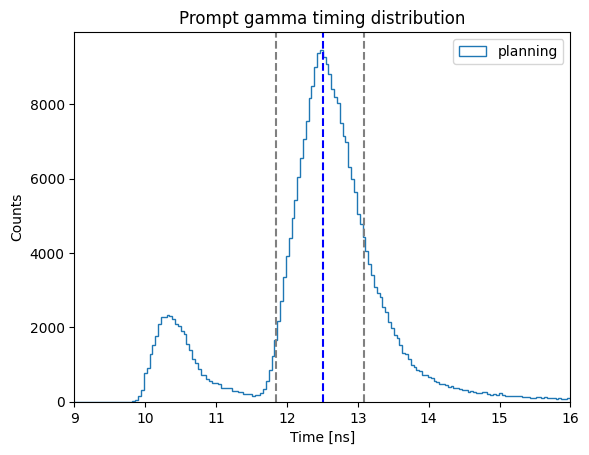

In [ ]:
overall_planning_file = r"\\klient.uib.no\felles\LAB-IT\IFT\Medisinskfysikk\Anna\adaptive-weekly\Adaptive_weekly_5\Results_export_to_cluster2\planning"
overall_w2_file = r"\\klient.uib.no\felles\LAB-IT\IFT\Medisinskfysikk\Anna\adaptive-weekly\Adaptive_weekly_5\Results_export_to_cluster2\w2"
overall_w3_file = r"\\klient.uib.no\felles\LAB-IT\IFT\Medisinskfysikk\Anna\adaptive-weekly\Adaptive_weekly_5\Results_export_to_cluster2\w3"
overall_w4_file = r"\\klient.uib.no\felles\LAB-IT\IFT\Medisinskfysikk\Anna\adaptive-weekly\Adaptive_weekly_5\Results_export_to_cluster2\w4"
overall_w5_file = r"\\klient.uib.no\felles\LAB-IT\IFT\Medisinskfysikk\Anna\adaptive-weekly\Adaptive_weekly_5\Results_export_to_cluster2\w5"
overall_w6_file = r"\\klient.uib.no\felles\LAB-IT\IFT\Medisinskfysikk\Anna\adaptive-weekly\Adaptive_weekly_5\Results_export_to_cluster2\w6"


planning_files = os.listdir(overall_planning_file)

save_path = r"C:\Users\amibe\OneDrive\Documentos\NOVO\Study3_HNC\analyze_data\Timing"

i = 0

for planning_file in planning_files:
    print(i)
    i+=1
    if "Results" in planning_file:
        rows = []

        hit_array_path_planning = overall_planning_file + "/" + planning_file + "/" "gamma_hits.txt"
        #hit_array_path_w2 = overall_w2_file + "/" + planning_file + "/" "gamma_hits.txt"
        #hit_array_path_w3 = overall_w3_file + "/" + planning_file + "/" "gamma_hits.txt"
        #hit_array_path_w4 = overall_w4_file + "/" + planning_file + "/" "gamma_hits.txt"
        #hit_array_path_w5 = overall_w5_file + "/" + planning_file + "/" "gamma_hits.txt"
        #hit_array_path_w6 = overall_w6_file + "/" + planning_file + "/" "gamma_hits.txt"

        hit_array_plan = read_hit_array(hit_array_path_planning)
       # hit_array_w2 = read_hit_array(hit_array_path_w2)
       # hit_array_w3 = read_hit_array(hit_array_path_w3)
       # hit_array_w4 = read_hit_array(hit_array_path_w4)
       # hit_array_w5 = read_hit_array(hit_array_path_w5)
       # hit_array_w6 = read_hit_array(hit_array_path_w6)

        time_array_plan = 1000*hit_array_plan[:,14]
       # time_array_w2 = 1000*hit_array_w2[:,14]
       # time_array_w3 = 1000*hit_array_w3[:,14]
       # time_array_w4 = 1000*hit_array_w4[:,14]
       ## time_array_w5 = 1000*hit_array_w5[:,14]
       # time_array_w6 = 1000*hit_array_w6[:,14]

        lower_lim_, upper_lim_= find_limits(time_array_plan, 11.5, 16)
        new_mean = find_new_mean(time_array_plan, lower_lim_, upper_lim_)

        bins_time = np.linspace(0, 20, 500)

        plt.figure()
        plt.hist(time_array_plan, histtype="step", bins = bins_time, label = "planning")
        #plt.hist(time_array_w2, histtype="step", bins = bins_time, label = "w2")
        #plt.hist(time_array_w3, histtype="step", bins = bins_time, label = "w3")
        #plt.hist(time_array_w4, histtype="step", bins = bins_time, label = "w4")
        #plt.hist(time_array_w5, histtype="step", bins = bins_time, label = "w5")
        #plt.hist(time_array_w6, histtype="step", bins = bins_time, label = "w6")
        plt.title("Prompt gamma timing distribution")
        plt.axvline(x = lower_lim_, linestyle = "--", color = "gray")
        plt.axvline(x = upper_lim_, linestyle = "--", color = "gray")
        plt.axvline(x = new_mean, linestyle = "--", color = "blue")
        plt.xlabel("Time [ns]")
        plt.legend()
        plt.xlim(9, 16)
        plt.ylabel("Counts")
        plt.savefig(r"C:\Users\amibe\OneDrive\Documentos\NOVO\Study3_HNC\analyze_data\Timing" + "/" + planning_file + ".png", dpi=300, bbox_inches="tight")
        plt.show()

        break
    break


        #plt.legend()
        #plt.xlim(150,350)
        #        plt.ylabel("Intensity")
        #        plt.xlabel("Distance from beam [mm]")
        #        plt.savefig(r"C:\Users\amibe\OneDrive\Documentos\NOVO\Study3_HNC\analyze_data\png" + "/" + planning_file + ".png", dpi=300, bbox_inches="tight")
        #        plt.show()
        
        #        df = pd.DataFrame(rows)
        #        df.to_excel(r"C:\Users\amibe\OneDrive\Documentos\NOVO\Study3_HNC\analyze_data\excel" + "/" + planning_file + ".xlsx", index=False)


        


        
             

### Check spot

In [192]:
gamma_hits_file = r"\\klient.uib.no\felles\LAB-IT\IFT\Medisinskfysikk\Anna\adaptive-weekly\Adaptive_weekly_5\Results_export_to_cluster2\planning\Results_spot_32\gamma_hits.txt"
neutron_hits_file = r"\\klient.uib.no\felles\LAB-IT\IFT\Medisinskfysikk\Anna\adaptive-weekly\Adaptive_weekly_5\Results_export_to_cluster2\planning\Results_spot_32\neutron_hits.txt"
#r"c:\Users\amibe\OneDrive\Documentos\NOVO\Study3_HNC\Data_test_tog\scintillator_interactions\planning\gamma_hits.txt"
#gamma_hits_file_w2 = r"\\klient.uib.no\felles\LAB-IT\IFT\Medisinskfysikk\Anna\adaptive-weekly\Adaptive_weekly_5\Results_export_to_cluster2\w2\Results_spot_\gamma_hits.txt"
#r"c:\Users\amibe\OneDrive\Documentos\NOVO\Study3_HNC\Data_test_tog\scintillator_interactions\planning\Results_spot_6\gamma_hits_w2.txt"
#gamma_hits_file_w3 = r"\\klient.uib.no\felles\LAB-IT\IFT\Medisinskfysikk\Anna\adaptive-weekly\Adaptive_weekly_5\Results_export_to_cluster2\w3\Results_spot_32\gamma_hits.txt"
##gamma_hits_file_w4 = r"\\klient.uib.no\felles\LAB-IT\IFT\Medisinskfysikk\Anna\adaptive-weekly\Adaptive_weekly_5\Results_export_to_cluster2\w4\Results_spot_32\gamma_hits.txt"
#gamma_hits_file_w5 = r"\\klient.uib.no\felles\LAB-IT\IFT\Medisinskfysikk\Anna\adaptive-weekly\Adaptive_weekly_5\Results_export_to_cluster2\w5\Results_spot_32\gamma_hits.txt"
gamma_hits_file_w6 = r"\\klient.uib.no\felles\LAB-IT\IFT\Medisinskfysikk\Anna\adaptive-weekly\Adaptive_weekly_5\Results_export_to_cluster2\w6\Results_spot_32\gamma_hits.txt"
#r"c:\Users\amibe\OneDrive\Documentos\NOVO\Study3_HNC\Data_test_tog\scintillator_interactions\planning\Results_spot_6\gamma_hits_w3.txt"
#r"\\klient.uib.no\felles\LAB-IT\IFT\Medisinskfysikk\Anna\adaptive-weekly\Adaptive_weekly_5\Results_export_to_cluster2\planning\Results_spot_6\gamma_hits.txt"
#r"c:\Users\amibe\OneDrive\Documentos\NOVO\Study3_HNC\Data_test_tog\scintillator_interactions\planning\Results_spot_50\gamma_hits.txt"
#r"c:\Users\amibe\OneDrive\Documentos\NOVO\Study3_HNC\Data_test_tog\scintillator_interactions\planning\Results_spot_50\gamma_hits.txt"
with open(gamma_hits_file, "r") as f:
    lines = f.readlines()
    hit_array = []
        
    for line in lines:
        elements = np.array(line.split()).astype(float)
        hit_array.append(elements)

hit_array_gamma = np.array(hit_array)

with open(neutron_hits_file, "r") as f:
    lines = f.readlines()
    hit_array = []
        
    for line in lines:
        elements = np.array(line.split()).astype(float)
        hit_array.append(elements)

hit_array_neutron = np.array(hit_array)



OSError: [Errno 22] Invalid argument: '\\\\klient.uib.no\\felles\\LAB-IT\\IFT\\Medisinskfysikk\\Anna\\adaptive-weekly\\Adaptive_weekly_5\\Results_export_to_cluster2\\planning\\Results_spot_32\\gamma_hits.txt'

In [30]:
#r"c:\Users\amibe\OneDrive\Documentos\NOVO\Study3_HNC\Data_test_tog\scintillator_interactions\w2\Results_spot_50\gamma_hits.txt"
with open(gamma_hits_file_w2, "r") as f:
    lines = f.readlines()
    hit_array_w2 = []
        
    for line in lines:
        elements = np.array(line.split()).astype(float)
        hit_array_w2.append(elements)

hit_array_w2 = np.array(hit_array_w2)

#r"c:\Users\amibe\OneDrive\Documentos\NOVO\Study3_HNC\Data_test_tog\scintillator_interactions\w3\Results_spot_50\gamma_hits.txt"
with open(gamma_hits_file_w3, "r") as f:
    lines = f.readlines()
    hit_array_w3 = []
        
    for line in lines:
        elements = np.array(line.split()).astype(float)
        hit_array_w3.append(elements)

hit_array_w3 = np.array(hit_array_w3)

with open(gamma_hits_file_w4, "r") as f:
    lines = f.readlines()
    hit_array_w4 = []
        
    for line in lines:
        elements = np.array(line.split()).astype(float)
        hit_array_w4.append(elements)

hit_array_w4 = np.array(hit_array_w4)

with open(gamma_hits_file_w5, "r") as f:
    lines = f.readlines()
    hit_array_w5 = []
        
    for line in lines:
        elements = np.array(line.split()).astype(float)
        hit_array_w5.append(elements)

hit_array_w5 = np.array(hit_array_w5)

with open(gamma_hits_file_w6, "r") as f:
    lines = f.readlines()
    hit_array_w6 = []
        
    for line in lines:
        elements = np.array(line.split()).astype(float)
        hit_array_w6.append(elements)

hit_array_w6 = np.array(hit_array_w6)

### Production coordinates (gamma)

In [140]:
def find_1D_distribution(hit_array_, binary_mask, angle, time_constraint = False, time_constraint_param_lower = None, time_constraint_param_upper = None, layer_number = None):
    XSCO_prod_d  = hit_array_[:,15]
    YSCO_prod_d  = hit_array_[:,16]
    ZSCO_prod_d  = hit_array_[:,17]

    energy = hit_array_[:, 8]

    coordinates = []
    time_array_limited = []
    energy_limited = []

    if time_constraint:
        time_array = hit_array_[:,14]
        mreg_array = hit_array_[:,12]
        time_array_ns = 1000*np.array(time_array)
        
        for i in range(len(XSCO_prod_d)):
                if time_array_ns[i] < time_constraint_param_upper and time_array_ns[i] > time_constraint_param_lower and mreg_array[i] > 4*(layer_number - 1) and  mreg_array[i] <= 4*(layer_number) and energy[i] < 1000:
                    coordinates.append(np.array([XSCO_prod_d[i], YSCO_prod_d[i], ZSCO_prod_d[i]]))
                    time_array_limited.append(time_array_ns[i])
                    energy_limited.append(energy[i])
    else:
        for i in range(len(XSCO_prod_d)):
            coordinates.append(np.array([XSCO_prod_d[i], YSCO_prod_d[i], ZSCO_prod_d[i]]))

    coordinates = np.array(coordinates)

    dose_shape = (573, 315, 117)

    #min_coords = [-27.57, -9.949, -21.23]
    min_coords = [-27.719, -12.852159, -18.459676]
    max_coords = [29.5809999, 18.64784, 16.640324]


    edges = [
            np.linspace(min_coords[i], max_coords[i], dose_shape[i] + 1)
            for i in range(3)
        ]
    hist, _ = np.histogramdd(coordinates, bins=edges)
    hist = np.transpose(hist, axes = (2, 1, 0))

    img = rotate(
                hist*binary_mask,
                angle=angle,
                axes=(1, 2),   # rotate in the y-x plane
                #reshape = True
                reshape=False, 
                order = 1
            )

    profile_particle = img.sum(axis=(0,1))


    return profile_particle, time_array_limited, energy_limited, energy

angle = np.degrees(np.arccos(0.778454))#(0.775968))#0.754750))
print(angle)

#define angle from dat file 
#profile_plan_pg = find_1D_distribution(hit_array_gamma, binary_mask_plan, angle)

#profile_plan_fn = find_1D_distribution(hit_array_neutron, binary_mask_plan, angle)

#profile_w2_pg = find_1D_distribution(hit_array_w2, binary_mask_plan, angle)
#profile_w3_pg = find_1D_distribution(hit_array_w3, binary_mask_c2, angle)
#profile_w4_pg = find_1D_distribution(hit_array_w4, binary_mask_c3, angle)
#profile_w5_pg = find_1D_distribution(hit_array_w5, binary_mask_c4, angle)
#profile_w6_pg = find_1D_distribution(hit_array_w6, binary_mask_c5, angle)


38.88075776230542


0.049090909090909095


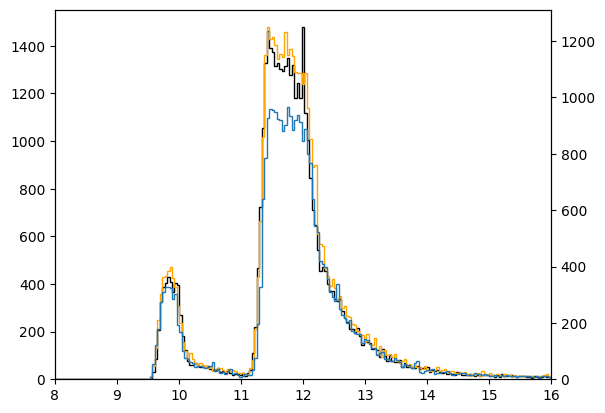

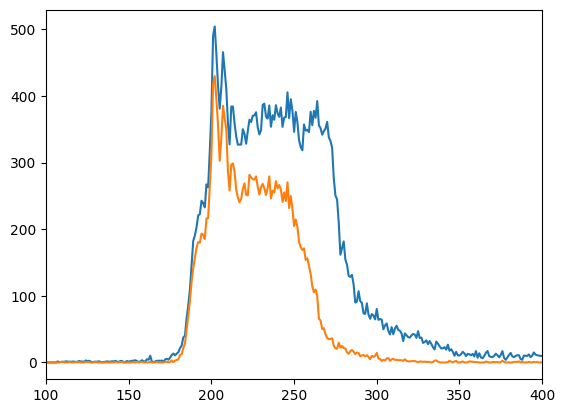

In [195]:
profile_plan_pg_layer_1, time_array_limited, energy_limited, energy_whole = find_1D_distribution(hit_array_gamma, binary_mask_plan, angle, time_constraint=True, time_constraint_param_lower=0, time_constraint_param_upper=20, layer_number = 1)
profile_plan_pg_layer_2, time_array_limited_layer_2, _, _ = find_1D_distribution(hit_array_gamma, binary_mask_plan, angle, time_constraint=True, time_constraint_param_lower=0, time_constraint_param_upper=20, layer_number = 2)
profile_plan_pg_layer_3, time_array_limited_layer_3, _, _ = find_1D_distribution(hit_array_gamma, binary_mask_plan, angle, time_constraint=True, time_constraint_param_lower=0, time_constraint_param_upper=20, layer_number = 3)
profile_plan_pg_layer_4, time_array_limited_layer_4, _, _ = find_1D_distribution(hit_array_gamma, binary_mask_plan, angle, time_constraint=True, time_constraint_param_lower=0, time_constraint_param_upper=20, layer_number = 4)
profile_plan_pg_layer_5, time_array_limited_layer_5, _, _ = find_1D_distribution(hit_array_gamma, binary_mask_plan, angle, time_constraint=True, time_constraint_param_lower=0, time_constraint_param_upper=20, layer_number = 5)
profile_plan_pg_layer_6, time_array_limited_layer_6, _, _ = find_1D_distribution(hit_array_gamma, binary_mask_plan, angle, time_constraint=True, time_constraint_param_lower=0, time_constraint_param_upper=20, layer_number = 6)
profile_plan_pg_layer_7, time_array_limited_layer_7, _, _ = find_1D_distribution(hit_array_gamma, binary_mask_plan, angle, time_constraint=True, time_constraint_param_lower=0, time_constraint_param_upper=20, layer_number = 7)
profile_plan_pg_layer_8, time_array_limited_layer_8, _, _ = find_1D_distribution(hit_array_gamma, binary_mask_plan, angle, time_constraint=True, time_constraint_param_lower=0, time_constraint_param_upper=20, layer_number = 8)
profile_plan_pg_layer_9, time_array_limited_layer_9, _, _ = find_1D_distribution(hit_array_gamma, binary_mask_plan, angle, time_constraint=True, time_constraint_param_lower=0, time_constraint_param_upper=20, layer_number = 9)
profile_plan_pg_layer_10, time_array_limited_layer_10, _, _ = find_1D_distribution(hit_array_gamma, binary_mask_plan, angle, time_constraint=True, time_constraint_param_lower=0, time_constraint_param_upper=20, layer_number = 10)
profile_plan_pg_layer_11, time_array_limited_layer_11, _, _ = find_1D_distribution(hit_array_gamma, binary_mask_plan, angle, time_constraint=True, time_constraint_param_lower=0, time_constraint_param_upper=20, layer_number = 11)
profile_plan_pg_layer_12, time_array_limited_layer_12, _, _ = find_1D_distribution(hit_array_gamma, binary_mask_plan, angle, time_constraint=True, time_constraint_param_lower=0, time_constraint_param_upper=20, layer_number = 12)







profile_plan_pg_layer_12, time_array_limited_layer_12, _, _ = find_1D_distribution(hit_array_gamma, binary_mask_plan, angle, time_constraint=True, time_constraint_param_lower=0, time_constraint_param_upper=20, layer_number = 12)

corr_factor = 0.54/11 
print(corr_factor)

time_array_limited_layer_2_corr = np.array(time_array_limited_layer_2) - corr_factor
time_array_limited_layer_3_corr = np.array(time_array_limited_layer_3) - 2*corr_factor
time_array_limited_layer_4_corr = np.array(time_array_limited_layer_4) - 3*corr_factor
time_array_limited_layer_5_corr = np.array(time_array_limited_layer_5) - 4*corr_factor
time_array_limited_layer_6_corr = np.array(time_array_limited_layer_6) - 5*corr_factor

time_array_limited_layer_7_corr = np.array(time_array_limited_layer_7) - 6*corr_factor
time_array_limited_layer_8_corr = np.array(time_array_limited_layer_8) - 7*corr_factor
time_array_limited_layer_9_corr = np.array(time_array_limited_layer_9) - 8*corr_factor
time_array_limited_layer_10_corr = np.array(time_array_limited_layer_10) - 9*corr_factor
time_array_limited_layer_11_corr = np.array(time_array_limited_layer_11) - 10*corr_factor
#time_array_limited_layer_12_corr = np.array(time_array_limited_layer_6) - 5*corr_factor




time_array_limited_layer_12_corr = np.array(time_array_limited_layer_12) - 0.54

bins_time = np.linspace(8, 16, 200)

fig, ax1 = plt.subplots()
ax1.hist(time_array_limited, bins = bins_time, histtype = "step", color = "black")
#ax1.hist(time_array_limited_timelim, bins = bins_time, histtype = "step")
ax2 = ax1.twinx()
ax2.hist(time_array_limited_layer_2_corr, bins = bins_time, histtype = "step", color = "orange")
ax2.hist(time_array_limited_layer_4_corr, bins = bins_time, histtype = "step")
plt.xlabel("time [ns]")
plt.xlim(8, 16)
plt.show()

plt.figure()
plt.plot(profile_plan_pg_layer_1)
plt.plot(profile_plan_pg_layer_1_timelim)
plt.xlim(100, 400)
plt.show()

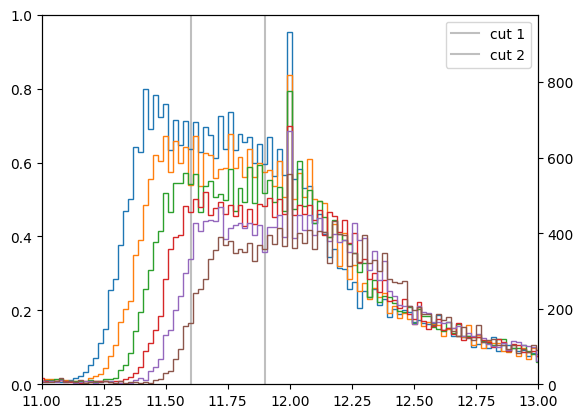

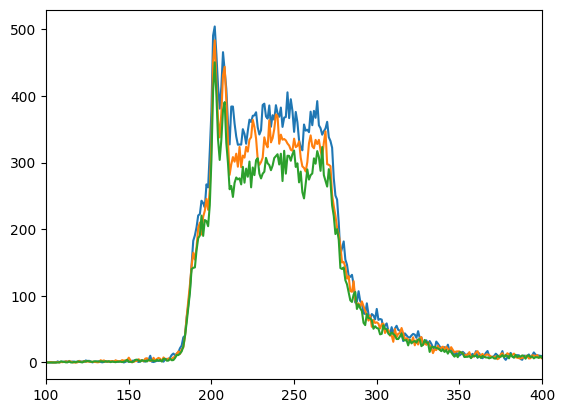

In [220]:
time_array_limited_sum = np.concatenate((time_array_limited, time_array_limited_layer_2_corr, time_array_limited_layer_3_corr, time_array_limited_layer_4_corr, time_array_limited_layer_5_corr, time_array_limited_layer_6_corr, time_array_limited_layer_7_corr, time_array_limited_layer_8_corr, time_array_limited_layer_9_corr, time_array_limited_layer_10_corr, time_array_limited_layer_11_corr, time_array_limited_layer_12_corr), axis = 0)
time_array_limited_sum_wo_corr = np.concatenate((time_array_limited, time_array_limited_layer_2, time_array_limited_layer_3, time_array_limited_layer_4, time_array_limited_layer_5, time_array_limited_layer_6, time_array_limited_layer_7, time_array_limited_layer_8, time_array_limited_layer_9, time_array_limited_layer_10, time_array_limited_layer_11, time_array_limited_layer_12), axis = 0)


bins_time = np.linspace(8, 16, 400)

fig, ax1 = plt.subplots()
#ax1.hist(time_array_limited_sum, bins = bins_time, histtype = "step", color = "black")
#ax1.hist(time_array_limited_sum_wo_corr, bins = bins_time, histtype = "step", color = "black")
ax1.axvline(x = 11.6, color = "gray", alpha = 0.5, label = "cut 1")
ax1.axvline(x = 11.9, color = "gray", alpha = 0.5, label = "cut 2")
ax1.legend()
#ax1.hist(time_array_limited_timelim, bins = bins_time, histtype = "step")
ax2 = ax1.twinx()
ax2.hist(time_array_limited, bins = bins_time, histtype = "step")
ax2.hist(time_array_limited_layer_2, bins = bins_time, histtype = "step")
ax2.hist(time_array_limited_layer_3, bins = bins_time, histtype = "step")
ax2.hist(time_array_limited_layer_4, bins = bins_time, histtype = "step")
ax2.hist(time_array_limited_layer_5, bins = bins_time, histtype = "step")
ax2.hist(time_array_limited_layer_6, bins = bins_time, histtype = "step")
#ax2.hist(time_array_limited_layer_7_corr, bins = bins_time, histtype = "step")
#ax2.hist(time_array_limited_layer_8_corr, bins = bins_time, histtype = "step")
#ax2.hist(time_array_limited_layer_9_corr, bins = bins_time, histtype = "step")
#ax2.hist(time_array_limited_layer_10_corr, bins = bins_time, histtype = "step")
#ax2.hist(time_array_limited_layer_11_corr, bins = bins_time, histtype = "step")
#ax2.hist(time_array_limited_layer_12_corr, bins = bins_time, histtype = "step")
plt.xlabel("time [ns]")
plt.xlim(11, 13)

plt.show()

profile_plan_pg_layer_1_timelim, time_array_limited_timelim, _,_ = find_1D_distribution(hit_array_gamma, binary_mask_plan, angle, time_constraint=True, time_constraint_param_lower=0, time_constraint_param_upper=11.6, layer_number = 1)
profile_plan_pg_layer_1_timelim, time_array_limited_timelim_2, _,_ = find_1D_distribution(hit_array_gamma, binary_mask_plan, angle, time_constraint=True, time_constraint_param_lower=0, time_constraint_param_upper=11.9, layer_number = 1)


plt.figure()
plt.plot(profile_plan_pg_layer_1)
plt.plot(profile_plan_pg_layer_2)
plt.plot(profile_plan_pg_layer_3)
plt.xlim(100, 400)
plt.show()

In [138]:
#profile_plan_fn, time_array_fn, _ = find_1D_distribution(hit_array_neutron, binary_mask_plan, angle, time_constraint=True, time_constraint_param_lower=0, time_constraint_param_upper=100.0, layer_number = 1)



#profile_plan_pg_12 = find_1D_distribution(hit_array_gamma, binary_mask_plan, angle, time_constraint=True, time_constraint_param=12.4525)
#profile_plan_pg_12 = find_1D_distribution(hit_array_gamma, binary_mask_plan, angle, time_constraint=True, time_constraint_param_lower=11.8, time_constraint_param_upper=12.5, layer_number = 12)
#profile_plan_pg_13 = find_1D_distribution(hit_array_gamma, binary_mask_plan, angle, time_constraint=True, time_constraint_param_lower=11.8, time_constraint_param_upper=13.0, layer_number = 12)
profile_plan_pg_16_layer_1, time_array_limited, energy_limited, energy_whole = find_1D_distribution(hit_array_gamma, binary_mask_plan, angle, time_constraint=True, time_constraint_param_lower=0, time_constraint_param_upper=16.0, layer_number = 1)
profile_plan_pg_14_layer_1, time_array_limited_12, energy_limited_12 = find_1D_distribution(hit_array_gamma, binary_mask_plan, angle, time_constraint=True, time_constraint_param_lower=0, time_constraint_param_upper=14, layer_number = 1)
#profile_plan_pg_115_layer_1, time_array_limited_115, energy_limited_115 = find_1D_distribution(hit_array_gamma, binary_mask_plan, angle, time_constraint=True, time_constraint_param_lower=10.5, time_constraint_param_upper=12.3, layer_number = 1)
#profile_plan_pg_16_layer_1, time_array_limited_16,  energy_limited_16 = find_1D_distribution(hit_array_gamma, binary_mask_plan, angle, time_constraint=True, time_constraint_param_lower=12.3, time_constraint_param_upper=16, layer_number = 1)
#profile_plan_pg_14_layer_1 = find_1D_distribution(hit_array_gamma, binary_mask_plan, angle, time_constraint=True, time_constraint_param_lower=11, time_constraint_param_upper=14, layer_number = 1)
#profile_plan_pg_14_layer_12 = find_1D_distribution(hit_array_gamma, binary_mask_plan, angle, time_constraint=True, time_constraint_param_lower=11.8, time_constraint_param_upper=13.0 + 0.66, layer_number = 12)


#profile_plan_fn = find_1D_distribution(hit_array_neutron, binary_mask_plan, angle)

#profile_w2_pg_119 = find_1D_distribution(hit_array_w2, binary_mask_plan, angle,time_constraint=True, time_constraint_param_lower=11.8, time_constraint_param_upper=13.0, layer_number = 1)
##profile_w3_pg_time = find_1D_distribution(hit_array_w3, binary_mask_c2, angle, time_constraint=True, time_constraint_param=14)
#profile_w4_pg_time = find_1D_distribution(hit_array_w4, binary_mask_c3, angle, time_constraint=True, time_constraint_param=14)
#profile_w5_pg_time = find_1D_distribution(hit_array_w5, binary_mask_c4, angle, time_constraint=True, time_constraint_param=14)
#profile_w6_pg_time = find_1D_distribution(hit_array_w6, binary_mask_c5, angle, time_constraint=True, time_constraint_param=14)

ValueError: too many values to unpack (expected 3)

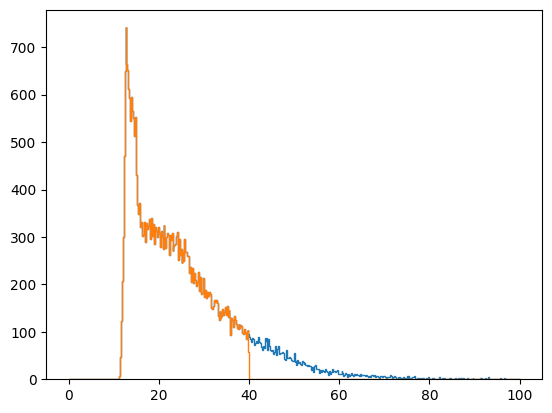

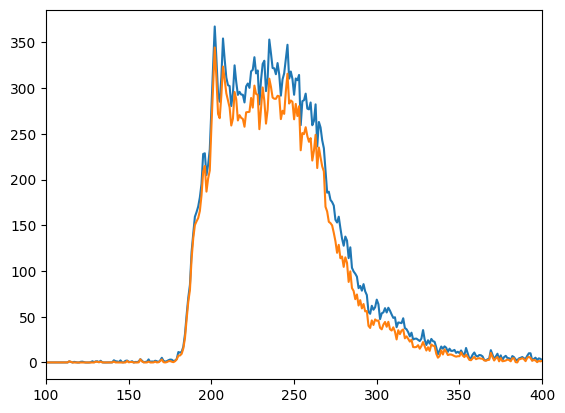

In [124]:
profile_plan_fn, time_array_fn, _ = find_1D_distribution(hit_array_neutron, binary_mask_plan, angle, time_constraint=True, time_constraint_param_lower=0, time_constraint_param_upper=100, layer_number = 1)
profile_plan_fn_lim, time_array_fn_lim, _ = find_1D_distribution(hit_array_neutron, binary_mask_plan, angle, time_constraint=True, time_constraint_param_lower=0, time_constraint_param_upper=40, layer_number = 1)
#profile_plan_fn, time_array_fn, _ = find_1D_distribution(hit_array_neutron, binary_mask_plan, angle, time_constraint=True, time_constraint_param_lower=0, time_constraint_param_upper=100.0, layer_number = 1)

bins_time_neutrons = np.linspace(0,100, 500 )

plt.figure()
plt.hist(time_array_fn, bins = bins_time_neutrons, histtype = "step")
plt.hist(time_array_fn_lim, bins = bins_time_neutrons, histtype = "step")
plt.show()

plt.figure()
plt.plot(profile_plan_fn)
plt.plot(profile_plan_fn_lim)
plt.xlim(100, 400)
plt.show()

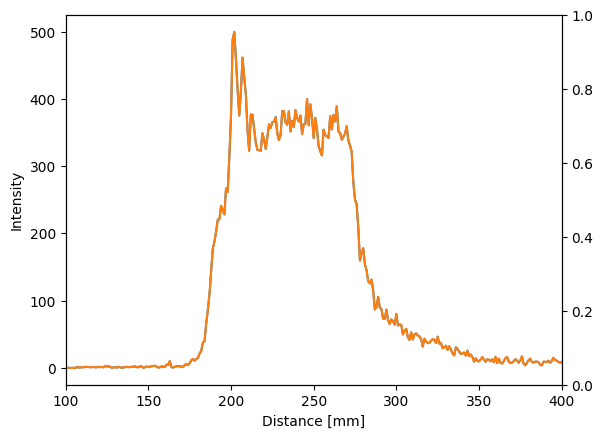

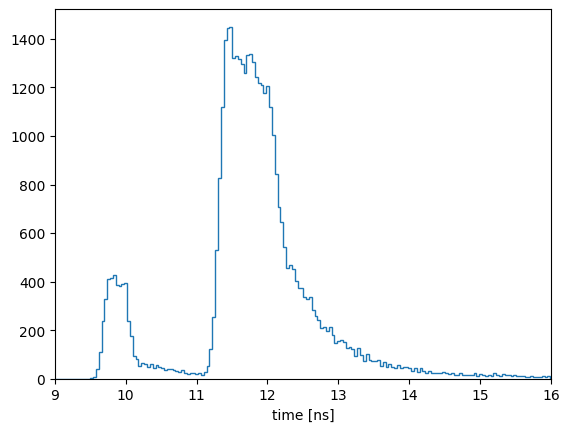

1000.0


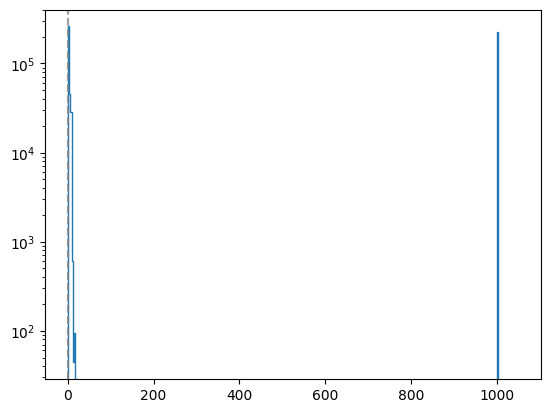

In [139]:
fig, ax1 = plt.subplots()
#ax1.plot(profile_plan_pg/10, label = "planning")
#ax1.plot(profile_w2_pg/10, label = "w2")
#ax1.plot(profile_plan_pg_12, label = "planning - 12.5 ns")
#ax1.plot(profile_plan_pg_12, label = "planning [11.8, 12.5] ns")
#ax1.plot(profile_plan_pg_13, label = "planning [11.8, 13] ns")
ax1.plot(profile_plan_pg_16_layer_1, label = "layer 1")
ax1.plot(profile_plan_pg_14_layer_1, label = "layer 1")
#ax1.plot(profile_plan_pg_12_layer_1, label = "layer 1, 12 ns")
#ax1.plot(profile_plan_pg_16_layer_1, label = "layer 1, 16 ns")
#ax1.plot(profile_plan_pg_115_layer_1, label = "layer 1,  ns")
ax2 = ax1.twinx()

#ax2.plot(time_array_limited, label = "layer 12", color = "orange")
#ax2.legend()
#ax1.plot(profile_w2_pg_119, label = "planning - 13 tns")

#ax1.legend(loc = "lower center")
ax1.set_xlabel("Distance [mm]")
ax1.set_ylabel("Intensity")
plt.xlim(100, 400)
plt.show()

bins = np.linspace(0, 20, 500)

plt.figure()
plt.hist(time_array_limited, bins = bins, histtype = "step")
#plt.hist(time_array_limited_12, bins = bins, histtype = "step")
#plt.hist(time_array_limited_16, bins = bins, histtype = "step")
#plt.hist(time_array_limited_115, bins = bins, histtype = "step")
#plt.axvline(x = 12)
plt.xlim(9, 16)
plt.xlabel("time [ns]")
plt.show()

bins_energy = np.linspace(0, 1050, 350)
print(max(energy_whole))

plt.figure()
plt.hist(energy_whole, bins = bins_energy, histtype = "step")
#plt.hist(energy_limited_12, bins = bins_energy, histtype = "step")
#plt.hist(energy_limited_16, bins = bins_energy, histtype="step")
plt.axvline(0.72, linestyle = "--", color = "gray", alpha = 0.5)
plt.axvline(0.511, linestyle = "--", color = "gray", alpha = 0.5)
plt.yscale("log")

plt.show()

In [123]:
XSCO_prod_d  = hit_array_neutron[:,15]
YSCO_prod_d  = hit_array_neutron[:,16]
ZSCO_prod_d  = hit_array_neutron[:,17]

coordinates_fn = []

for i in range(len(XSCO_prod_d)):
    coordinates_fn.append(np.array([XSCO_prod_d[i], YSCO_prod_d[i], ZSCO_prod_d[i]]))

coordinates_fn = np.array(coordinates_fn)

dose_shape = (573, 315, 117)

#min_coords = [-27.57, -9.949, -21.23]
min_coords = [-27.719, -12.852159, -18.459676]
max_coords = [29.5809999, 18.64784, 16.640324]


edges = [
        np.linspace(min_coords[i], max_coords[i], dose_shape[i] + 1)
        for i in range(3)
    ]
hist_fn, _ = np.histogramdd(coordinates_fn, bins=edges)
hist_fn = np.transpose(hist_fn, axes = (2, 1, 0))

plan_fn_img = rotate(
             hist_fn*binary_mask_plan,
             angle=angle,
             axes=(1, 2),   # rotate in the y-x plane
             #reshape = True
             reshape=False, 
             order = 1
         )

profile_fn = plan_fn_img.sum(axis=(0,1))



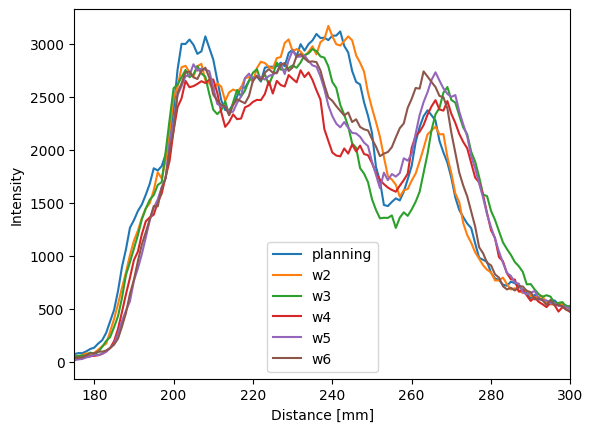

In [14]:
fig, ax1 = plt.subplots()
ax1.plot(profile_plan_pg, label = "planning")
ax1.plot(profile_w2_pg, label = "w2")
ax1.plot(profile_w3_pg, label = "w3")
ax1.plot(profile_w4_pg, label = "w4")
ax1.plot(profile_w5_pg, label = "w5")
ax1.plot(profile_w6_pg, label = "w6")
ax1.legend(loc = "lower center")

#ax2 = ax1.twinx()
#ax2.plot(profile_fn, label = "FN", color = "orange")#
#ax2.legend(loc = "upper right")

#ax3 = ax1.twinx()
#ax3.spines['right'].set_position(('outward', 40))
#ax3.plot(profile, label = "Dose", color = "black")
#ax3.set_yticks([])
#ax3.tick_params(right=False, labelright=False)
#ax3.legend(loc = "upper center")
ax1.set_xlabel("Distance [mm]")
ax1.set_ylabel("Intensity")
plt.xlim(175, 300)
plt.show()

#### Energy deposition

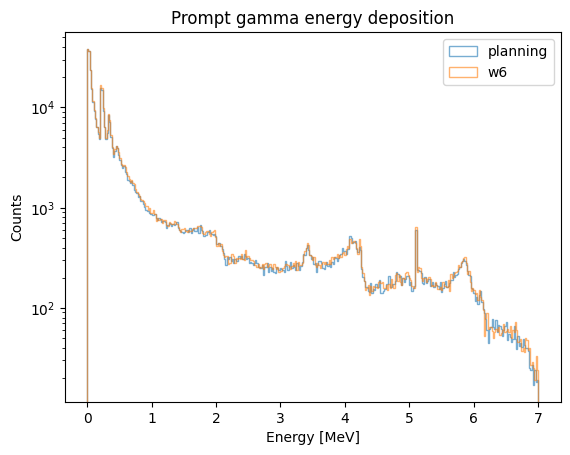

In [38]:
energy_dep  = hit_array[:,7]
#energy_dep_w2  = hit_array_w2[:,7]
#energy_dep_w3  = hit_array_w3[:,7]
#energy_dep_w4  = hit_array_w4[:,7]
#energy_dep_w5  = hit_array_w5[:,7]
energy_dep_w6  = hit_array_w6[:,7]
#print(time_array[0])

bins = np.linspace(0, 7, 350)

#plt.hist(energy_dep_w2, bins = bins, histtype="step", label = "w2", alpha = 0.6)
plt.hist(energy_dep, bins = bins, histtype="step", label = "planning", alpha = 0.6)
#plt.hist(energy_dep_w2, bins = bins, histtype="step", label = "w2", alpha = 0.6, density = True)
#plt.hist(energy_dep_w3, bins = bins, histtype="step", label = "w3", alpha = 0.6, density = True)
#plt.hist(energy_dep_w4, bins = bins, histtype="step", label = "w4", alpha = 0.6)
#plt.hist(energy_dep_w5, bins = bins, histtype="step", label = "w5", alpha = 0.6)
plt.hist(energy_dep_w6, bins = bins, histtype="step", label = "w6", alpha = 0.6)
plt.yscale("log")
plt.xlabel("Energy [MeV]")
plt.title("Prompt gamma energy deposition")
#plt.ylim(100, 1000)
plt.ylabel("Counts")
plt.legend()

plt.show()


#counts_w2, bins_ = np.histogram(energy_dep_w2, bins=bins)
#counts_norm_w2 = counts_w2 / counts_w2.sum()

#counts_w3, bins_ = np.histogram(energy_dep_w3, bins=bins)
#counts_norm_w3 = counts_w3 / counts_w3.sum()

#plt.plot(bins_[:-1], counts_norm_w2)
#plt.plot(bins_[:-1], counts_norm_w3, alpha = 0.8)
#plt.yscale("log")
#plt.ylim(0, 0.003)
#plt.show()



#### Timing

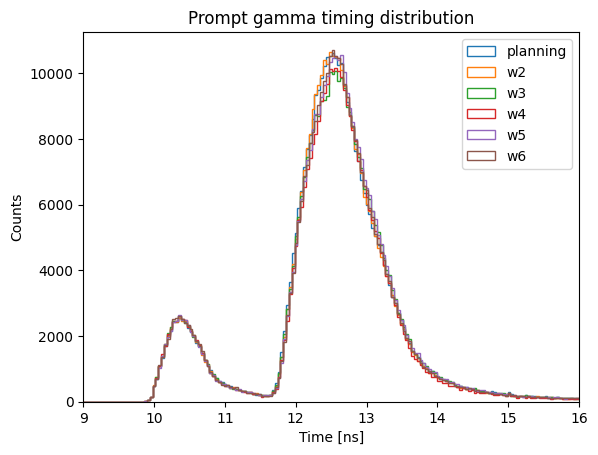

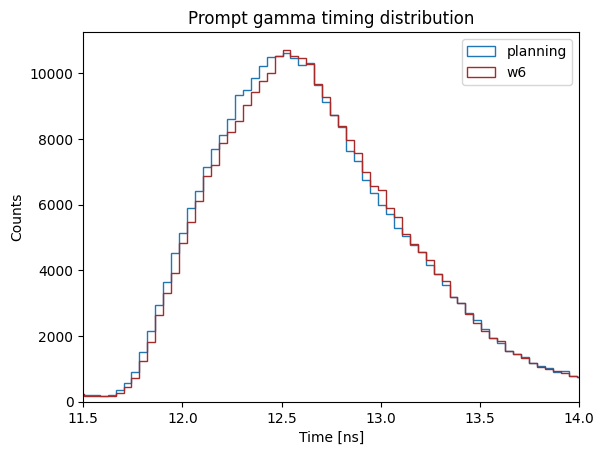

'\nplt.figure()\nplt.hist(1000*np.array(time_array), histtype="step", bins = bins_time, label = "planning")\n#plt.hist(1000*np.array(time_array_w2), histtype="step", bins = bins_time, label = "w2")\n##plt.hist(1000*np.array(time_array_w3), histtype="step", bins = bins_time, label = "w3")\n#plt.hist(1000*np.array(time_array_w4), histtype="step", bins = bins_time, label = "w4")\n#plt.hist(1000*np.array(time_array_w5), histtype="step", bins = bins_time, label = "w5")\nplt.hist(1000*np.array(time_array_w6), histtype="step", bins = bins_time, label = "w6")\n\nplt.axvline(x = 12.4)\n#plt.axvline(x = 13.35-0.5)\n#plt.axvline(x = 13.35+0.5)\n\nplt.title("Prompt gamma timing distribution")\nplt.xlabel("Time [ns]")\nplt.legend()\nplt.xlim(11.5, 12.5)\nplt.ylabel("Counts")\nplt.show()'

In [7]:
time_array = hit_array_gamma[:,14]
time_array_w2 = hit_array_w2[:,14]
time_array_w3 = hit_array_w3[:,14]
time_array_w4 = hit_array_w4[:,14]
time_array_w5 = hit_array_w5[:,14]
time_array_w6 = hit_array_w6[:,14]
bins_time = np.linspace(0, 20, 500)

plt.figure()
#plt.axvline(x = 12.42-1)
#plt.axvline(x = 12.42+1)
plt.hist(1000*np.array(time_array), histtype="step", bins = bins_time, label = "planning")
plt.hist(1000*np.array(time_array_w2), histtype="step", bins = bins_time, label = "w2")
plt.hist(1000*np.array(time_array_w3), histtype="step", bins = bins_time, label = "w3")
plt.hist(1000*np.array(time_array_w4), histtype="step", bins = bins_time, label = "w4")
plt.hist(1000*np.array(time_array_w5), histtype="step", bins = bins_time, label = "w5")
plt.hist(1000*np.array(time_array_w6), histtype="step", bins = bins_time, label = "w6")

#plt.axvline(x = 13.35)
#plt.axvline(x = 13.35-0.5)
#plt.axvline(x = 13.35+0.5)


plt.title("Prompt gamma timing distribution")
plt.xlabel("Time [ns]")
plt.legend()
plt.xlim(9, 16)
plt.ylabel("Counts")
plt.show()

plt.figure()
#plt.axvline(x = 12.42-1)
#plt.axvline(x = 12.42+1)

plt.hist(1000*np.array(time_array), histtype="step", bins = bins_time, label = "planning")
#plt.hist(1000*np.array(time_array_w2), histtype="step", bins = bins_time, label = "w2")
#plt.hist(1000*np.array(time_array_w3), histtype="step", bins = bins_time, label = "w3", color = "green")
#plt.hist(1000*np.array(time_array_w4), histtype="step", bins = bins_time, label = "w4", color = "red")
#plt.hist(1000*np.array(time_array_w5), histtype="step", bins = bins_time, label = "w5", color = "purple")
plt.hist(1000*np.array(time_array_w6), histtype="step", bins = bins_time, label = "w6", color = "brown")

#plt.axvline(x = 13.35)
#plt.axvline(x = 13.35-0.5)
#plt.axvline(x = 13.35+0.5)


plt.title("Prompt gamma timing distribution")
plt.xlabel("Time [ns]")
plt.legend()
plt.xlim(11.5, 14)
plt.ylabel("Counts")
plt.show()

'''
plt.figure()
plt.hist(1000*np.array(time_array), histtype="step", bins = bins_time, label = "planning")
#plt.hist(1000*np.array(time_array_w2), histtype="step", bins = bins_time, label = "w2")
##plt.hist(1000*np.array(time_array_w3), histtype="step", bins = bins_time, label = "w3")
#plt.hist(1000*np.array(time_array_w4), histtype="step", bins = bins_time, label = "w4")
#plt.hist(1000*np.array(time_array_w5), histtype="step", bins = bins_time, label = "w5")
plt.hist(1000*np.array(time_array_w6), histtype="step", bins = bins_time, label = "w6")

plt.axvline(x = 12.4)
#plt.axvline(x = 13.35-0.5)
#plt.axvline(x = 13.35+0.5)

plt.title("Prompt gamma timing distribution")
plt.xlabel("Time [ns]")
plt.legend()
plt.xlim(11.5, 12.5)
plt.ylabel("Counts")
plt.show()'''

In [26]:
mreg_array = hit_array_gamma[:,12]
mreg_array_w2 = hit_array_w2[:,12]
mreg_array_w3 = hit_array_w3[:,12]
mreg_array_w4 = hit_array_w4[:,12]
mreg_array_w5 = hit_array_w5[:,12]
mreg_array_w6 = hit_array_w6[:,12]

time_array_layer_1 = []
time_array_layer_12 = []
time_array_layer_11 = []
time_array_layer_6 = []

time_array_layer_1_w2 = []
time_array_layer_1_w3 = []
time_array_layer_1_w4 = []
time_array_layer_1_w5 = []
time_array_layer_1_w6 = []

corr_1_12 = 0.54
corr_1_11 = corr_1_12 - corr_1_12/12

for i in range(len(mreg_array)):
    if mreg_array[i] <= 4.0:
        time_array_layer_1.append(1000*time_array[i])
    if mreg_array[i] <= 48.0 and mreg_array[i] > 44.0:
        time_array_layer_12.append(1000*time_array[i] - corr_1_12)
    if mreg_array[i] <= 44.0 and mreg_array[i] > 40.0:
            time_array_layer_11.append(1000*time_array[i] - corr_1_11)
    if mreg_array[i] <= 28.0 and mreg_array[i] > 24.0:
        time_array_layer_6.append(1000*time_array[i])

for i in range(len(mreg_array_w2)):
    if mreg_array_w2[i] <= 4.0:
        time_array_layer_1_w2.append(1000*time_array_w2[i])

for i in range(len(mreg_array_w3)):
    if mreg_array_w3[i] <= 4.0:
        time_array_layer_1_w3.append(1000*time_array_w3[i])

for i in range(len(mreg_array_w4)):
    if mreg_array_w4[i] <= 4.0:
        time_array_layer_1_w4.append(1000*time_array_w4[i])

for i in range(len(mreg_array_w5)):
    if mreg_array_w5[i] <= 4.0:
        time_array_layer_1_w5.append(1000*time_array_w5[i])

for i in range(len(mreg_array_w6)):
    if mreg_array_w6[i] <= 4.0:
        time_array_layer_1_w6.append(1000*time_array_w6[i])

counts,bins = np.histogram(time_array_layer_1, bins = bins_time)
max_time_idx = np.unravel_index(np.argmax(counts), counts.shape)[0]
max_time_plan = bins_time[max_time_idx]
print("Max (planning):", np.round(bins_time[max_time_idx],4))

time_array_layer_1_std = []
for i in range(len(time_array_layer_1)):
    if time_array_layer_1[i] < 17:
        time_array_layer_1_std.append(time_array_layer_1[i])



std = np.std(time_array_layer_1_std)
print(std)


lower_lim = max_time_plan - std
upper_lim = max_time_plan + 1.5*std

time_array_layer_1_constrained = []
time_array_layer_1_constrained_w2 = []
time_array_layer_1_constrained_w3 = []
time_array_layer_1_constrained_w4 = []
time_array_layer_1_constrained_w5 = []
time_array_layer_1_constrained_w6 = []



for i in range(len(time_array_layer_1)):
    if time_array_layer_1[i] > lower_lim and time_array_layer_1[i] < upper_lim:
        time_array_layer_1_constrained.append(time_array_layer_1[i])

for i in range(len(time_array_layer_1_w2)):
    if time_array_layer_1_w2[i] > lower_lim and time_array_layer_1_w2[i] < upper_lim:
        time_array_layer_1_constrained_w2.append(time_array_layer_1_w2[i])

for i in range(len(time_array_layer_1_w3)):
    if time_array_layer_1_w3[i] > lower_lim and time_array_layer_1_w3[i] < upper_lim:
        time_array_layer_1_constrained_w3.append(time_array_layer_1_w3[i])

for i in range(len(time_array_layer_1_w4)):
    if time_array_layer_1_w4[i] > lower_lim and time_array_layer_1_w4[i] < upper_lim:
        time_array_layer_1_constrained_w4.append(time_array_layer_1_w4[i])

for i in range(len(time_array_layer_1_w5)):
    if time_array_layer_1_w5[i] > lower_lim and time_array_layer_1_w5[i] < upper_lim:
        time_array_layer_1_constrained_w5.append(time_array_layer_1_w5[i])


for i in range(len(time_array_layer_1_w6)):
    if time_array_layer_1_w6[i] > lower_lim and time_array_layer_1_w6[i] < upper_lim:
        time_array_layer_1_constrained_w6.append(time_array_layer_1_w6[i])



Max (planning): 12.505
0.8281217576893445


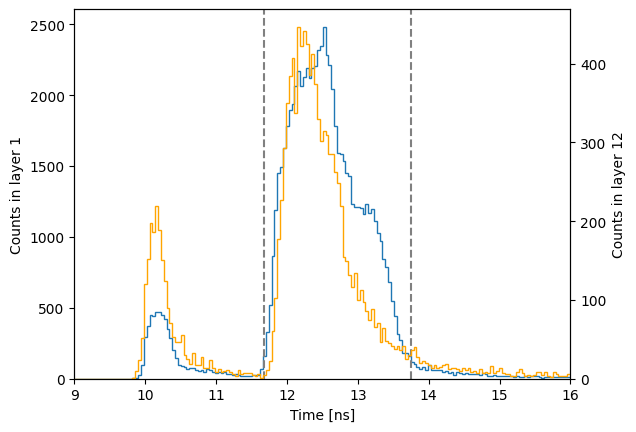

In [95]:
fig, ax1 = plt.subplots()
ax1.hist(time_array_layer_1, histtype="step", bins = bins_time, label = "layer 1")
#ax1.hist(time_array_layer_1_w2, histtype="step", bins = bins_time, label = "layer 1 (w2)")
#ax1.hist(time_array_layer_1_w3, histtype="step", bins = bins_time, label = "layer 1 (w3)")
#ax1.hist(time_array_layer_1_w4, histtype="step", bins = bins_time, label = "layer 1 (w4)")
#ax1.hist(time_array_layer_1_w5, histtype="step", bins = bins_time, label = "layer 1 (w5)")
#ax1.hist(time_array_layer_1_w6, histtype="step", bins = bins_time, label = "layer 1 (w6)")
#ax1.axvline(x = 12.5, linestyle = "--", color = "gray")
#ax1.axvline(x = 13.0, linestyle = "--", color = "gray")
#ax1.axvline(x = 13.5, linestyle = "--", color = "gray")
#ax1.axvline(x = 14.0, linestyle = "--", color = "gray")

ax1.axvline(x = lower_lim, linestyle = "--", color = "gray")
ax1.axvline(x = upper_lim, linestyle = "--", color = "gray")
#ax1.legend(loc = "upper left")

offset = 0.66

ax2 = ax1.twinx()
ax2.hist(np.array(time_array_layer_12), histtype="step", bins = bins_time, label = "layer 12", color = "orange")
#ax2.hist(np.array(time_array_layer_11), histtype="step", bins = bins_time, label = "layer 11", color = "green")
ax1.set_xlim(9,16)
#ax2.legend(loc = "upper right")
ax1.set_xlabel("Time [ns]")
ax1.set_ylabel("Counts in layer 1")
ax2.set_ylabel("Counts in layer 12")
#ax1.set_ylim(0, 510)#ax2.set_ylim(0, 250)
plt.show()

In [39]:
print("Mean value (planning, layer 1)", np.round(np.mean(time_array_layer_1_constrained), 4))
print("Mean value (w2, layer 1)", np.round(np.mean(time_array_layer_1_constrained_w2), 4))
print("Mean value (w3, layer 1)", np.round(np.mean(time_array_layer_1_constrained_w3), 4))
print("Mean value (w4, layer 1)", np.round(np.mean(time_array_layer_1_constrained_w4), 4))
print("Mean value (w5, layer 1)", np.round(np.mean(time_array_layer_1_constrained_w5), 4))
print("Mean value (w6, layer 1)", np.round(np.mean(time_array_layer_1_constrained_w6), 4))



print("Diff (w2 - planning) [ps]:", np.round(1000*(np.mean(time_array_layer_1_constrained_w2) - np.mean(time_array_layer_1_constrained)),2))
print("Diff (w3 - planning) [ps]:", np.round(1000*(np.mean(time_array_layer_1_constrained_w3) - np.mean(time_array_layer_1_constrained)),2))
print("Diff (w4 - planning) [ps]:", np.round(1000*(np.mean(time_array_layer_1_constrained_w4) - np.mean(time_array_layer_1_constrained)),2))
print("Diff (w5 - planning) [ps]:", np.round(1000*(np.mean(time_array_layer_1_constrained_w5) - np.mean(time_array_layer_1_constrained)),2))
print("Diff (w6 - planning) [ps]:", np.round(1000*(np.mean(time_array_layer_1_constrained_w6) - np.mean(time_array_layer_1_constrained)),2))

Mean value (planning, layer 1) 12.5582
Mean value (w2, layer 1) 12.5594
Mean value (w3, layer 1) 12.5706
Mean value (w4, layer 1) 12.5685
Mean value (w5, layer 1) 12.5709
Mean value (w6, layer 1) 12.565
Diff (w2 - planning) [ps]: 1.16
Diff (w3 - planning) [ps]: 12.34
Diff (w4 - planning) [ps]: 10.28
Diff (w5 - planning) [ps]: 12.69
Diff (w6 - planning) [ps]: 6.73


Max (planning): 12.4525
Max (w2): 12.4525
Max (w3): 12.5526
Max (w4): 12.5926
Max (w5): 12.5526
Max (w6): 12.5125
11.4 11.9


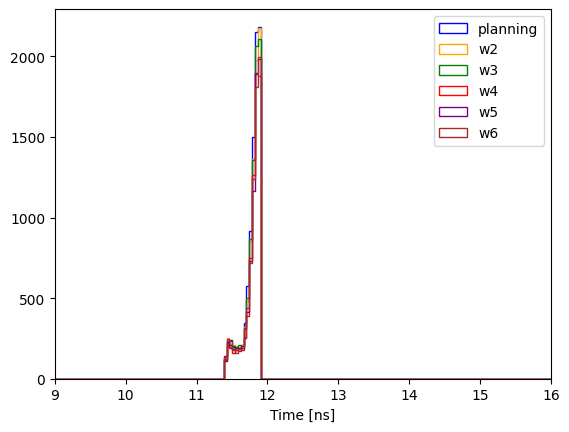

Diff (w2 - planning) [ps]: -3.17
Diff (w3 - planning) [ps]: -1.03
Diff (w4 - planning) [ps]: -1.88
Diff (w5 - planning) [ps]: -4.04
Diff (w6 - planning) [ps]: -4.69


In [132]:
mreg_array = hit_array_gamma[:,12]
mreg_array_w2 = hit_array_w2[:,12]
mreg_array_w3 = hit_array_w3[:,12]

llouse_list = hit_array_gamma[:,4]

time_array_mreg_1 = []
time_array_mreg_1_w2 = []
time_array_mreg_1_w3 = []

time_array_mreg_1_llouse_1 = []
time_array_lim = []
time_array_lim_w2 = []
time_array_lim_w3 = []
time_array_lim_w4 = []
time_array_lim_w5 = []
time_array_lim_w6 = []


time_array_ns = 1000*np.array(time_array)
time_array_ns_w2 = 1000*np.array(time_array_w2)
time_array_ns_w3 = 1000*np.array(time_array_w3)
time_array_ns_w4 = 1000*np.array(time_array_w4)
time_array_ns_w5 = 1000*np.array(time_array_w5)
time_array_ns_w6 = 1000*np.array(time_array_w6)
bins_time = np.linspace(0, 20, 1000)

counts,bins = np.histogram(time_array_ns, bins = bins_time)
max_time_idx = np.unravel_index(np.argmax(counts), counts.shape)[0]
max_time_plan = bins_time[max_time_idx]
print("Max (planning):", np.round(bins_time[max_time_idx],4))


#plt.plot(bins[:-1], counts, label = "planning")
#plt.axvline(x = bins_time[max_time_idx], color = "blue", linestyle = "--")
counts,bins = np.histogram(time_array_ns_w2, bins = bins_time)
max_time_idx = np.unravel_index(np.argmax(counts), counts.shape)[0]
print("Max (w2):", np.round(bins_time[max_time_idx],4))


counts,bins = np.histogram(time_array_ns_w3, bins = bins_time)
max_time_idx = np.unravel_index(np.argmax(counts), counts.shape)[0]
print("Max (w3):", np.round(bins_time[max_time_idx],4))

counts,bins = np.histogram(time_array_ns_w4, bins = bins_time)
max_time_idx = np.unravel_index(np.argmax(counts), counts.shape)[0]
print("Max (w4):", np.round(bins_time[max_time_idx],4))

#plt.plot(bins[:-1, ], counts, color = "orange", label = "w3")
#plt.axvline(x = bins_time[max_time_idx], color = "orange", linestyle = "--")

counts,bins = np.histogram(time_array_ns_w5, bins = bins_time)
max_time_idx = np.unravel_index(np.argmax(counts), counts.shape)[0]
print("Max (w5):", np.round(bins_time[max_time_idx],4))

counts,bins = np.histogram(time_array_ns_w6, bins = bins_time)
max_time_idx = np.unravel_index(np.argmax(counts), counts.shape)[0]
print("Max (w6):", np.round(bins_time[max_time_idx],4))
'''plt.plot(bins[:-1, ], counts, color = "green",label = "w6")
plt.axvline(x = bins_time[max_time_idx], color = "green", linestyle = "--", label = str(bins_time[max_time_idx]))
print(bins_time[max_time_idx])
plt.legend()
plt.xlim(8,16)
plt.show()'''


time_depth = 5
time_depth_upper = 5

lower = 11.4 #max_time_plan - 0.95
upper = 11.9 #max_time_plan

print(lower, upper)


for i in range(len(time_array_ns)):
    if time_array_ns[i] > lower and time_array_ns[i] < upper: 
        time_array_lim.append(time_array_ns[i])

for i in range(len(time_array_ns_w2)):
    if time_array_ns_w2[i] >lower and time_array_ns_w2[i] < upper: 
        time_array_lim_w2.append(time_array_ns_w2[i])

for i in range(len(time_array_ns_w3)):
    if time_array_ns_w3[i] > lower and time_array_ns_w3[i] < upper: 
        time_array_lim_w3.append(time_array_ns_w3[i])

for i in range(len(time_array_ns_w4)):
    if time_array_ns_w4[i] > lower and time_array_ns_w4[i] < upper: 
        time_array_lim_w4.append(time_array_ns_w4[i])

for i in range(len(time_array_ns_w5)):
    if time_array_ns_w5[i] > lower and time_array_ns_w5[i] < upper: 
        time_array_lim_w5.append(time_array_ns_w5[i])

for i in range(len(time_array_ns_w6)):
    if time_array_ns_w6[i] > lower and time_array_ns_w6[i] < upper: 
        time_array_lim_w6.append(time_array_ns_w6[i])






'''
for i in range(len(mreg_array)):
    if mreg_array[i] == 1.0:
        time_array_mreg_1.append(time_array[i])
    if mreg_array[i] == 1.0 and llouse_list[i] == 1.0:
        time_array_mreg_1_llouse_1.append(time_array[i])

for i in range(len(mreg_array_w2)):
    if mreg_array_w2[i] == 1.0:
        time_array_mreg_1_w2.append(time_array_w2[i])

for i in range(len(mreg_array_w3)):
    if mreg_array_w3[i] == 1.0:
        time_array_mreg_1_w3.append(time_array_w3[i])'''

bins_time = np.linspace(0, 20, 500)


#plt.hist(1000*np.array(time_array), histtype="step", bins = bins_time, label = "planning")
plt.hist(time_array_lim, histtype="step", bins = bins_time, label = "planning", color = "blue")
plt.hist(time_array_lim_w2, histtype="step", bins = bins_time, label = "w2",  color = "orange")
plt.hist(time_array_lim_w3, histtype="step", bins = bins_time, label = "w3", color = "green")
plt.hist(time_array_lim_w4, histtype="step", bins = bins_time, label = "w4", color = "red")
plt.hist(time_array_lim_w5, histtype="step", bins = bins_time, label = "w5", color = "purple")
plt.hist(time_array_lim_w6, histtype="step", bins = bins_time, label = "w6", color = "brown")
#plt.hist(1000*np.array(time_array_w2), histtype="step", bins = bins_time, label = "w2")
#plt.hist(1000*np.array(time_array_w3), histtype="step", bins = bins_time, label = "w3", alpha = 0.5)
plt.xlabel("Time [ns]")
#plt.axvline(x = np.mean(time_array_lim), linestyle = "--", color = "blue", label = float(np.round(np.mean(time_array_lim),4)))
#plt.axvline(x = np.mean(time_array_lim_w4), linestyle = "--", color = "purple", label = float(np.round(np.mean(time_array_lim_w4),4)))
#plt.axvline(x = np.mean(time_array_lim_w3), linestyle = "--", color = "green", label = float(np.round(np.mean(time_array_lim_w3),4)))
plt.legend()
plt.xlim(9, 16)
#plt.axvline(x = 12.8, linestyle = "--", color = "gray")


plt.show()

'''
plt.hist(1000*np.array(time_array_mreg_1), histtype="step", bins = bins_time, label = "planning")
#plt.hist(1000*np.array(time_array_mreg_1_llouse_1), histtype="step", bins = bins_time, label = "mreg 1 llouse 1")
#plt.hist(1000*np.array(time_array_mreg_1_w2), histtype="step", bins = bins_time, label = "w2")
#plt.hist(1000*np.array(time_array_mreg_1_w3), histtype="step", bins = bins_time, label = "w3", alpha = 0.5)
plt.legend()
#plt.axvline(x = 12.3, linestyle = "--", color = "gray")
plt.axvline(x = 12.8, linestyle = "--", color = "gray")
plt.xlabel("Time [ns]")
plt.xlim(10, 17.5)
plt.show()'''

#print(np.round(np.mean(time_array_lim),4), np.round(np.std(time_array_lim),4))
#print(np.round(np.mean(time_array_lim_w2),4), np.round(np.std(time_array_lim_w2),4))
#print(np.round(np.mean(time_array_lim_w3),4), np.round(np.std(time_array_lim_w3),4))

print("Diff (w2 - planning) [ps]:", np.round(1000*(np.mean(time_array_lim_w2) - np.mean(time_array_lim)),2))
print("Diff (w3 - planning) [ps]:", np.round(1000*(np.mean(time_array_lim_w3) - np.mean(time_array_lim)),2))
print("Diff (w4 - planning) [ps]:", np.round(1000*(np.mean(time_array_lim_w4) - np.mean(time_array_lim)),2))
print("Diff (w5 - planning) [ps]:", np.round(1000*(np.mean(time_array_lim_w5) - np.mean(time_array_lim)),2))
print("Diff (w6 - planning) [ps]:", np.round(1000*(np.mean(time_array_lim_w6) - np.mean(time_array_lim)),2))






#print("Diff (w3 - w2) [ps]:", np.round(1000*(np.mean(time_array_lim_w3) - np.mean(time_array_lim_w2)),2))

In [35]:
bins_time = np.linspace(0, 20, 500)

counts,bins = np.histogram(time_array_ns, bins = bins_time)
max_time_idx = np.unravel_index(np.argmax(counts), counts.shape)[0]
print(bins_time[max_time_idx])
plt.plot(bins[:-1], counts, label = "planning")
plt.axvline(x = bins_time[max_time_idx], color = "blue", linestyle = "--", label = str(np.round(bins_time[max_time_idx],3),))
plt.xlim(8,16)
plt.show()
counts,bins = np.histogram(time_array_ns_w2, bins = bins_time)
max_time_idx = np.unravel_index(np.argmax(counts), counts.shape)[0]
print(bins_time[max_time_idx])
plt.plot(bins[:-1, ], counts, color = "orange", label = "w2")
plt.axvline(x = bins_time[max_time_idx], color = "orange", linestyle = "--", label = str(np.round(bins_time[max_time_idx],3),))
plt.xlim(8,16)
plt.show()

counts,bins = np.histogram(time_array_ns_w3, bins = bins_time)
max_time_idx = np.unravel_index(np.argmax(counts), counts.shape)[0]
print(bins_time[max_time_idx])
plt.plot(bins[:-1, ], counts, color = "green", label = "w3")
plt.axvline(x = bins_time[max_time_idx], color = "green", linestyle = "--", label = str(np.round(bins_time[max_time_idx],3),))
plt.xlim(8,16)
plt.show()

counts,bins = np.histogram(time_array_ns_w4, bins = bins_time)
max_time_idx = np.unravel_index(np.argmax(counts), counts.shape)[0]
print(bins_time[max_time_idx])
plt.plot(bins[:-1, ], counts, color = "red", label = "w4")
plt.axvline(x = bins_time[max_time_idx], color = "red", linestyle = "--", label = str(np.round(bins_time[max_time_idx],3),))
plt.xlim(8,16)
plt.show()

counts,bins = np.histogram(time_array_ns_w5, bins = bins_time)
max_time_idx = np.unravel_index(np.argmax(counts), counts.shape)[0]
print(bins_time[max_time_idx])
plt.plot(bins[:-1, ], counts, color = "purple", label = "w5")
plt.axvline(x = bins_time[max_time_idx], color = "purple", linestyle = "--", label = str(np.round(bins_time[max_time_idx],3),))
plt.xlim(8,16)
plt.show()





counts,bins = np.histogram(time_array_ns_w6, bins = bins_time)
max_time_idx = np.unravel_index(np.argmax(counts), counts.shape)[0]
print(bins_time[max_time_idx])
plt.plot(bins[:-1, ], counts, color = "brown" ,label = "w6")
plt.axvline(x = bins_time[max_time_idx], color = "brown", linestyle = "--", label = str(np.round(bins_time[max_time_idx],3),))
print(bins_time[max_time_idx])
plt.legend()
plt.xlim(8,16)
plt.show()

NameError: name 'time_array_ns' is not defined

In [54]:
mreg_array = hit_array[:,12]
mreg_array_w2 = hit_array_w2[:,12]
energy_dep_reg_1 = []
energy_dep_reg_1_w2 = []

for i in range(len(mreg_array)):
    if mreg_array[i] == 1.0:
        energy_dep_reg_1.append(energy_dep[i])

for i in range(len(mreg_array_w2)):
    if mreg_array_w2[i] == 1.0:
        energy_dep_reg_1_w2.append(energy_dep_w2[i])

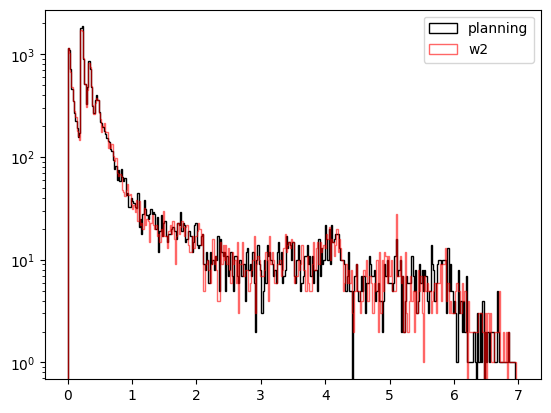

In [56]:
bins = np.linspace(0, 7, 350)

plt.hist(energy_dep_reg_1, bins = bins, histtype="step", label = "planning", color = "black")
plt.hist(energy_dep_reg_1_w2, bins = bins, histtype="step", label = "w2", color = "red", alpha = 0.6)
plt.yscale("log")
plt.legend()

plt.show()

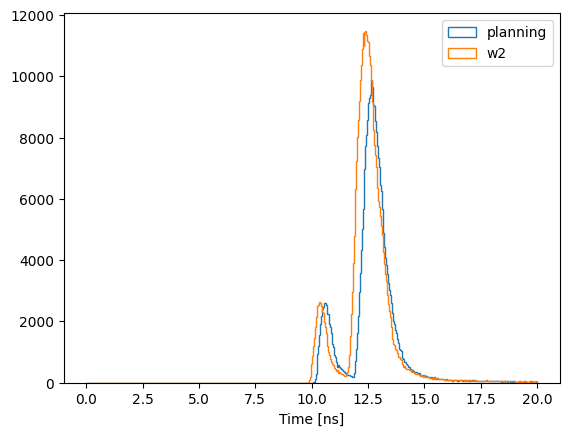

12.8067 0.4454


In [7]:
time_array = hit_array[:,14]
time_array_w2 = hit_array_w2[:,14]

mreg_array = hit_array[:,12]

llouse_list = hit_array[:,4]


time_array_lim = []
time_array_lim_w2 = []
time_array_lim_w3 = []


time_array_ns = 1000*np.array(time_array)


for i in range(len(time_array_ns)):
    if time_array_ns[i] > 11.5 and time_array_ns[i] < 14.0:
        time_array_lim.append(time_array_ns[i])




bins_time = np.linspace(0, 20, 500)


plt.hist(1000*np.array(time_array), histtype="step", bins = bins_time, label = "planning")
plt.hist(1000*np.array(time_array_w2), histtype="step", bins = bins_time, label = "w2")
#plt.hist(time_array_lim, histtype="step", bins = bins_time, label = "planning", color = "blue")
#plt.hist(time_array_lim_w2, histtype="step", bins = bins_time, label = "w2",  color = "red")
#plt.hist(time_array_lim_w3, histtype="step", bins = bins_time, label = "w3", color = "green")
#plt.hist(1000*np.array(time_array_w2), histtype="step", bins = bins_time, label = "w2")
#plt.hist(1000*np.array(time_array_w3), histtype="step", bins = bins_time, label = "w3", alpha = 0.5)
plt.xlabel("Time [ns]")
#plt.axvline(x = np.mean(time_array_lim), linestyle = "--", color = "blue", label = float(np.round(np.mean(time_array_lim),4)))
#plt.axvline(x = np.mean(time_array_lim_w2), linestyle = "--", color = "red", label = float(np.round(np.mean(time_array_lim_w2),4)))
#plt.axvline(x = np.mean(time_array_lim_w3), linestyle = "--", color = "green", label = float(np.round(np.mean(time_array_lim_w3),4)))
plt.legend()
#plt.axvline(x = 12.8, linestyle = "--", color = "gray")
#plt.xlim(11.5, 14)
plt.show()

'''
plt.hist(1000*np.array(time_array_mreg_1), histtype="step", bins = bins_time, label = "planning")
#plt.hist(1000*np.array(time_array_mreg_1_llouse_1), histtype="step", bins = bins_time, label = "mreg 1 llouse 1")
#plt.hist(1000*np.array(time_array_mreg_1_w2), histtype="step", bins = bins_time, label = "w2")
#plt.hist(1000*np.array(time_array_mreg_1_w3), histtype="step", bins = bins_time, label = "w3", alpha = 0.5)
plt.legend()
#plt.axvline(x = 12.3, linestyle = "--", color = "gray")
plt.axvline(x = 12.8, linestyle = "--", color = "gray")
plt.xlabel("Time [ns]")
plt.xlim(10, 17.5)
plt.show()'''

print(np.round(np.mean(time_array_lim),4), np.round(np.std(time_array_lim),4))
#print(np.round(np.mean(time_array_lim_w2),4), np.round(np.std(time_array_lim_w2),4))
#print(np.round(np.mean(time_array_lim_w3),4), np.round(np.std(time_array_lim_w3),4))

#print("Diff (w2 - planning) [ps]:", np.round(1000*(np.mean(time_array_lim_w2) - np.mean(time_array_lim)),2))
#print("Diff (w3 - planning) [ps]:", np.round(1000*(np.mean(time_array_lim_w3) - np.mean(time_array_lim)),2))
#print("Diff (w3 - w2) [ps]:", np.round(1000*(np.mean(time_array_lim_w3) - np.mean(time_array_lim_w2)),2))

1.0


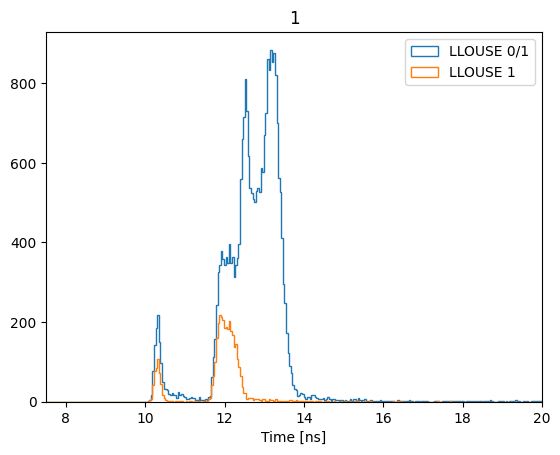

2.0


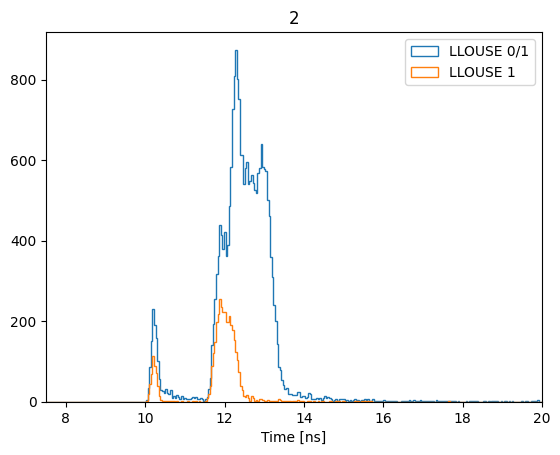

3.0


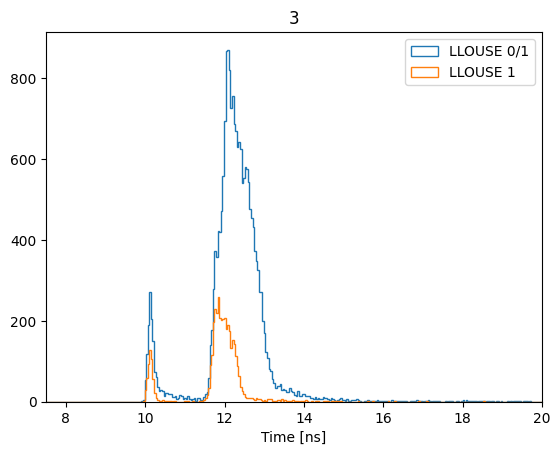

4.0


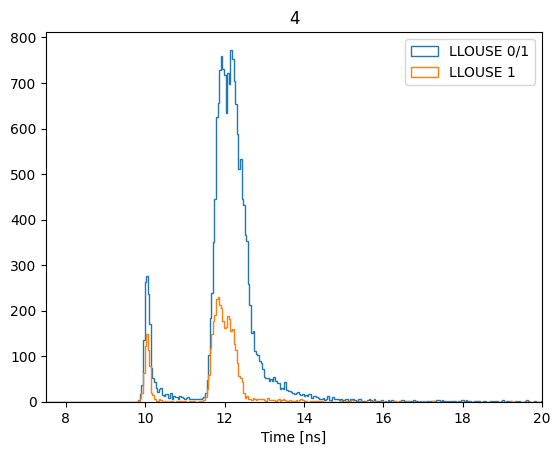

5.0


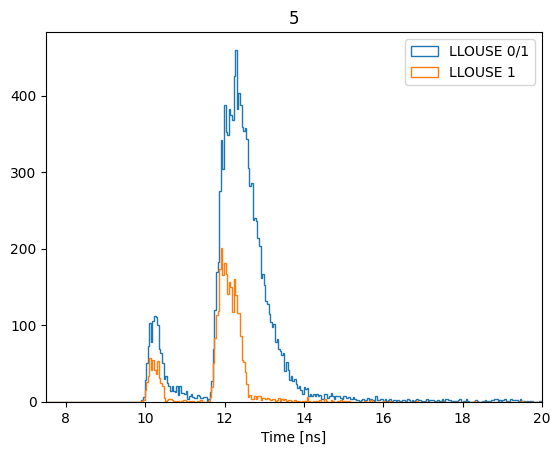

6.0


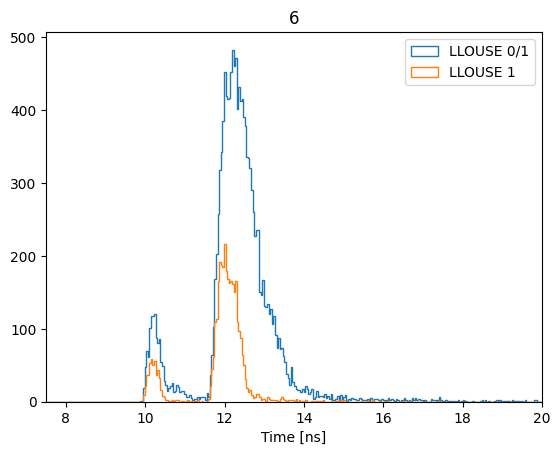

7.0


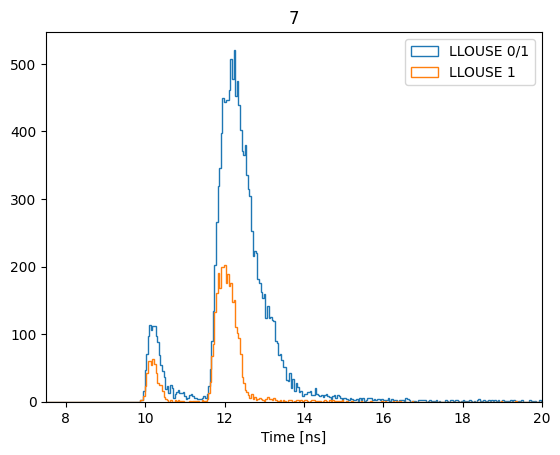

8.0


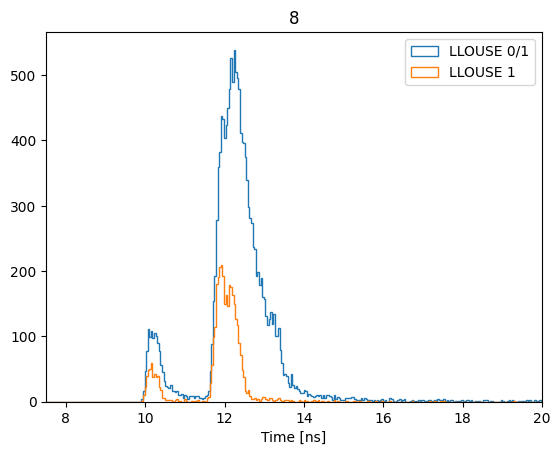

9.0


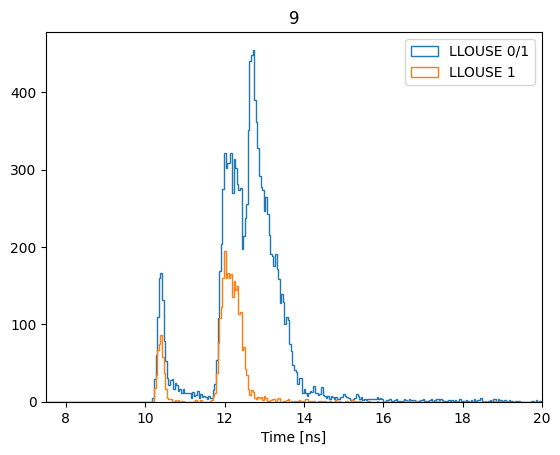

10.0


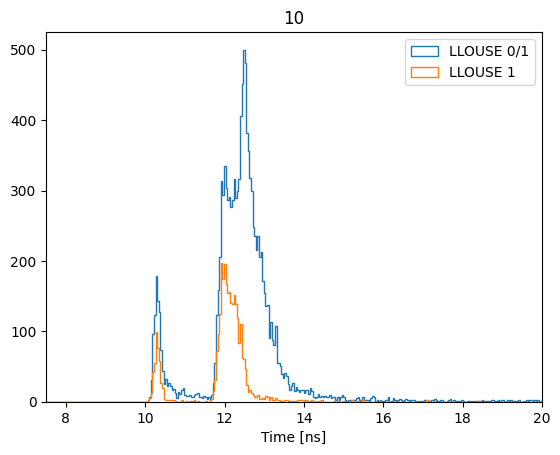

11.0


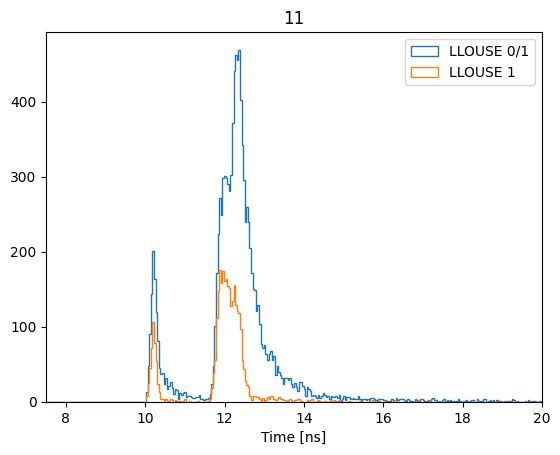

12.0


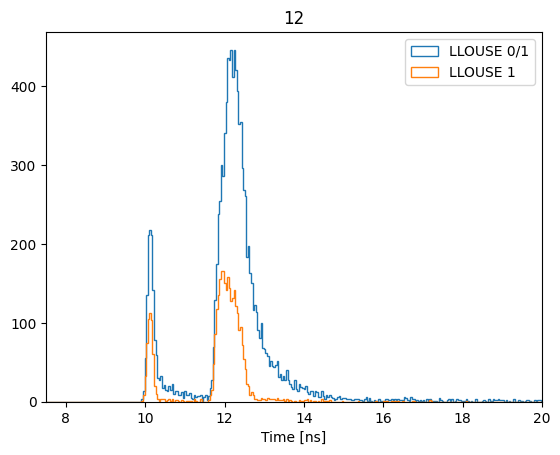

13.0


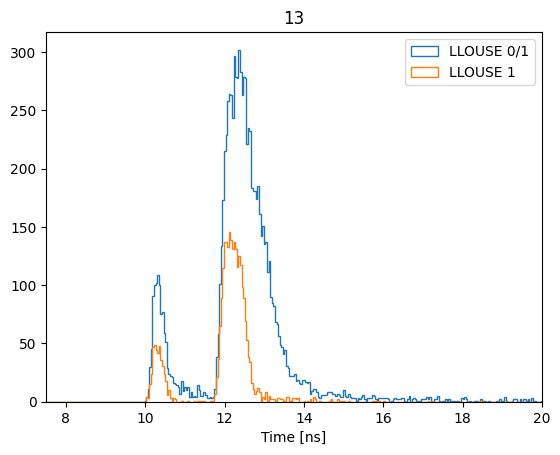

14.0


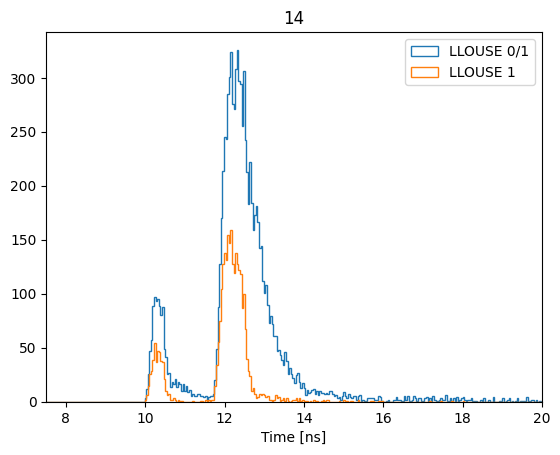

15.0


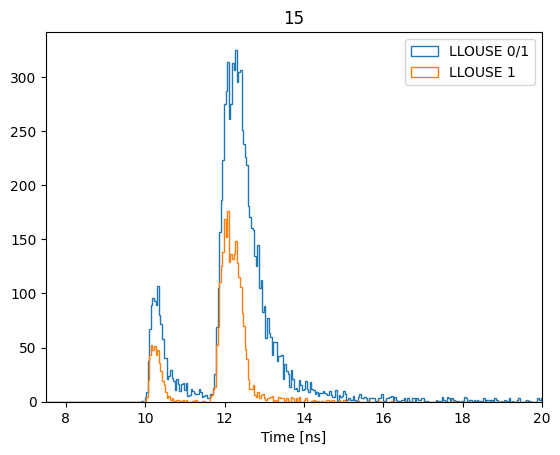

16.0


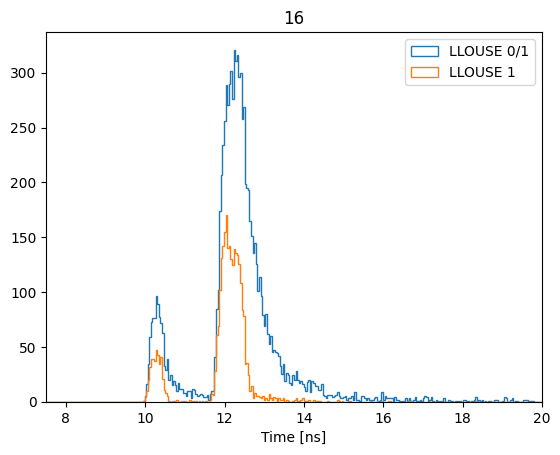

17.0


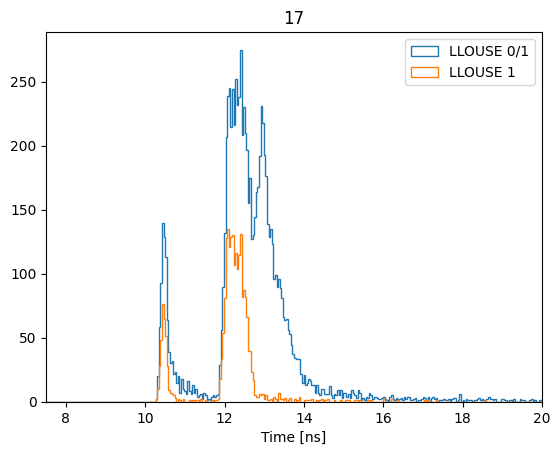

18.0


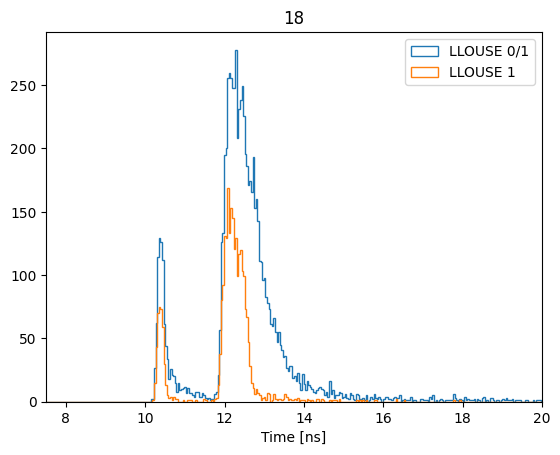

19.0


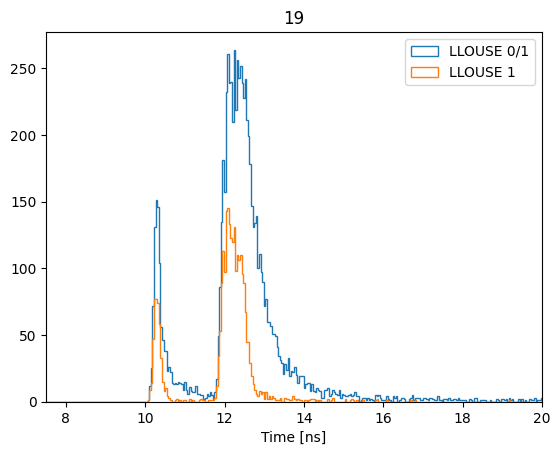

20.0


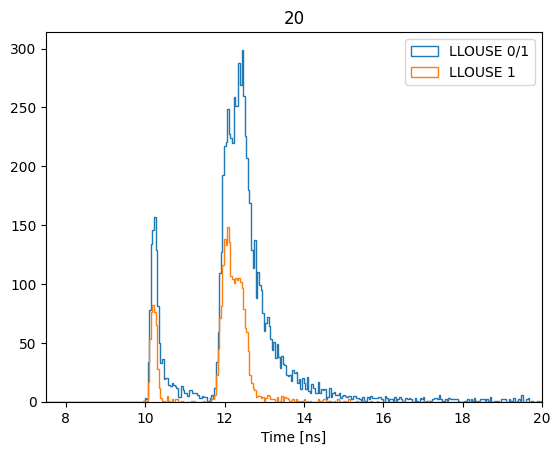

21.0


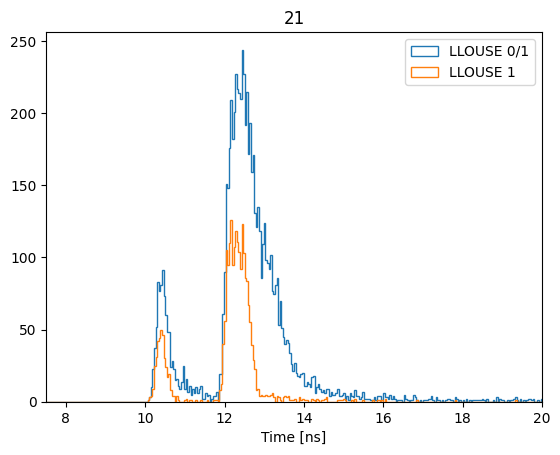

22.0


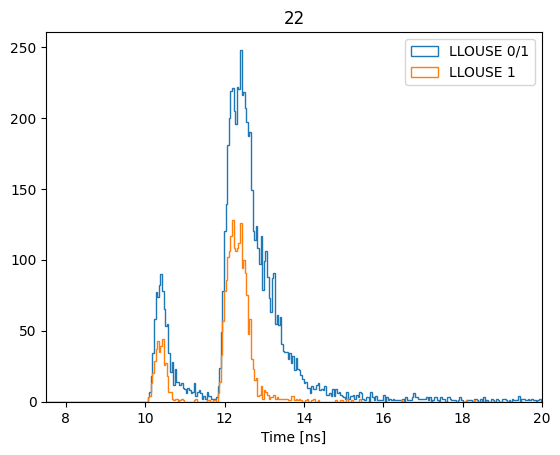

23.0


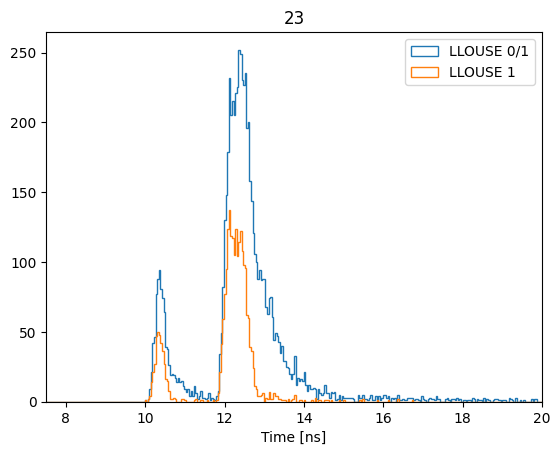

24.0


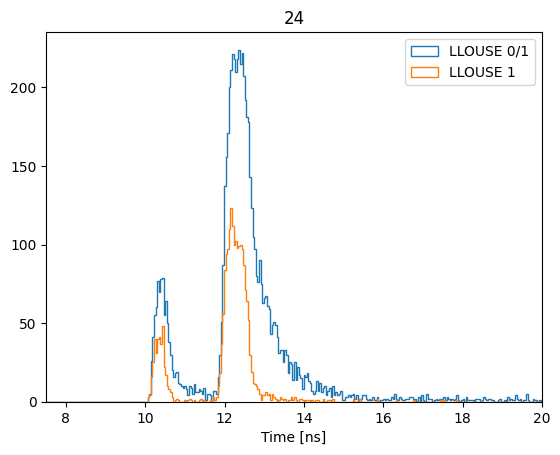

25.0


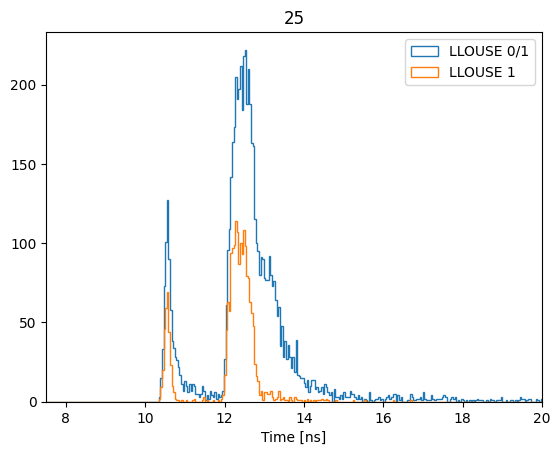

26.0


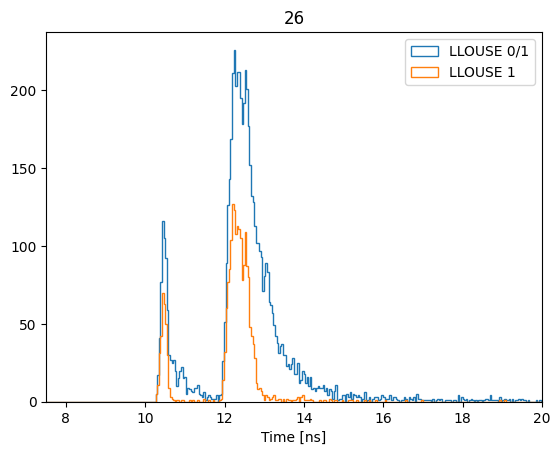

27.0


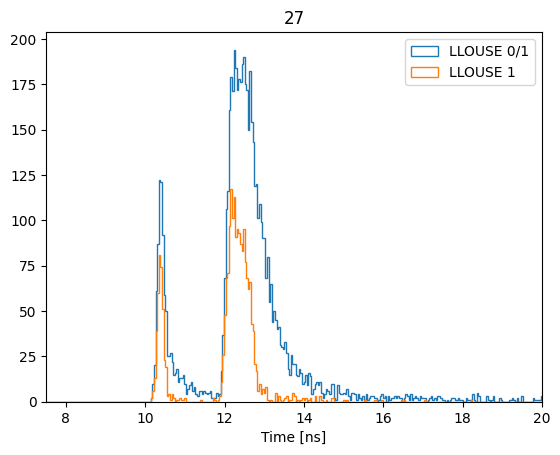

28.0


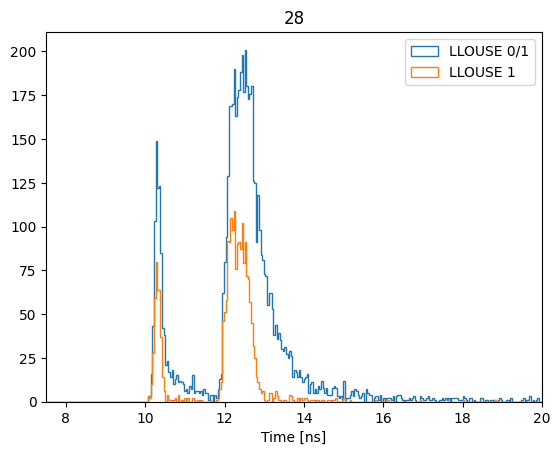

29.0


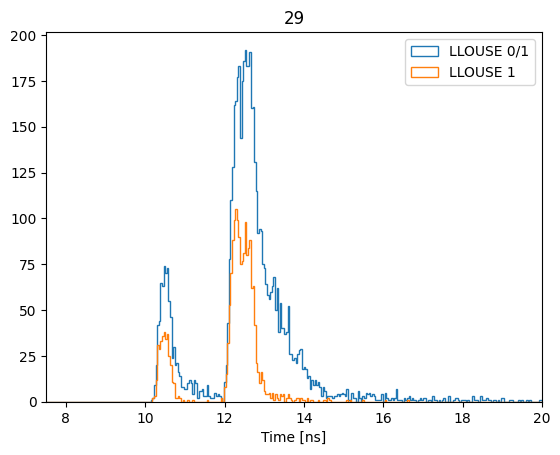

30.0


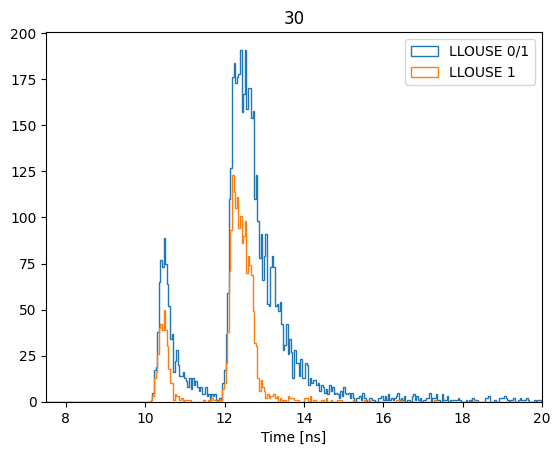

31.0


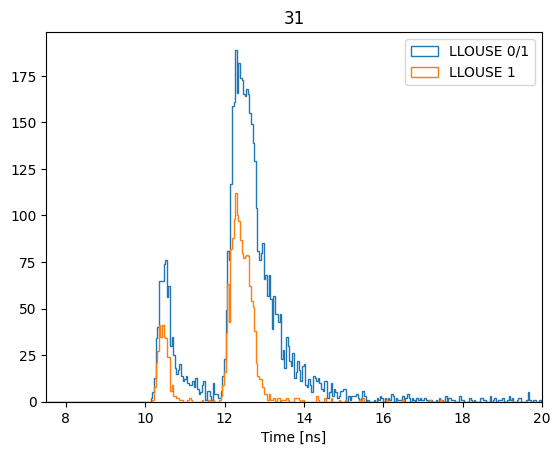

32.0


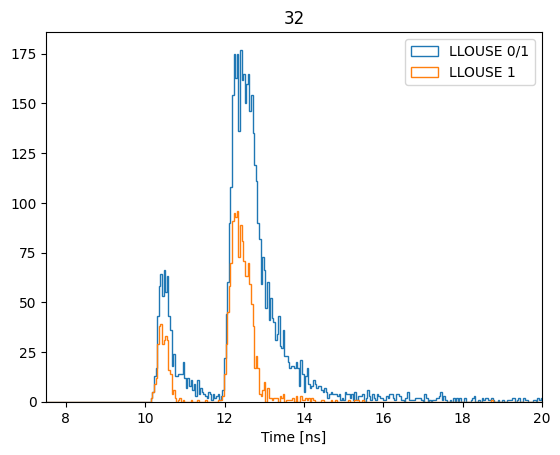

33.0


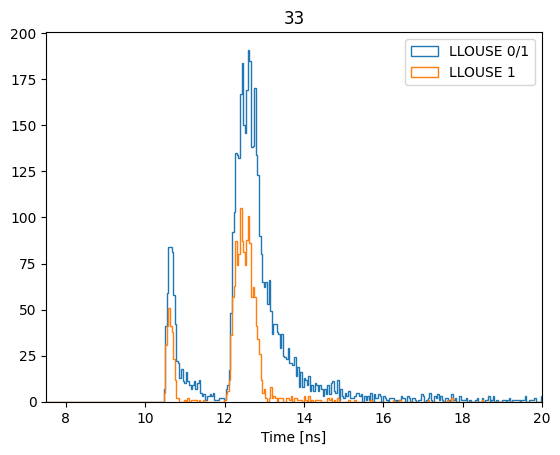

34.0


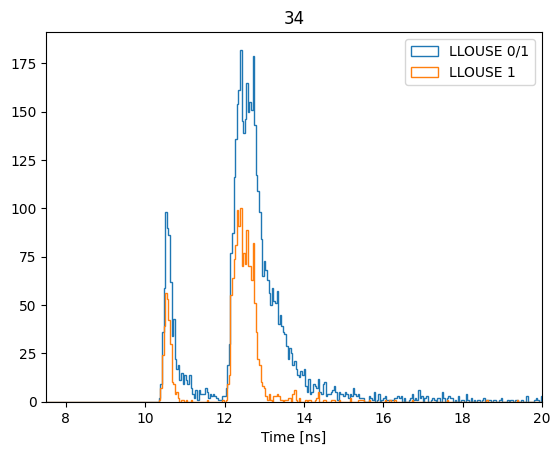

35.0


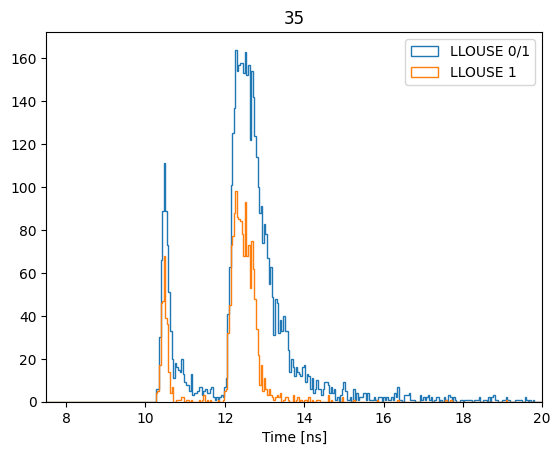

36.0


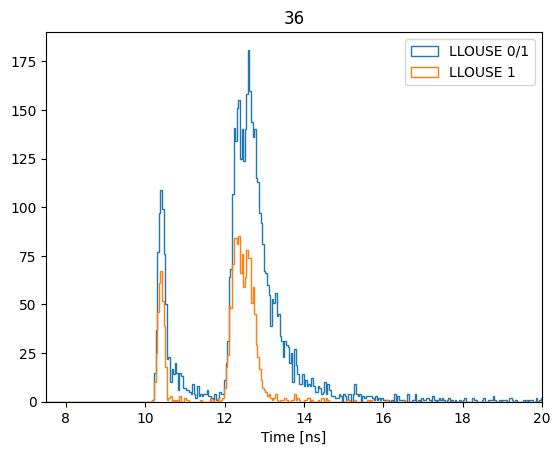

37.0


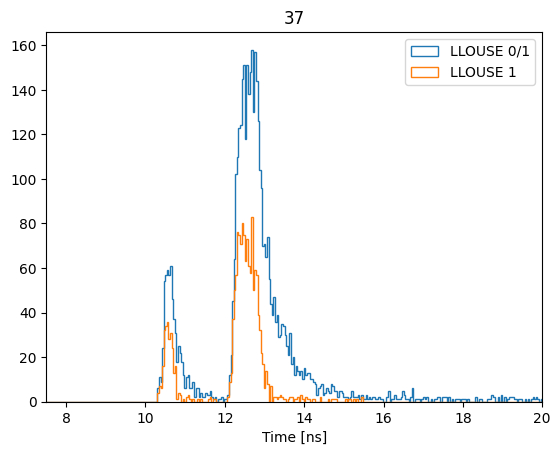

38.0


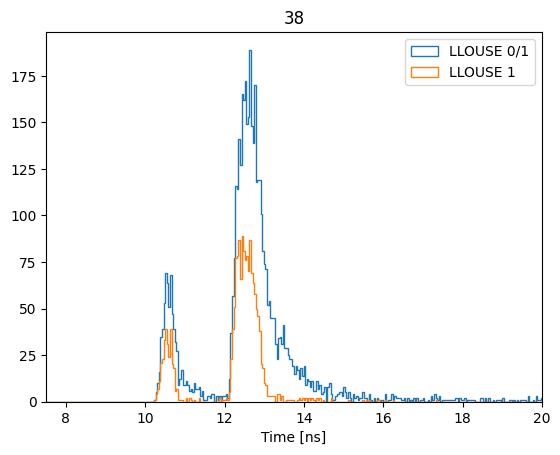

39.0


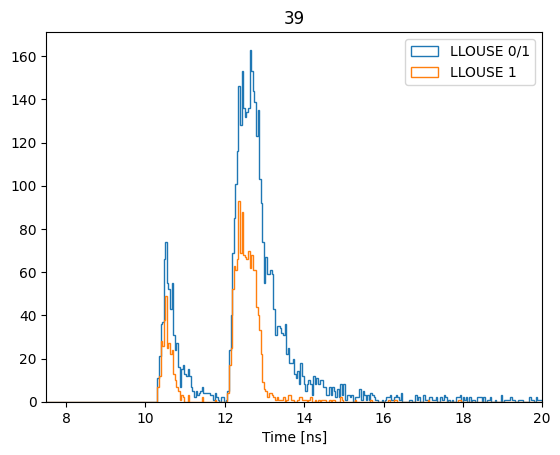

40.0


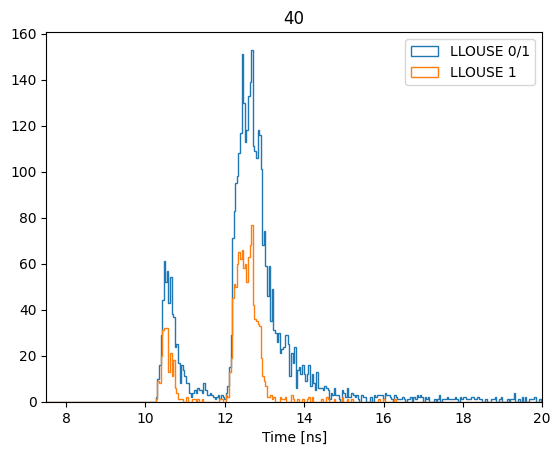

41.0


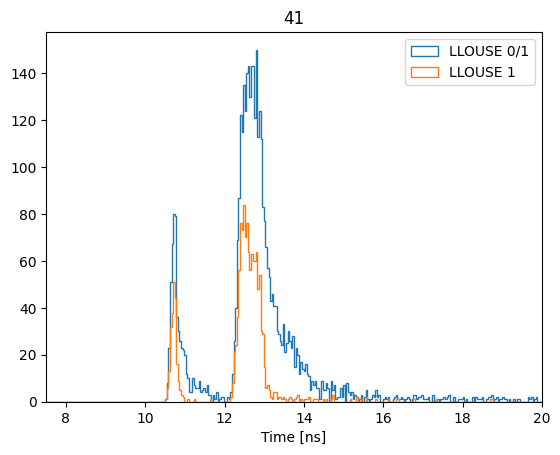

42.0


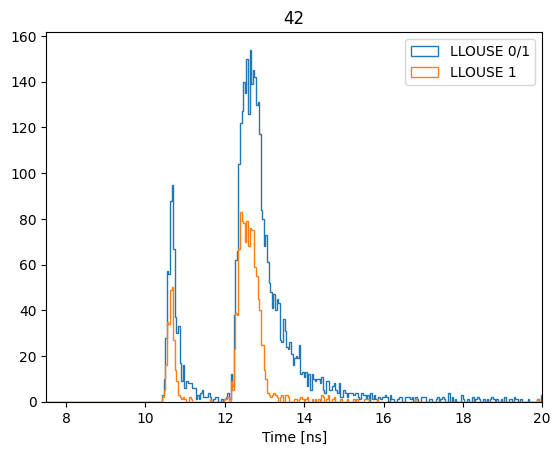

43.0


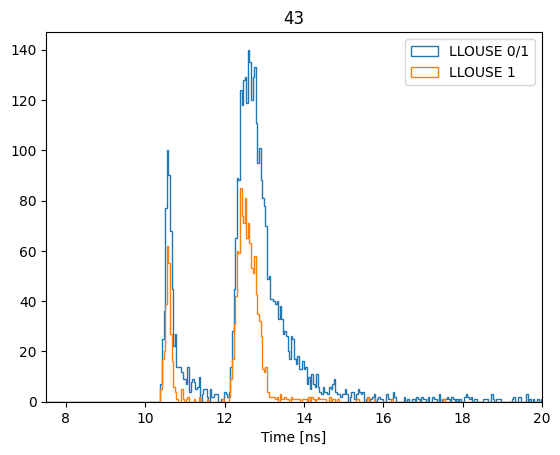

44.0


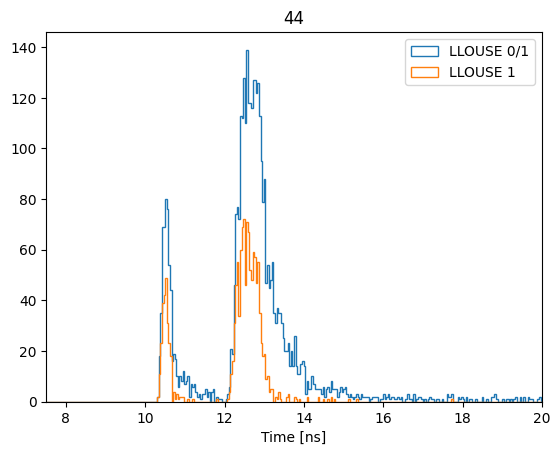

45.0


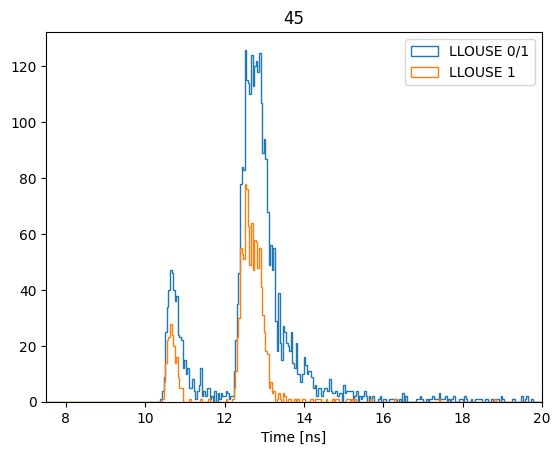

46.0


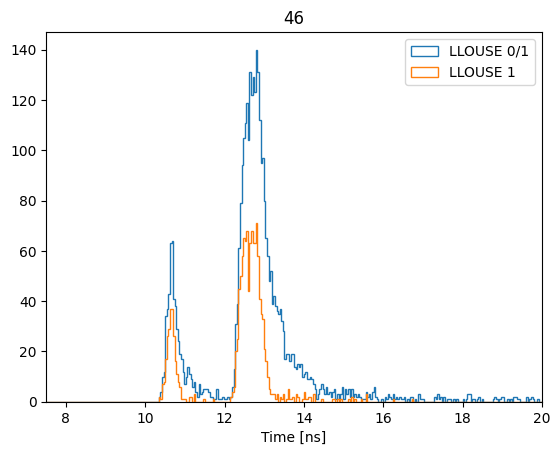

47.0


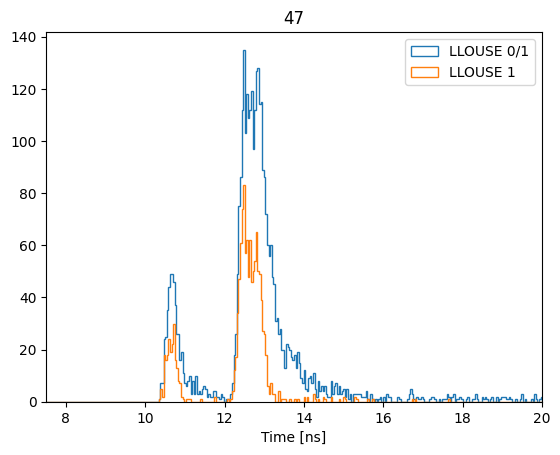

In [73]:
llouse_list = hit_array[:, 4]

for i in range(1, 48):
    #plt.figure()
    time_array_mreg_i = []
    time_array_mreg_i_llouse_1 = []
    print(float(i))

    for j in range(len(mreg_array)):
        if mreg_array[j] == float(i):
            time_array_mreg_i.append(time_array[j])
        if mreg_array[j] == float(i) and llouse_list[j] == 1.0:
            time_array_mreg_i_llouse_1.append(time_array[j])
    
    plt.hist(1000*np.array(time_array_mreg_i), histtype="step", bins = bins_time, label = "LLOUSE 0/1")
    plt.hist(1000*np.array(time_array_mreg_i_llouse_1), histtype="step", bins = bins_time, label = "LLOUSE 1")

    plt.legend()
    plt.title(str(i))

    plt.xlabel("Time [ns]")
    plt.xlim(7.5, 20)
    plt.show()

In [3]:
print(hit_array[0,0], hit_array[0,18])
print(hit_array[1,0], hit_array[1,18])

2261.0 1197.0
9414.0 57.0


In [46]:
def save_as_nifti(hist, output_file, nifti_image):
    ref_img = nib.load(nifti_image)
    ref_affine = ref_img.affine

    ref_affine[0][0] = -1
    ref_affine[1][1] = -1

    your_volume = hist.astype(np.float32)
    new_img = nib.Nifti1Image(your_volume, ref_affine)

    nib.save(new_img, output_file)

In [83]:
XSCO_prod_ = hit_array[:, 15]
YSCO_prod_ = hit_array[:, 16]
ZSCO_prod_ = hit_array[:, 17]

species = hit_array[:, 2]
llouse_list = hit_array[:, 4]
time_array_ns = 1000*np.array(hit_array[:,14])


PG_coordinates = []
#PG_coordinates_time_check = []


FN_coordinates = []

for i in range(len(species)):
    #if species[i] == 7.0 and llouse_list[i] == 1.0:
     #   PG_coordinates.append(np.array([XSCO_prod_[i], YSCO_prod_[i],ZSCO_prod_[i]]))
    if species[i] == 7.0 and time_array_ns[i] < 11.5 and llouse_list[i] == 1.0: #and mreg_array[i] == 1.0 and time_array_ns[i] > 12.8 :
        PG_coordinates.append(np.array([XSCO_prod_[i], YSCO_prod_[i],ZSCO_prod_[i]]))


coordinates_pg = np.array(PG_coordinates)
volume_shape = (573, 315, 117)

#NBNBNB: if actually used further these needs to be doublechecked - not done
min_coords = [-27.719, -12.852159, -18.459676]
max_coords = [29.5809999, 18.64784, 16.640324]

edges = [np.linspace(min_coords[i], max_coords[i], volume_shape[i]+1) for i in range(3)]

hist_pg,_ = np.histogramdd(coordinates_pg, bins = edges)

planning_overall_path = r"C:\Users\amibe\OneDrive\Documentos\NOVO\Study3_HNC\Data_test_tog\nifti\planning\Results_spot_50"
pg_path = planning_overall_path + "/" + "pg.nii.gz"

output_file = r"C:\Users\amibe\OneDrive\Documentos\NOVO\Study3_HNC\Data_test_tog\scintillator_interactions\planning\Results_spot_50\pg_mreg1_less_11_5.nii.gz"

save_as_nifti(hist_pg,output_file,nifti_image= pg_path)


(np.int64(252), np.int64(68), np.int64(78))


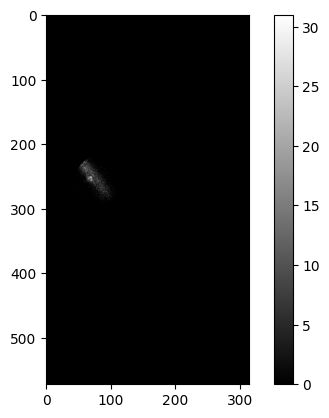

In [45]:
print(np.unravel_index(np.argmax(hist_pg), hist_pg.shape))

slice = hist_pg[:,:,78]

plt.figure()
plt.imshow(slice, cmap = "gray")
plt.colorbar()
plt.show()